# Final Project Data Science Basic - Kelompok 7
### Prioritisasi Pasar UMKM untuk Klay (PT Skalar Solutions): dari data mentah sampai rekomendasi untuk tim Sales

Satu notebook terintegrasi: **cleaning, merging, EDA, K-Means, indeks ICP, baseline, uji sensitivitas, Tabel 1, Tabel 2, dan strategi SDR**, semuanya sudah dieksekusi. Data mentah dibundel di dalam notebook, jadi notebook bisa dijalankan ulang dari atas ke bawah tanpa upload file apa pun (Runtime > Run all di Google Colab).

**Kasus:** menentukan sektor dan wilayah UMKM yang paling layak jadi target awal sourcing leads Klay (aplikasi kasir + analitik). **Wilayah:** Jawa Barat, tahun acuan 2023.

| Bagian notebook | Isi | Jawaban untuk instruksi Final Project |
|---|---|---|
| I (I.1 sampai I.8) | Sumber data, cleaning, merging hierarki (provinsi vs kab/kota), pemetaan sektor, filter penggugur, normalisasi Min-Max, EDA, rancangan bobot | Bagian 1: fondasi data dan refinement EDA |
| A, B | Fitur siap model, K-Means (Elbow, Silhouette, pemilihan k, profil dan label klaster) | Bagian 2: pemodelan K-Means |
| C | Skor ICP sektor x wilayah, sintesis dengan klaster, baseline, uji sensitivitas bobot dan skala | Bagian 3: indeks ICP dan analisis sensitivitas |
| D | Tabel 1 (Top 5 segmen) dan Tabel 2 (legalitas scraping) | Bagian 4: deliverables |
| E, F | Strategi SDR (lead qualification, gelombang wilayah, ilustrasi efisiensi) dan keterbatasan | Bagian 5: business insights dan SDR actionable strategy |

Bagian 6 (slide pitch deck) dan laporan PDF disusun terpisah dari hasil notebook ini.

**Identitas tim:** ketiga anggota berkontribusi sama rata; peran di bawah hanya menunjukkan penanggung jawab utama.

| Kelompok | Nama anggota | Peran |
|---|---|---|
| 7 | Nabila Ayuningtiyas | Data Collection & Understanding; analisis kelaikan scraping (robots.txt dan ToS); strategi SDR dan lead qualification |
| 7 | Valent Danika Maulidya | Data Preparation; pemodelan K-Means dan profil klaster; penyusunan laporan dan notebook terintegrasi |
| 7 | Nayla Marsha Azizah | EDA; ICP Weight Matrix; skor ICP, baseline, dan uji sensitivitas; tabel Top 5 segmen |

**Asumsi yang dipakai:**
1. 24 wilayah lolos filter (Kota Sukabumi, Kota Cirebon, Kota Banjar gugur karena UMKM < 1% total Jawa Barat).
2. Sektor sasaran: F&B dan Jasa (proksi). Ritel tidak terukur karena data tidak punya kategori ritel.
3. Bobot ICP: Ukuran pasar 30%, Kepadatan sektor 25%, Kesiapan digital 25%, Aktivitas ekonomi 20% (Bagian I.8). Komponen pembayaran digital (QRIS) kosong karena datanya tidak ada per kabupaten/kota.
4. Unit analisis adalah **segmen = sektor x wilayah** (48 segmen). Komponen Ukuran pasar dan Kepadatan sektor dihitung **per sektor**, bukan gabungan F&B + Jasa.

In [1]:
#@title Muat data mentah (dibundel di dalam notebook, tidak perlu upload)
# Urutan pencarian: (1) folder data_mentah di samping notebook, (2) DATA_URL bila diisi (mis. link ZIP di GitHub/Drive publik),
# (3) salinan yang dibundel di sel ini. Isi DATA_URL hanya kalau ingin mengganti data dengan versi lain.
import base64, io, os, zipfile, urllib.request
DATA_URL = ""        # contoh: "https://github.com/<akun>/<repo>/raw/main/FinalProject_DS_Kelompok07_data.zip"
DATA_B64 = "..."
if not os.path.isdir("data_mentah"):
    zbytes = None
    if DATA_URL:
        try: zbytes = urllib.request.urlopen(DATA_URL, timeout=30).read()
        except Exception as e: print("DATA_URL gagal dibuka, pakai salinan bundel:", e)
    if zbytes is None: zbytes = base64.b64decode(DATA_B64)
    zipfile.ZipFile(io.BytesIO(zbytes)).extractall(".")
print("data_mentah:", sorted(os.listdir("data_mentah")))

data_mentah: ['desa_akses_internet_2021_2024.csv', 'desa_internet_kantor_desa_2020_2024.csv', 'desa_tower_bts_2020_2024.csv', 'industri_mikro_kecil_2023_bps_mentah.csv', 'internet_provinsi_2023_bps_mentah.csv', 'pdrb_per_kapita_2023.csv', 'pemuda_teknologi_2023.csv', 'penduduk_2023_dalam_angka_tabel_3_1_3.csv', 'provinsi_jabar_2023.csv', 'sinyal_4g_2021_dalam_angka_tabel_9_2_2.csv', 'umkm_per_kabkota_2016_2023.csv', 'umkm_per_kategori_2017_2023.csv']


# BAGIAN I. Fondasi data (dari Tugas 2): sumber, cleaning, merging, penggugur, normalisasi, EDA, rancangan bobot
Kasus: menentukan sektor dan wilayah UMKM yang paling layak jadi target awal Klay. Wilayah: 27 kabupaten/kota Jawa Barat, tahun acuan 2023. Urutan: sumber data, cleaning, merging, pemetaan sektor, filter penggugur, normalisasi Min-Max, EDA, lalu rancangan bobot ICP. K-Means, skor akhir, dan Top 5 dikerjakan mulai Bagian A.

## I.1. Sumber data

Semua data dari penyedia publik, yaitu Open Data Jabar (Galura) dan BPS Jawa Barat, ditambah satu tabel pembanding dari situs BPS pusat (internet menurut provinsi). Dua tabel (jumlah penduduk dan sinyal 4G) kami ketik ulang dari PDF *Jawa Barat Dalam Angka 2024*, lalu totalnya dicocokkan dengan baris "Jawa Barat" di PDF.

Empat sumber yang dipakai sebagai indikator: Open Data Jabar (UMKM), Open Data Jabar (kesiapan digital), BPS Jabar (PDRB), dan BPS Jabar Dalam Angka 2024 (penduduk dan sinyal 4G). Dua dataset lain (industri mikro-kecil dan internet menurut provinsi) hanya diperiksa dan tidak dipakai di model.

| Dataset | Sumber | Level | Tahun | Dipakai untuk |
|---|---|---|---|---|
| Proyeksi jumlah UMKM (total dan per kategori usaha) | Open Data Jabar | kab/kota | 2016-2023 | ukuran pasar, kepadatan sektor |
| Persentase pemuda pengguna internet, komputer, ponsel | Open Data Jabar (asal BPS) | kab/kota | 2023 | kesiapan digital |
| Desa dengan akses internet, tower BTS, internet di kantor desa | Open Data Jabar | kab/kota | 2020-2024 | kesiapan digital (pelengkap) |
| Desa/kelurahan menurut sinyal internet (Tabel 9.2.2) | BPS Jabar, Dalam Angka 2024 | kab/kota | 2021 | kesiapan digital |
| PDRB per kapita ADHB | BPS Jabar | kab/kota | 2023 | aktivitas ekonomi |
| Jumlah penduduk (Tabel 3.1.3) | BPS Jabar, Dalam Angka 2024 | kab/kota dan provinsi | 2023 | pembagi untuk densitas |
| Industri mikro dan kecil | BPS Jabar | kab/kota | 2023 | pembanding (hanya manufaktur) |
| Pengguna internet menurut provinsi dan umur | BPS | provinsi | 2023 | dicek, tidak dipakai |

Data pembayaran digital (QRIS) per kab/kota tidak kami temukan, jadi komponen itu kosong.

In [2]:
import os, glob, zipfile
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# Folder data_mentah dibuat oleh sel pemuat data di atas.
DATA = "data_mentah"
assert os.path.isdir(DATA), "Folder data_mentah tidak ada. Jalankan sel 'Muat data mentah' di atas lebih dulu."

OUT = "output"
os.makedirs(OUT, exist_ok=True)

umkm_total  = pd.read_csv(f"{DATA}/umkm_per_kabkota_2016_2023.csv")
umkm_kat    = pd.read_csv(f"{DATA}/umkm_per_kategori_2017_2023.csv")
pemuda      = pd.read_csv(f"{DATA}/pemuda_teknologi_2023.csv")
desa_akses  = pd.read_csv(f"{DATA}/desa_akses_internet_2021_2024.csv")
desa_bts    = pd.read_csv(f"{DATA}/desa_tower_bts_2020_2024.csv")
desa_kantor = pd.read_csv(f"{DATA}/desa_internet_kantor_desa_2020_2024.csv")
pdrb        = pd.read_csv(f"{DATA}/pdrb_per_kapita_2023.csv", encoding="utf-8-sig")
penduduk    = pd.read_csv(f"{DATA}/penduduk_2023_dalam_angka_tabel_3_1_3.csv")
sinyal      = pd.read_csv(f"{DATA}/sinyal_4g_2021_dalam_angka_tabel_9_2_2.csv")
provinsi    = pd.read_csv(f"{DATA}/provinsi_jabar_2023.csv")
imk_mentah  = pd.read_csv(f"{DATA}/industri_mikro_kecil_2023_bps_mentah.csv", header=None)
inet_mentah = pd.read_csv(f"{DATA}/internet_provinsi_2023_bps_mentah.csv", header=None)

semua = {"umkm_total": umkm_total, "umkm_kat": umkm_kat, "pemuda": pemuda, "desa_akses": desa_akses,
         "desa_bts": desa_bts, "desa_kantor": desa_kantor, "pdrb": pdrb, "penduduk": penduduk,
         "sinyal": sinyal, "provinsi": provinsi, "imk_mentah": imk_mentah, "inet_mentah": inet_mentah}
pd.DataFrame([(k, d.shape[0], d.shape[1]) for k, d in semua.items()], columns=["dataset", "baris", "kolom"])

,dataset,baris,kolom
0,umkm_total,216,8
1,umkm_kat,1890,9
2,pemuda,81,9
3,desa_akses,152,9
4,desa_bts,95,8
5,desa_kantor,95,8
6,pdrb,27,4
7,penduduk,27,5
8,sinyal,27,6
9,provinsi,1,5


## I.2. Data cleaning

### I.2.1 Missing value
Hitung dulu sel kosong di tiap dataset.

In [3]:
pd.DataFrame([(k, int(d.isna().sum().sum()), ", ".join(d.columns[d.isna().any()].astype(str))) for k, d in semua.items()],
             columns=["dataset", "sel_kosong", "kolom"])

,dataset,sel_kosong,kolom
0,umkm_total,0,
1,umkm_kat,1,kode_provinsi
2,pemuda,0,
3,desa_akses,0,
4,desa_bts,0,
5,desa_kantor,0,
6,pdrb,0,
7,penduduk,0,
8,sinyal,0,
9,provinsi,0,


Hanya `umkm_kat` yang punya sel kosong di data yang sudah rapi, yaitu satu baris di kolom `kode_provinsi`. Dua tabel BPS yang paling bawah memang masih mentah (ada baris judul), jadi kosongnya wajar dan dirapikan di bawah. Untuk baris yang kosong itu kita lihat dulu nama provinsinya. Satu catatan: tabel internet provinsi 2023 menandai data yang belum ada dengan tanda "-" (bukan sel kosong), sehingga tidak ikut terhitung di tabel di atas. Tanda itu ditangani pada sel pembersihan di bawah.

In [4]:
kosong = umkm_kat[umkm_kat["kode_provinsi"].isna()]
print(kosong[["nama_provinsi", "nama_kabupaten_kota", "kategori_usaha", "tahun"]])

# nama_provinsi di baris itu JAWA BARAT, jadi kodenya 32. Kolom ini juga bukan kunci merge (kuncinya kode kab/kota).
umkm_kat["kode_provinsi"] = umkm_kat["kode_provinsi"].fillna(32).astype(int)
print("Sisa kosong:", int(umkm_kat["kode_provinsi"].isna().sum()))

     nama_provinsi nama_kabupaten_kota kategori_usaha  tahun
1889    JAWA BARAT         KOTA BANJAR   JASA/LAINNYA   2023
Sisa kosong: 0


Sekarang dua tabel BPS yang mentah dirapikan. Tabel industri mikro-kecil punya 3 baris judul dan 1 baris total provinsi. Tabel internet provinsi punya 4 baris judul dan tanda "-" untuk empat provinsi baru di Papua yang belum memiliki data 2023 (nilainya dijadikan kosong, tidak diisi).

In [5]:
# Industri mikro-kecil: buang baris judul, pisahkan total provinsi
imk = imk_mentah.iloc[3:, :2].copy()
imk.columns = ["nama", "imk_unit"]
imk["imk_unit"] = imk["imk_unit"].astype(int)
imk_prov = int(imk.loc[imk["nama"] == "Provinsi Jawa Barat", "imk_unit"].iloc[0])
imk = imk[imk["nama"] != "Provinsi Jawa Barat"].reset_index(drop=True)
print("Kab/kota:", len(imk), "| total provinsi:", imk_prov, "| jumlah 27 wilayah:", int(imk["imk_unit"].sum()))

# Internet per provinsi
umur = ["umur_5_12", "umur_13_15", "umur_16_18", "umur_19_24", "umur_25_plus"]
inet = inet_mentah.iloc[4:].copy()
inet.columns = ["provinsi"] + umur
# Tahun 2023: 4 provinsi baru di Papua bertanda "-" (belum ada data). Diubah jadi NaN, tidak diisi tebakan.
inet[umur] = inet[umur].apply(pd.to_numeric, errors="coerce")
inet["jumlah"] = inet[umur].sum(axis=1, min_count=len(umur))
print("Provinsi tanpa data 2023:", inet.loc[inet["jumlah"].isna(), "provinsi"].tolist())
inet[inet["provinsi"].isin(["JAWA BARAT", "DKI JAKARTA", "INDONESIA"])]

Kab/kota: 27 | total provinsi: 641639 | jumlah 27 wilayah: 641639
Provinsi tanpa data 2023: ['PAPUA BARAT DAYA', 'PAPUA SELATAN', 'PAPUA TENGAH', 'PAPUA PEGUNUNGAN']


,provinsi,umur_5_12,umur_13_15,umur_16_18,umur_19_24,umur_25_plus,jumlah
14,DKI JAKARTA,9.82,4.64,5.25,11.66,68.63,100.0
15,JAWA BARAT,11.93,6.19,7.08,13.86,60.94,100.0
42,INDONESIA,12.27,6.39,7.24,13.74,60.36,100.0


Kolom umur di tabel internet provinsi kalau dijumlah hasilnya sekitar 100 di setiap provinsi yang datanya ada (35 dari 39 baris; empat provinsi baru di Papua belum punya data 2023). Artinya tabel ini menunjukkan komposisi umur pengguna internet (dari 100 pengguna, berapa yang berumur 25+), bukan persentase penduduk yang memakai internet. Selain itu levelnya provinsi saja. Jadi tabel ini tidak kami pakai sebagai indikator kesiapan digital. Kesiapan digital kami ambil dari data pemuda dan sinyal 4G yang tersedia per kab/kota.

### I.2.2 Duplikat dan anomali
Beberapa pengecekan dijalankan sekaligus, hasilnya dirangkum dalam satu tabel.

In [6]:
hasil = []
def catat(cek, lolos, hasil_cek, tindakan):
    hasil.append((cek, "OK" if lolos else "catatan", hasil_cek, tindakan))

# duplikat
dup = [int(umkm_total.duplicated(["kode_kabupaten_kota", "tahun"]).sum()),
       int(umkm_kat.duplicated(["kode_kabupaten_kota", "kategori_usaha", "tahun"]).sum()),
       int(desa_akses.duplicated(["kode_kabupaten_kota", "status_keberadaan", "tahun"]).sum()),
       int(pemuda.duplicated(["kode_kabupaten_kota", "penggunaan_teknologi"]).sum())]
catat("Duplikat baris", sum(dup) == 0, f"umkm_total={dup[0]}, umkm_kat={dup[1]}, desa_akses={dup[2]}, pemuda={dup[3]}", "tidak ada yang dihapus")

# jumlah wilayah tiap dataset
n = {"umkm": umkm_total["kode_kabupaten_kota"].nunique(), "pemuda": pemuda["kode_kabupaten_kota"].nunique(),
     "desa": desa_akses["kode_kabupaten_kota"].nunique()}
catat("Cakupan wilayah (target 27)", all(v == 27 for v in n.values()), str(n), "data desa hanya 19 wilayah, tidak diisi")

# jumlah kategori vs total
jml = umkm_kat.groupby(["kode_kabupaten_kota", "tahun"])["proyeksi_jumlah_umkm"].sum().reset_index()
cek = jml.merge(umkm_total, on=["kode_kabupaten_kota", "tahun"], suffixes=("_kat", "_tot"))
sel = int((cek["proyeksi_jumlah_umkm_kat"] - cek["proyeksi_jumlah_umkm_tot"]).abs().max())
catat("Jumlah kategori = total UMKM", sel <= 5, f"selisih terbesar {sel} unit (pembulatan)", "dianggap konsisten")

# pertumbuhan dan porsi sektor antar wilayah
w = umkm_total.pivot(index="kode_kabupaten_kota", columns="tahun", values="proyeksi_jumlah_umkm")
tumbuh = (w[2023] / w[2022] - 1) * 100
catat("Pertumbuhan UMKM 2022-2023 antar wilayah", tumbuh.max() - tumbuh.min() > 0.5,
      f"semua wilayah tumbuh {tumbuh.mean():.2f}% (selisih maks-min {tumbuh.max() - tumbuh.min():.4f} poin)",
      "proyeksi seragam, pertumbuhan tidak dipakai sebagai fitur")

pk = umkm_kat.pivot_table(index=["kode_kabupaten_kota", "tahun"], columns="kategori_usaha", values="proyeksi_jumlah_umkm")
porsi_fnb = pk[["KULINER", "MAKANAN", "MINUMAN"]].sum(axis=1) / pk.sum(axis=1) * 100
catat("Porsi F&B antar wilayah", porsi_fnb.std() > 0.5, f"porsi F&B {porsi_fnb.mean():.2f}% di semua wilayah dan tahun",
      "porsi sektor tidak dipakai sebagai fitur, diganti densitas per 1.000 penduduk")

sama = float((pk["AKSESORIS"] == pk["BATIK"]).mean() * 100)
catat("AKSESORIS vs BATIK", sama < 5, f"angkanya identik di {sama:.0f}% baris", "keduanya bukan sektor sasaran, jadi tidak berpengaruh")

catat("Persentase pemuda di rentang 0-100", bool(pemuda["persentase_pemuda"].between(0, 100).all()),
      f"min {pemuda['persentase_pemuda'].min()}, maks {pemuda['persentase_pemuda'].max()}", "tidak ada yang dibuang")

# desa 2022 vs 2023
b = desa_bts.pivot(index="kode_kabupaten_kota", columns="tahun", values="jumlah_desa")
a = desa_akses.pivot_table(index=["kode_kabupaten_kota", "status_keberadaan"], columns="tahun", values="jumlah_desa")
ib, ia = (b[2022] == b[2023]).mean() * 100, (a[2022] == a[2023]).mean() * 100
catat("Data desa 2022 vs 2023", ib < 50 and ia < 50, f"identik: BTS {ib:.0f}% wilayah, akses internet {ia:.0f}% baris",
      "2023 kemungkinan salinan 2022, hanya dipakai sebagai indikator pelengkap")

# penduduk, IMK, sinyal
catat("Penduduk: L + P = jumlah", bool((penduduk["laki_laki"] + penduduk["perempuan"] == penduduk["jumlah"]).all()),
      f"total 27 wilayah {int(penduduk['jumlah'].sum()):,}", "sama dengan angka Jawa Barat di PDF (49.860.330)")
catat("IMK: jumlah 27 wilayah = total provinsi", int(imk["imk_unit"].sum()) == imk_prov, f"{int(imk['imk_unit'].sum()):,} = {imk_prov:,}", "valid")
tot4g = sinyal[["sinyal_4g", "sinyal_3g", "sinyal_2_5g", "tidak_ada_sinyal"]].sum().tolist()
catat("Sinyal: jumlah 27 wilayah = baris Jawa Barat di PDF", tot4g == [5517, 404, 26, 10], str(tot4g), "valid")

pd.DataFrame(hasil, columns=["pengecekan", "status", "hasil", "tindakan"])

,pengecekan,status,hasil,tindakan
0,Duplikat baris,OK,"umkm_total=0, umkm_kat=0, desa_akses=0, pemuda=0",tidak ada yang dihapus
1,Cakupan wilayah (target 27),catatan,"{'umkm': 27, 'pemuda': 27, 'desa': 19}","data desa hanya 19 wilayah, tidak diisi"
2,Jumlah kategori = total UMKM,OK,selisih terbesar 3 unit (pembulatan),dianggap konsisten
3,Pertumbuhan UMKM 2022-2023 antar wilayah,catatan,semua wilayah tumbuh 6.19% (selisih maks-min 0...,"proyeksi seragam, pertumbuhan tidak dipakai se..."
4,Porsi F&B antar wilayah,catatan,porsi F&B 66.81% di semua wilayah dan tahun,"porsi sektor tidak dipakai sebagai fitur, diga..."
5,AKSESORIS vs BATIK,catatan,angkanya identik di 100% baris,"keduanya bukan sektor sasaran, jadi tidak berp..."
6,Persentase pemuda di rentang 0-100,OK,"min 11.48, maks 99.42",tidak ada yang dibuang
7,Data desa 2022 vs 2023,catatan,"identik: BTS 100% wilayah, akses internet 97% ...","2023 kemungkinan salinan 2022, hanya dipakai s..."
8,Penduduk: L + P = jumlah,OK,"total 27 wilayah 49,860,330",sama dengan angka Jawa Barat di PDF (49.860.330)
9,IMK: jumlah 27 wilayah = total provinsi,OK,"641,639 = 641,639",valid


Untuk outlier, PDRB per kapita dicek dengan aturan IQR (batas atas = Q3 + 1,5 x IQR).

In [7]:
q1, q3 = pdrb["pdrb_per_kapita_adhb_ribu_rupiah"].quantile([0.25, 0.75])
batas = q3 + 1.5 * (q3 - q1)
print(f"Q1 = {q1:,.0f} | Q3 = {q3:,.0f} | batas atas = {batas:,.0f}")
pdrb[pdrb["pdrb_per_kapita_adhb_ribu_rupiah"] > batas][["kabupaten_kota", "pdrb_per_kapita_adhb_ribu_rupiah"]]

Q1 = 29,747 | Q3 = 53,954 | batas atas = 90,264


,kabupaten_kota,pdrb_per_kapita_adhb_ribu_rupiah
14,Karawang,115169
15,Bekasi,121647
20,Kota Bandung,140144


Tiga wilayah di atas memang punya PDRB per kapita tinggi (Karawang dan Bekasi adalah kawasan industri, Kota Bandung pusat ekonomi), dan angkanya bukan salah input. Jadi datanya dipertahankan, tidak dibuang.

### I.2.3 Konsistensi nama wilayah
Nama wilayah ditulis berbeda di tiap sumber. Contohnya Bogor:

In [8]:
pd.DataFrame({
    "sumber": ["UMKM, pemuda, desa", "PDRB dan IMK", "Penduduk dan sinyal", "Penduduk dan sinyal"],
    "tulisan di file": ["KABUPATEN BOGOR", "Bogor", "Bogor (di bawah judul Kabupaten)", "Bogor (di bawah judul Kota)"],
    "artinya": ["Kab. Bogor", "Kab. Bogor", "Kab. Bogor", "Kota Bogor"],
})

,sumber,tulisan di file,artinya
0,"UMKM, pemuda, desa",KABUPATEN BOGOR,Kab. Bogor
1,PDRB dan IMK,Bogor,Kab. Bogor
2,Penduduk dan sinyal,Bogor (di bawah judul Kabupaten),Kab. Bogor
3,Penduduk dan sinyal,Bogor (di bawah judul Kota),Kota Bogor


"Bogor" bisa berarti kabupaten atau kota, jadi merge lewat nama polos berisiko tertukar. Caranya: nama diubah jadi kunci (jenis, nama), misalnya ("KAB", "BOGOR") dan ("KOTA", "BOGOR"), lalu dipetakan ke kode wilayah BPS (3201-3279). Semua merge di bawah memakai kode itu.

In [9]:
def buat_kunci(nama, jenis=None):
    t = nama.strip().upper()
    if jenis is not None:                 # sumber yang punya kolom jenis (Kabupaten/Kota)
        return ("KOTA" if jenis.strip().upper() == "KOTA" else "KAB", t)
    if t.startswith("KABUPATEN "): return ("KAB", t[len("KABUPATEN "):])
    if t.startswith("KAB. "):      return ("KAB", t[len("KAB. "):])
    if t.startswith("KOTA "):      return ("KOTA", t[len("KOTA "):])
    return ("KAB", t)                     # tanpa awalan dianggap kabupaten

# daftar induk 27 wilayah dari dataset UMKM
wilayah = umkm_total[umkm_total["tahun"] == 2023][["kode_kabupaten_kota", "nama_kabupaten_kota"]].reset_index(drop=True)
wilayah.columns = ["kode_bps", "nama_asli"]
wilayah["kunci"] = [buat_kunci(x) for x in wilayah["nama_asli"]]
wilayah["nama_standar"] = [("Kab. " if k[0] == "KAB" else "Kota ") + k[1].title() for k in wilayah["kunci"]]
peta = dict(zip(wilayah["kunci"], wilayah["kode_bps"]))

def pasang_kode(df, kunci):
    d = df.copy()
    d["kode_bps"] = [peta.get(k) for k in kunci]
    assert d["kode_bps"].notna().all(), "ada nama yang tidak cocok"
    assert d["kode_bps"].is_unique, "ada kode yang terpakai dua kali"
    d["kode_bps"] = d["kode_bps"].astype(int)
    return d

pdrb2     = pasang_kode(pdrb, [buat_kunci(x) for x in pdrb["kabupaten_kota"]])
imk2      = pasang_kode(imk, [buat_kunci(x) for x in imk["nama"]])
penduduk2 = pasang_kode(penduduk, [buat_kunci(x, j) for x, j in zip(penduduk["nama"], penduduk["jenis"])])
sinyal2   = pasang_kode(sinyal, [buat_kunci(x, j) for x, j in zip(sinyal["nama"], sinyal["jenis"])])
print("Semua nama di PDRB, IMK, penduduk, dan sinyal berhasil dipetakan ke 27 kode, tanpa duplikat.")
wilayah[["kode_bps", "nama_asli", "nama_standar"]].head(6)

Semua nama di PDRB, IMK, penduduk, dan sinyal berhasil dipetakan ke 27 kode, tanpa duplikat.


,kode_bps,nama_asli,nama_standar
0,3201,KABUPATEN BOGOR,Kab. Bogor
1,3202,KABUPATEN SUKABUMI,Kab. Sukabumi
2,3203,KABUPATEN CIANJUR,Kab. Cianjur
3,3204,KABUPATEN BANDUNG,Kab. Bandung
4,3205,KABUPATEN GARUT,Kab. Garut
5,3206,KABUPATEN TASIKMALAYA,Kab. Tasikmalaya


## I.3. Merging

### I.3.1 Data level kab/kota
Semua tabel digabung ke daftar 27 wilayah dengan `left join` pada `kode_bps`. Pakai `validate="one_to_one"` supaya langsung error kalau ada baris ganda. Left join dipilih supaya wilayah yang tidak punya data desa tetap ada di tabel (nilainya kosong), tidak hilang.

In [10]:
tabel = wilayah[["kode_bps", "nama_standar"]].copy()
tabel["kode_provinsi"] = 32

def gabung(t, df, kolom):
    return t.merge(df[["kode_bps"] + kolom], on="kode_bps", how="left", validate="one_to_one")

# UMKM total 2023
t23 = umkm_total[umkm_total["tahun"] == 2023].rename(columns={"kode_kabupaten_kota": "kode_bps", "proyeksi_jumlah_umkm": "umkm_total"})
tabel = gabung(tabel, t23, ["umkm_total"])

# UMKM per kategori 2023, satu kolom per kategori
k23 = umkm_kat[umkm_kat["tahun"] == 2023].pivot(index="kode_kabupaten_kota", columns="kategori_usaha", values="proyeksi_jumlah_umkm")
k23.columns = ["umkm_" + c.lower().replace("/", "_") for c in k23.columns]
k23 = k23.reset_index().rename(columns={"kode_kabupaten_kota": "kode_bps"})
tabel = gabung(tabel, k23, list(k23.columns[1:]))

# pemuda pengguna teknologi
pem = pemuda.pivot(index="kode_kabupaten_kota", columns="penggunaan_teknologi", values="persentase_pemuda")
pem = pem.rename(columns={"INTERNET": "pemuda_internet", "KOMPUTER": "pemuda_komputer", "TELEPON SELULER": "pemuda_ponsel"})
pem = pem.reset_index().rename(columns={"kode_kabupaten_kota": "kode_bps"})
tabel = gabung(tabel, pem, ["pemuda_internet", "pemuda_komputer", "pemuda_ponsel"])

# sinyal 4G: persen desa/kelurahan yang dapat sinyal 4G
sinyal2["sinyal_4g_pct"] = sinyal2["sinyal_4g"] / sinyal2[["sinyal_4g", "sinyal_3g", "sinyal_2_5g", "tidak_ada_sinyal"]].sum(axis=1) * 100
tabel = gabung(tabel, sinyal2, ["sinyal_4g_pct"])

# desa 2023 (19 wilayah): persen terhadap total desa
ak = desa_akses[desa_akses["tahun"] == 2023].pivot(index="kode_kabupaten_kota", columns="status_keberadaan", values="jumlah_desa")
ak["total_desa"] = ak["ADA"] + ak["TIDAK ADA"]
ak["desa_akses_internet_pct"] = ak["ADA"] / ak["total_desa"] * 100
ak = ak.reset_index().rename(columns={"kode_kabupaten_kota": "kode_bps"})
bts = desa_bts[desa_bts["tahun"] == 2023].rename(columns={"kode_kabupaten_kota": "kode_bps", "jumlah_desa": "desa_bts"})
kan = desa_kantor[desa_kantor["tahun"] == 2023].rename(columns={"kode_kabupaten_kota": "kode_bps", "jumlah_desa": "desa_kantor_internet"})
tabel = gabung(tabel, ak, ["total_desa", "desa_akses_internet_pct"])
tabel = gabung(tabel, bts, ["desa_bts"])
tabel = gabung(tabel, kan, ["desa_kantor_internet"])
tabel["desa_bts_pct"] = tabel["desa_bts"] / tabel["total_desa"] * 100
tabel["desa_kantor_internet_pct"] = tabel["desa_kantor_internet"] / tabel["total_desa"] * 100
tabel = tabel.drop(columns=["desa_bts", "desa_kantor_internet"])

# PDRB, penduduk, IMK
tabel = gabung(tabel, pdrb2.rename(columns={"pdrb_per_kapita_adhb_ribu_rupiah": "pdrb_per_kapita"}), ["pdrb_per_kapita"])
tabel = gabung(tabel, penduduk2.rename(columns={"jumlah": "penduduk"}), ["penduduk"])
tabel = gabung(tabel, imk2, ["imk_unit"])

print("Ukuran tabel:", tabel.shape)
print("Kolom yang masih kosong:")
print(tabel.isna().sum()[lambda s: s > 0])
print("Wilayah tanpa data desa:", ", ".join(tabel.loc[tabel["total_desa"].isna(), "nama_standar"]))

Ukuran tabel: (27, 25)
Kolom yang masih kosong:
total_desa                  8
desa_akses_internet_pct     8
desa_bts_pct                8
desa_kantor_internet_pct    8
dtype: int64
Wilayah tanpa data desa: Kota Bogor, Kota Sukabumi, Kota Bandung, Kota Cirebon, Kota Bekasi, Kota Depok, Kota Cimahi, Kota Tasikmalaya


Sel kosong hanya ada di kolom desa, dan itu semua kota (kota hanya punya kelurahan, bukan desa). Jadi kosongnya struktural dan sengaja tidak diisi.

### I.3.2 Data beda level (kab/kota dengan provinsi)
Ada angka yang hanya tersedia di level provinsi. Tabel provinsi (satu baris, `kode_provinsi = 32`) digabung ke tabel kab/kota lewat `kode_provinsi` dengan `many_to_one`, sehingga tiap kab/kota membawa nilai provinsinya. Dari situ dihitung ukuran relatif:

- `pangsa_umkm_prov_pct`: UMKM kab/kota dibanding total UMKM Jawa Barat (total provinsi = jumlah 27 wilayah, karena dataset tidak punya baris provinsi)
- `pangsa_penduduk_prov_pct`: penduduk kab/kota dibanding penduduk Jawa Barat
- `pdrb_rel_prov`: PDRB per kapita kab/kota dibagi PDRB per kapita Jawa Barat (di atas 1 berarti di atas rata-rata provinsi)

In [11]:
prov = provinsi.rename(columns={"penduduk_2023": "penduduk_prov", "pdrb_per_kapita_adhb_2023_ribu_rp": "pdrb_per_kapita_prov"})
tabel = tabel.merge(prov[["kode_provinsi", "penduduk_prov", "pdrb_per_kapita_prov"]], on="kode_provinsi", how="left", validate="many_to_one")

umkm_prov = int(tabel["umkm_total"].sum())
tabel["pangsa_umkm_prov_pct"] = tabel["umkm_total"] / umkm_prov * 100
tabel["pangsa_penduduk_prov_pct"] = tabel["penduduk"] / tabel["penduduk_prov"] * 100
tabel["pdrb_rel_prov"] = tabel["pdrb_per_kapita"] / tabel["pdrb_per_kapita_prov"]

print("Total UMKM Jawa Barat (jumlah 27 wilayah):", f"{umkm_prov:,}")
print("Jumlah pangsa UMKM:", round(tabel["pangsa_umkm_prov_pct"].sum(), 4), "| jumlah pangsa penduduk:", round(tabel["pangsa_penduduk_prov_pct"].sum(), 4))
print("Jumlah baris setelah merge:", len(tabel))
tabel[["nama_standar", "umkm_total", "pangsa_umkm_prov_pct", "penduduk", "pangsa_penduduk_prov_pct", "pdrb_per_kapita", "pdrb_rel_prov"]].head(6)

Total UMKM Jawa Barat (jumlah 27 wilayah): 7,055,660
Jumlah pangsa UMKM: 100.0 | jumlah pangsa penduduk: 100.0
Jumlah baris setelah merge: 27


,nama_standar,umkm_total,pangsa_umkm_prov_pct,penduduk,pangsa_penduduk_prov_pct,pdrb_per_kapita,pdrb_rel_prov
0,Kab. Bogor,570943,8.091986,5627021,11.285567,51378,0.975822
1,Kab. Sukabumi,409507,5.803950,2802404,5.620508,29374,0.557900
2,Kab. Cianjur,381810,5.411400,2558142,5.130616,22826,0.433534
3,Kab. Bandung,537801,7.622264,3721111,7.463069,41372,0.785778
4,Kab. Garut,394496,5.591199,2683665,5.382365,26914,0.511177
5,Kab. Tasikmalaya,286300,4.057735,1907045,3.824774,24172,0.459099


Tabel internet menurut provinsi dari bagian 2.1 sebenarnya juga level provinsi, tapi tidak kami gabung. Kalau digabung dengan cara di atas, 27 kab/kota akan mendapat angka yang sama persis sehingga tidak membedakan wilayah, dan isinya juga komposisi umur, bukan penetrasi.

## I.4. Pemetaan kategori usaha ke sektor sasaran
Brief ICP menyebut sektor sasaran: ritel, F&B, dan jasa transaksi kecil berulang. Sektor tanpa transaksi harian rutin digugurkan. Data kami memakai kategori usaha Open Data Jabar, jadi kami petakan sendiri ke kelompok di brief (sesuai izin di brief, asal pemetaannya dijelaskan). Pemetaan ini adalah penilaian kami, bukan label dari sumber data.

In [12]:
peta_sektor = pd.DataFrame([
    ("KULINER",      "F&B",           "Ya",    "kafe, warung makan, katering; transaksi hampir tiap hari"),
    ("MAKANAN",      "F&B",           "Ya",    "jual makanan; transaksi hampir tiap hari"),
    ("MINUMAN",      "F&B",           "Ya",    "jual minuman; transaksi hampir tiap hari"),
    ("JASA/LAINNYA", "Jasa (proksi)", "Ya",    "satu-satunya kategori jasa di data, isinya campuran, dipakai sebagai proksi jasa transaksi kecil"),
    ("FASHION",      "Bukan sasaran", "Tidak", "beli pakaian tidak harian"),
    ("KONVEKSI",     "Bukan sasaran", "Tidak", "produksi garmen, umumnya berbasis pesanan"),
    ("CRAFT",        "Bukan sasaran", "Tidak", "kerajinan, produksi dan pesanan"),
    ("AKSESORIS",    "Bukan sasaran", "Tidak", "barang yang dibeli jarang"),
    ("BATIK",        "Bukan sasaran", "Tidak", "produksi berbasis pesanan atau musiman"),
    ("BORDIR",       "Bukan sasaran", "Tidak", "produksi berbasis pesanan"),
], columns=["kategori_data", "kelompok_brief", "lolos", "alasan"])
print("Data tidak punya kategori ritel/perdagangan, jadi ritel tidak bisa diukur (tidak ditebak dari kategori lain).")
peta_sektor

Data tidak punya kategori ritel/perdagangan, jadi ritel tidak bisa diukur (tidak ditebak dari kategori lain).


,kategori_data,kelompok_brief,lolos,alasan
0,KULINER,F&B,Ya,"kafe, warung makan, katering; transaksi hampir..."
1,MAKANAN,F&B,Ya,jual makanan; transaksi hampir tiap hari
2,MINUMAN,F&B,Ya,jual minuman; transaksi hampir tiap hari
3,JASA/LAINNYA,Jasa (proksi),Ya,"satu-satunya kategori jasa di data, isinya cam..."
4,FASHION,Bukan sasaran,Tidak,beli pakaian tidak harian
5,KONVEKSI,Bukan sasaran,Tidak,"produksi garmen, umumnya berbasis pesanan"
6,CRAFT,Bukan sasaran,Tidak,"kerajinan, produksi dan pesanan"
7,AKSESORIS,Bukan sasaran,Tidak,barang yang dibeli jarang
8,BATIK,Bukan sasaran,Tidak,produksi berbasis pesanan atau musiman
9,BORDIR,Bukan sasaran,Tidak,produksi berbasis pesanan


In [13]:
kat_ok = peta_sektor.loc[peta_sektor["lolos"] == "Ya", "kategori_data"].tolist()
kol_sasaran = ["umkm_" + k.lower().replace("/", "_") for k in kat_ok]

tabel["umkm_fnb"] = tabel[["umkm_kuliner", "umkm_makanan", "umkm_minuman"]].sum(axis=1)
tabel["umkm_jasa"] = tabel["umkm_jasa_lainnya"]
tabel["umkm_sasaran"] = tabel[kol_sasaran].sum(axis=1)
tabel["porsi_sasaran_pct"] = tabel["umkm_sasaran"] / tabel["umkm_total"] * 100
tabel["umkm_sasaran_per_1000"] = tabel["umkm_sasaran"] / tabel["penduduk"] * 1000

print("Kategori sasaran:", kat_ok)
tabel[["porsi_sasaran_pct", "umkm_sasaran_per_1000"]].describe().loc[["min", "max", "std"]]

Kategori sasaran: ['KULINER', 'MAKANAN', 'MINUMAN', 'JASA/LAINNYA']


,porsi_sasaran_pct,umkm_sasaran_per_1000
min,78.116280,79.261833
max,78.118787,166.178407
std,0.000474,22.722191


`porsi_sasaran_pct` hampir sama di semua wilayah (simpangan baku sekitar 0,0005), karena data UMKM ini proyeksi dengan komposisi sektor yang sama untuk semua wilayah. Brief mengukur "kepadatan sektor target" sebagai proporsi, tapi proporsi seperti ini tidak bisa membedakan wilayah. Sebagai gantinya kami pakai jumlah UMKM sasaran per 1.000 penduduk (`umkm_sasaran_per_1000`) yang memang bervariasi antar wilayah. Penggantian ini kami catat sebagai keterbatasan.

## I.5. Filter penggugur
Tiga kriteria dari brief dan aturan yang kami pakai:

- A. UMKM sangat kecil: wilayah dengan kurang dari 1% total UMKM Jawa Barat digugurkan. Angka 1% adalah keputusan kami sendiri (parameter `AMBANG_PANGSA`), dan dampaknya diuji di bawah.
- B. Data kunci kosong: wilayah yang salah satu indikator kuncinya kosong digugurkan. Data tidak diisi dengan tebakan.
- C. Sektor tanpa transaksi harian rutin: kategori yang tidak lolos di tabel pemetaan Bagian 4.

In [14]:
AMBANG_PANGSA = 1.0      # persen dari total UMKM Jawa Barat; boleh diubah lalu jalankan ulang dari sel ini
KUNCI = ["umkm_total", "penduduk", "pdrb_per_kapita", "pemuda_internet", "pemuda_komputer", "pemuda_ponsel", "sinyal_4g_pct"]
PELENGKAP = ["desa_akses_internet_pct", "desa_bts_pct", "desa_kantor_internet_pct"]

gugur = []
for _, r in tabel[tabel["pangsa_umkm_prov_pct"] < AMBANG_PANGSA].iterrows():
    gugur.append({"kode_bps": r["kode_bps"], "wilayah": r["nama_standar"], "kriteria": "A. UMKM sangat kecil",
                  "nilai": round(r["pangsa_umkm_prov_pct"], 2), "ambang": f"< {AMBANG_PANGSA}% UMKM Jabar",
                  "alasan": f"{r['umkm_total']:,.0f} UMKM atau {r['pangsa_umkm_prov_pct']:.2f}% dari UMKM Jawa Barat"})

for _, r in tabel[tabel[KUNCI].isna().any(axis=1)].iterrows():
    gugur.append({"kode_bps": r["kode_bps"], "wilayah": r["nama_standar"], "kriteria": "B. Data kunci kosong",
                  "nilai": np.nan, "ambang": "semua indikator kunci terisi",
                  "alasan": "kosong: " + ", ".join(k for k in KUNCI if pd.isna(r[k]))})

tereliminasi = pd.DataFrame(gugur, columns=["kode_bps", "wilayah", "kriteria", "nilai", "ambang", "alasan"])
print("Wilayah dengan data kunci kosong:", int(tabel[KUNCI].isna().any(axis=1).sum()), "dari 27")
print("Wilayah dengan data desa kosong:", int(tabel[PELENGKAP].isna().any(axis=1).sum()), "(tidak digugurkan, alasannya di bawah)")
tereliminasi

Wilayah dengan data kunci kosong: 0 dari 27
Wilayah dengan data desa kosong: 8 (tidak digugurkan, alasannya di bawah)


,kode_bps,wilayah,kriteria,nilai,ambang,alasan
0,3272,Kota Sukabumi,A. UMKM sangat kecil,0.86,< 1.0% UMKM Jabar,"60,865 UMKM atau 0.86% dari UMKM Jawa Barat"
1,3274,Kota Cirebon,A. UMKM sangat kecil,0.87,< 1.0% UMKM Jabar,"61,234 UMKM atau 0.87% dari UMKM Jawa Barat"
2,3279,Kota Banjar,A. UMKM sangat kecil,0.56,< 1.0% UMKM Jabar,"39,422 UMKM atau 0.56% dari UMKM Jawa Barat"


Kenapa data desa tidak dijadikan data kunci: delapan kota kosong di data desa karena memang tidak punya desa, bukan karena datanya hilang. Kalau dijadikan kunci, kedelapan kota itu ikut gugur, padahal kota besar justru kandidat kuat untuk Klay. Kesiapan digital sudah terwakili data pemuda dan sinyal 4G yang lengkap untuk 27 wilayah, jadi data desa hanya sebagai indikator pelengkap.

Uji kepekaan batas 1%: seberapa banyak wilayah yang gugur kalau batasnya diganti.

In [15]:
uji = []
for a in [0.5, 0.75, 1.0, 1.5, 2.0]:
    nama = tabel.loc[tabel["pangsa_umkm_prov_pct"] < a, "nama_standar"].tolist()
    uji.append((f"{a}%", len(nama), ", ".join(nama) if nama else "-"))
pd.DataFrame(uji, columns=["batas", "jumlah_gugur", "wilayah"])

,batas,jumlah_gugur,wilayah
0,0.5%,0,-
1,0.75%,1,Kota Banjar
2,1.0%,3,"Kota Sukabumi, Kota Cirebon, Kota Banjar"
3,1.5%,5,"Kab. Pangandaran, Kota Sukabumi, Kota Cirebon,..."
4,2.0%,8,"Kab. Purwakarta, Kab. Pangandaran, Kota Bogor,..."


Di 1% yang gugur 3 wilayah terkecil (Kota Banjar, Kota Sukabumi, Kota Cirebon). Di 0,75% hanya Kota Banjar, sedangkan di 1,5% mulai ikut Kota Cimahi dan Kab. Pangandaran. Kami ambil 1% karena tiga wilayah itu paling jauh di bawah yang lain, tapi ini keputusan kami dan bisa didiskusikan.

Kriteria C: sektor yang digugurkan.

In [16]:
sektor_gugur = peta_sektor[peta_sektor["lolos"] == "Tidak"][["kategori_data", "alasan"]].copy()
total_jabar = tabel["umkm_total"].sum()
sektor_gugur["umkm_jabar_2023"] = [int(tabel["umkm_" + k.lower()].sum()) for k in sektor_gugur["kategori_data"]]
sektor_gugur["porsi_umkm_jabar_pct"] = (sektor_gugur["umkm_jabar_2023"] / total_jabar * 100).round(2)
sektor_gugur["kriteria"] = "C. Tanpa transaksi harian rutin"
print(f"Sektor tergugur: {sektor_gugur['umkm_jabar_2023'].sum():,} UMKM ({sektor_gugur['porsi_umkm_jabar_pct'].sum():.1f}% dari total)")
print(f"Sektor sasaran yang tersisa: {tabel['umkm_sasaran'].sum():,.0f} UMKM ({tabel['umkm_sasaran'].sum() / total_jabar * 100:.1f}%)")
sektor_gugur[["kategori_data", "kriteria", "umkm_jabar_2023", "porsi_umkm_jabar_pct", "alasan"]]

Sektor tergugur: 1,543,941 UMKM (21.9% dari total)
Sektor sasaran yang tersisa: 5,511,725 UMKM (78.1%)


,kategori_data,kriteria,umkm_jabar_2023,porsi_umkm_jabar_pct,alasan
4,FASHION,C. Tanpa transaksi harian rutin,572525,8.11,beli pakaian tidak harian
5,KONVEKSI,C. Tanpa transaksi harian rutin,349615,4.96,"produksi garmen, umumnya berbasis pesanan"
6,CRAFT,C. Tanpa transaksi harian rutin,586603,8.31,"kerajinan, produksi dan pesanan"
7,AKSESORIS,C. Tanpa transaksi harian rutin,16426,0.23,barang yang dibeli jarang
8,BATIK,C. Tanpa transaksi harian rutin,16426,0.23,produksi berbasis pesanan atau musiman
9,BORDIR,C. Tanpa transaksi harian rutin,2346,0.03,produksi berbasis pesanan


In [17]:
lolos = tabel[~tabel["kode_bps"].isin(tereliminasi["kode_bps"])].reset_index(drop=True)
print(f"Awal {len(tabel)} wilayah, tereliminasi {len(tabel) - len(lolos)}, lolos {len(lolos)}")
print("Tereliminasi:", ", ".join(tereliminasi["wilayah"]))

Awal 27 wilayah, tereliminasi 3, lolos 24
Tereliminasi: Kota Sukabumi, Kota Cirebon, Kota Banjar


## I.6. Normalisasi Min-Max
Rumusnya

$$x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

Semua indikator arahnya positif (makin tinggi makin bagus untuk Klay), jadi tidak ada yang dibalik. Normalisasi dihitung setelah filter, hanya pada wilayah yang lolos, supaya wilayah yang sudah gugur tidak ikut menentukan nilai min dan maks.

Indikator yang dinormalisasi: jumlah UMKM (ukuran pasar), UMKM sasaran per 1.000 penduduk (kepadatan sektor), pemuda internet/komputer/ponsel dan sinyal 4G (kesiapan digital), dan PDRB per kapita (aktivitas ekonomi). Porsi sektor tidak dipakai karena hampir konstan. Komponen pembayaran digital belum ada datanya.

In [18]:
FITUR = {
    "ukuran_pasar": "umkm_total",
    "kepadatan_sektor": "umkm_sasaran_per_1000",
    "digital_internet": "pemuda_internet",
    "digital_komputer": "pemuda_komputer",
    "digital_ponsel": "pemuda_ponsel",
    "digital_4g": "sinyal_4g_pct",
    "aktivitas_ekonomi": "pdrb_per_kapita",
}

# kolom yang nilainya sama semua tidak bisa dinormalisasi (dibagi nol)
cek = pd.DataFrame([(k, c, lolos[c].min(), lolos[c].max(), lolos[c].std()) for k, c in FITUR.items()],
                   columns=["komponen", "kolom", "min", "maks", "simpangan_baku"])
cek["bisa_dinormalisasi"] = cek["maks"] > cek["min"]
cek.round(2)

,komponen,kolom,min,maks,simpangan_baku,bisa_dinormalisasi
0,ukuran_pasar,umkm_total,86635.00,570943.00,139447.97,True
1,kepadatan_sektor,umkm_sasaran_per_1000,79.26,166.18,22.53,True
2,digital_internet,pemuda_internet,92.10,99.02,1.87,True
3,digital_komputer,pemuda_komputer,11.48,51.47,12.13,True
4,digital_ponsel,pemuda_ponsel,94.33,99.42,1.23,True
5,digital_4g,sinyal_4g_pct,78.49,100.00,5.83,True
6,aktivitas_ekonomi,pdrb_per_kapita,22826.00,140144.00,32619.97,True


In [19]:
def min_max(s):
    rentang = s.max() - s.min()
    if rentang == 0:
        raise ValueError(f"{s.name}: semua nilainya sama, tidak bisa dinormalisasi")
    return (s - s.min()) / rentang

norm = lolos[["kode_bps", "nama_standar"]].copy()
for c in FITUR.values():
    norm[c + "_norm"] = min_max(lolos[c])

kolom_norm = [c + "_norm" for c in FITUR.values()]
print("Cek: semua kolom harus punya min 0 dan maks 1")
norm[kolom_norm].agg(["min", "max"]).round(3)

Cek: semua kolom harus punya min 0 dan maks 1


,umkm_total_norm,umkm_sasaran_per_1000_norm,pemuda_internet_norm,pemuda_komputer_norm,pemuda_ponsel_norm,sinyal_4g_pct_norm,pdrb_per_kapita_norm
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [20]:
# contoh sebelum dan sesudah normalisasi (5 wilayah dengan UMKM terbanyak)
contoh = pd.concat([lolos[["nama_standar", "umkm_total", "pdrb_per_kapita", "pemuda_komputer"]],
                    norm[["umkm_total_norm", "pdrb_per_kapita_norm", "pemuda_komputer_norm"]].round(3)], axis=1)
contoh.sort_values("umkm_total", ascending=False).head(5)

,nama_standar,umkm_total,pdrb_per_kapita,pemuda_komputer,umkm_total_norm,pdrb_per_kapita_norm,pemuda_komputer_norm
0,Kab. Bogor,570943,51378,23.14,1.000,0.243,0.292
3,Kab. Bandung,537801,41372,19.52,0.932,0.158,0.201
19,Kota Bandung,523584,140144,43.68,0.902,1.000,0.805
1,Kab. Sukabumi,409507,29374,15.27,0.667,0.056,0.095
4,Kab. Garut,394496,26914,14.97,0.636,0.035,0.087


## Menyimpan hasil

In [21]:
tabel.round(4).to_csv(f"{OUT}/data_bersih_27_wilayah.csv", index=False)
tereliminasi.to_csv(f"{OUT}/wilayah_tereliminasi.csv", index=False)
sektor_gugur[["kategori_data", "kriteria", "umkm_jabar_2023", "porsi_umkm_jabar_pct", "alasan"]].to_csv(f"{OUT}/sektor_tereliminasi.csv", index=False)
norm.round(4).to_csv(f"{OUT}/data_ternormalisasi_wilayah_lolos.csv", index=False)
print(sorted(os.listdir(OUT)))

['data_bersih_27_wilayah.csv', 'data_ternormalisasi_wilayah_lolos.csv', 'sektor_tereliminasi.csv', 'wilayah_tereliminasi.csv']


## Keterbatasan data (ringkas; versi lengkap dan terkini di Bagian F)
1. Data UMKM adalah proyeksi, bukan hasil pencacahan. Pertumbuhannya sama (6,19% per tahun) dan komposisi sektornya sama di semua wilayah, jadi pertumbuhan dan porsi sektor tidak bisa membedakan wilayah. Perbedaan antar wilayah datang dari ukuran dan densitas per penduduk.
2. Ritel tidak terukur karena tidak ada kategori ritel/perdagangan. Jasa hanya diwakili kategori "Jasa/Lainnya" yang isinya campuran.
3. Data pembayaran digital (QRIS) per kab/kota tidak ada, jadi komponen itu kosong.
4. Kesiapan digital memakai persentase pemuda (bukan seluruh penduduk), dan sinyal 4G adalah data 2021 tentang infrastruktur, bukan jumlah pengguna.
5. Data desa hanya 19 wilayah, dan angka tower BTS dan akses internet 2023 kemungkinan salinan 2022. Hanya dipakai sebagai pelengkap.
6. Pemetaan kategori usaha ke sektor sasaran, serta batas 1% pada kriteria A, adalah keputusan kelompok. Batas 1% sudah diuji kepekaannya di Bagian 5.
7. Jumlah penduduk 2023 adalah proyeksi BPS, dan PDRB 2023 masih angka sementara.

## I.7. Exploratory Data Analysis (EDA) & Visualisasi

### I.7.1 Persiapan Data Visualisasi

EDA dilakukan untuk mengidentifikasi karakteristik pasar UMKM di 24 kabupaten/kota Jawa Barat yang lolos kriteria penggugur. Analisis difokuskan pada dua sektor sasaran yang dapat diidentifikasi dari dataset, yaitu F&B dan Jasa (proksi).

Indikator yang dianalisis mencakup jumlah UMKM sasaran, kepadatan UMKM sasaran per 1.000 penduduk, PDRB per kapita, serta kesiapan digital wilayah. Analisis dilakukan secara univariat, bivariat, dan multivariat untuk memahami distribusi, hubungan antarindikator, serta perbedaan potensi sektor di setiap wilayah.

Perlu diperhatikan bahwa kategori Jasa/Lainnya merupakan kategori campuran dan digunakan sebagai proksi sektor jasa transaksi kecil berulang. Kategori ritel tidak tersedia secara terpisah dalam dataset.


In [22]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Menggunakan data wilayah yang lolos filter
df_eda = lolos.copy()

# Membentuk skor kesiapan digital dari 4 indikator
kolom_digital = [
    "pemuda_internet",
    "pemuda_komputer",
    "pemuda_ponsel",
    "sinyal_4g_pct"
]

# Normalisasi masing-masing indikator untuk kebutuhan perbandingan
for kolom in kolom_digital:
    rentang = df_eda[kolom].max() - df_eda[kolom].min()
    df_eda[kolom + "_norm"] = (
        (df_eda[kolom] - df_eda[kolom].min()) / rentang
        if rentang != 0 else 0
    )

kolom_digital_norm = [c + "_norm" for c in kolom_digital]

df_eda["kesiapan_digital"] = df_eda[kolom_digital_norm].mean(axis=1)

# Normalisasi indikator lain untuk visualisasi multivariat
for kolom in [
    "umkm_fnb",
    "umkm_jasa",
    "umkm_sasaran",
    "umkm_sasaran_per_1000",
    "pdrb_per_kapita"
]:
    rentang = df_eda[kolom].max() - df_eda[kolom].min()
    df_eda[kolom + "_norm"] = (
        (df_eda[kolom] - df_eda[kolom].min()) / rentang
        if rentang != 0 else 0
    )

# Tema visualisasi
HIJAU_TUA = "#174C3C"
HIJAU = "#3F8068"
SAGE = "#83A994"
ORANYE = "#D49A54"
ABU = "#AAB7AE"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 10
})

print("Jumlah wilayah:", len(df_eda))
print("Total UMKM sasaran:", f"{df_eda['umkm_sasaran'].sum():,.0f}")
print("Total UMKM F&B:", f"{df_eda['umkm_fnb'].sum():,.0f}")
print("Total UMKM Jasa (proksi):", f"{df_eda['umkm_jasa'].sum():,.0f}")


Jumlah wilayah: 24
Total UMKM sasaran: 5,385,549
Total UMKM F&B: 4,606,032
Total UMKM Jasa (proksi): 779,517


### I.7.2 Visualisasi 1 — Distribusi Jumlah UMKM Sasaran

Visualisasi histogram digunakan untuk melihat distribusi jumlah UMKM sasaran pada 24 kabupaten/kota di Jawa Barat. Jumlah UMKM sasaran merupakan gabungan kategori F&B dan Jasa (proksi).

Analisis ini bertujuan untuk mengetahui variasi ukuran pasar yang relevan dengan target bisnis Klay, sehingga tidak seluruh kategori UMKM yang tidak sesuai dengan kriteria sektor sasaran ikut diperhitungkan.

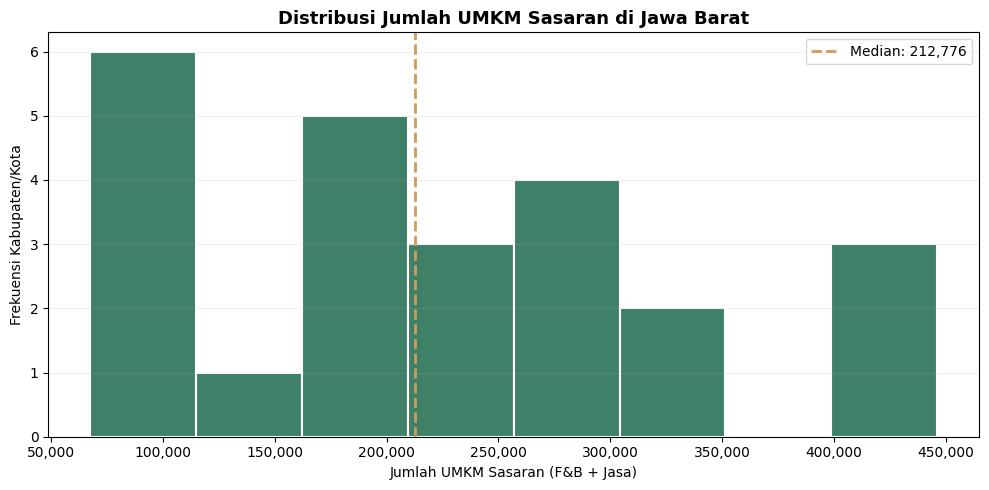

In [23]:

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    df_eda["umkm_sasaran"],
    bins=8,
    color=HIJAU,
    edgecolor="white",
    linewidth=1.5
)

median = df_eda["umkm_sasaran"].median()

ax.axvline(
    median,
    color=ORANYE,
    linestyle="--",
    linewidth=2,
    label=f"Median: {median:,.0f}"
)

ax.set_title("Distribusi Jumlah UMKM Sasaran di Jawa Barat")
ax.set_xlabel("Jumlah UMKM Sasaran (F&B + Jasa)")
ax.set_ylabel("Frekuensi Kabupaten/Kota")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


**Interpretasi Bisnis**

Histogram memperlihatkan persebaran jumlah UMKM yang termasuk dalam sektor sasaran Klay, yaitu F&B dan Jasa (proksi). Perbedaan distribusi menunjukkan bahwa ukuran pasar potensial tidak tersebar secara merata di seluruh kabupaten/kota.

Wilayah dengan jumlah UMKM sasaran lebih besar memiliki basis calon pelanggan potensial yang lebih luas. Namun, jumlah tersebut masih perlu dibandingkan dengan kepadatan UMKM dan kesiapan digital agar prioritas pemasaran tidak hanya didasarkan pada besarnya jumlah usaha.

### I.7.3 Visualisasi 2 — Perbandingan Jumlah UMKM F&B dan Jasa per Wilayah

Visualisasi ini membandingkan jumlah UMKM pada sektor F&B dan Jasa (proksi) di setiap kabupaten/kota. Kedua sektor ditampilkan secara berdampingan agar perbedaan ukuran pasar sektoral dapat diamati dengan lebih jelas.

Analisis ini diperlukan untuk mengidentifikasi apakah potensi pasar UMKM di suatu wilayah lebih banyak berasal dari sektor F&B atau Jasa. Sepuluh wilayah dengan jumlah UMKM sasaran terbesar ditampilkan agar perbandingan lebih mudah dibaca.

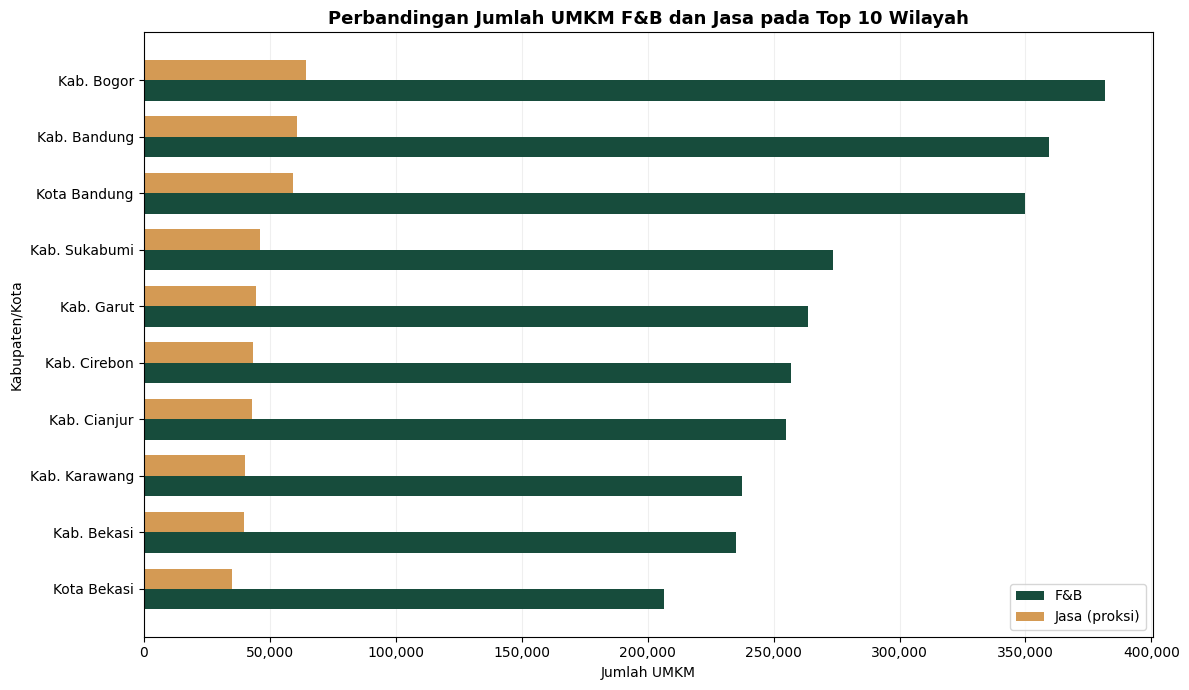

Total F&B: 4,606,032
Total Jasa (proksi): 779,517
Porsi F&B: 85.53%
Porsi Jasa: 14.47%


In [24]:

top_sektor = df_eda.nlargest(
    10, "umkm_sasaran"
).sort_values("umkm_sasaran")

y = np.arange(len(top_sektor))
tinggi = 0.36

fig, ax = plt.subplots(figsize=(12, 7))

bar_fnb = ax.barh(
    y - tinggi/2,
    top_sektor["umkm_fnb"],
    height=tinggi,
    color=HIJAU_TUA,
    label="F&B"
)

bar_jasa = ax.barh(
    y + tinggi/2,
    top_sektor["umkm_jasa"],
    height=tinggi,
    color=ORANYE,
    label="Jasa (proksi)"
)

ax.set_yticks(y)
ax.set_yticklabels(top_sektor["nama_standar"])

ax.set_title("Perbandingan Jumlah UMKM F&B dan Jasa pada Top 10 Wilayah")
ax.set_xlabel("Jumlah UMKM")
ax.set_ylabel("Kabupaten/Kota")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Ringkasan total kedua sektor
print("Total F&B:", f"{df_eda['umkm_fnb'].sum():,.0f}")
print("Total Jasa (proksi):", f"{df_eda['umkm_jasa'].sum():,.0f}")

if df_eda["umkm_fnb"].sum() + df_eda["umkm_jasa"].sum() > 0:
    print(
        "Porsi F&B:",
        f"{df_eda['umkm_fnb'].sum() / df_eda['umkm_sasaran'].sum() * 100:.2f}%"
    )
    print(
        "Porsi Jasa:",
        f"{df_eda['umkm_jasa'].sum() / df_eda['umkm_sasaran'].sum() * 100:.2f}%"
    )


**Interpretasi Bisnis**

Grafik membandingkan kontribusi sektor F&B dan Jasa (proksi) terhadap ukuran pasar UMKM di sepuluh wilayah dengan jumlah UMKM sasaran terbesar.

Perbedaan panjang batang menunjukkan sektor yang memiliki jumlah usaha lebih besar pada masing-masing wilayah. Informasi ini dapat membantu Klay menentukan pendekatan akuisisi pelanggan berdasarkan karakteristik sektor yang lebih dominan.

Namun, hasil untuk sektor Jasa perlu dibaca secara hati-hati karena kategori Jasa/Lainnya mencakup berbagai jenis usaha dan tidak seluruhnya dapat dipastikan memiliki pola transaksi kecil berulang.

### I.7.4 Visualisasi 3 — Hubungan PDRB per Kapita dengan Kepadatan UMKM Sasaran

Visualisasi scatter plot digunakan untuk menganalisis hubungan antara PDRB per kapita dan kepadatan UMKM sasaran pada setiap kabupaten/kota.

Sumbu X menunjukkan PDRB per kapita, sedangkan sumbu Y menunjukkan jumlah UMKM sasaran per 1.000 penduduk. Setiap titik diberi label nama wilayah agar identitas kabupaten/kota dapat diketahui secara langsung.

Garis median membagi wilayah menjadi empat kelompok berdasarkan posisi relatif kedua indikator. Nilai korelasi Pearson juga dihitung untuk mengetahui arah dan kekuatan hubungan linear di antara keduanya.

In [25]:
# adjustText hanya merapikan label di grafik. Kalau belum terpasang, coba pasang; kalau gagal, grafik tetap dibuat tanpa perapian label.
try:
    import adjustText
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "adjustText"], check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

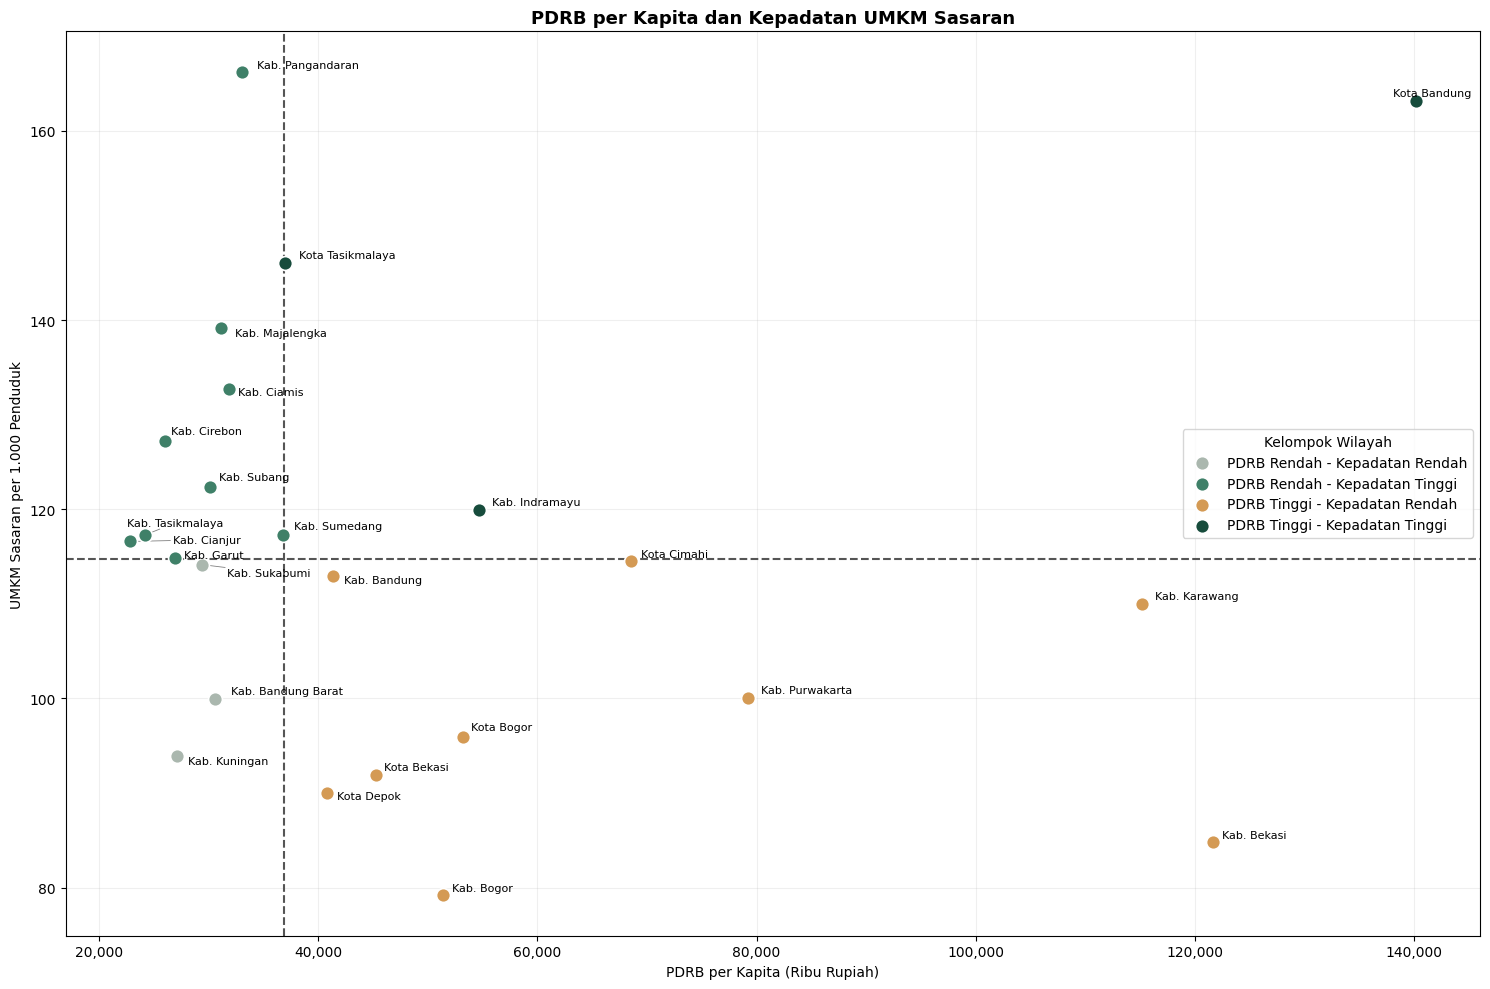

Korelasi Pearson: -0.009

PDRB Rendah - Kepadatan Rendah:
Kab. Sukabumi, Kab. Kuningan, Kab. Bandung Barat

PDRB Rendah - Kepadatan Tinggi:
Kab. Cianjur, Kab. Garut, Kab. Tasikmalaya, Kab. Ciamis, Kab. Cirebon, Kab. Majalengka, Kab. Sumedang, Kab. Subang, Kab. Pangandaran

PDRB Tinggi - Kepadatan Rendah:
Kab. Bogor, Kab. Bandung, Kab. Purwakarta, Kab. Karawang, Kab. Bekasi, Kota Bogor, Kota Bekasi, Kota Depok, Kota Cimahi

PDRB Tinggi - Kepadatan Tinggi:
Kab. Indramayu, Kota Bandung, Kota Tasikmalaya


In [26]:

try:
    from adjustText import adjust_text
except ImportError:
    def adjust_text(texts, **kwargs): pass

df_scatter = df_eda[
    ["nama_standar", "pdrb_per_kapita", "umkm_sasaran_per_1000"]
].dropna().copy()

median_pdrb = df_scatter["pdrb_per_kapita"].median()
median_density = df_scatter["umkm_sasaran_per_1000"].median()

def kelompok(row):
    if row["pdrb_per_kapita"] >= median_pdrb and row["umkm_sasaran_per_1000"] >= median_density:
        return "PDRB Tinggi - Kepadatan Tinggi"
    elif row["pdrb_per_kapita"] >= median_pdrb:
        return "PDRB Tinggi - Kepadatan Rendah"
    elif row["umkm_sasaran_per_1000"] >= median_density:
        return "PDRB Rendah - Kepadatan Tinggi"
    return "PDRB Rendah - Kepadatan Rendah"

df_scatter["kelompok"] = df_scatter.apply(kelompok, axis=1)

warna = {
    "PDRB Tinggi - Kepadatan Tinggi": HIJAU_TUA,
    "PDRB Tinggi - Kepadatan Rendah": ORANYE,
    "PDRB Rendah - Kepadatan Tinggi": HIJAU,
    "PDRB Rendah - Kepadatan Rendah": ABU
}

fig, ax = plt.subplots(figsize=(15, 10))

for kategori, data in df_scatter.groupby("kelompok"):
    ax.scatter(
        data["pdrb_per_kapita"],
        data["umkm_sasaran_per_1000"],
        color=warna[kategori],
        s=100,
        label=kategori,
        edgecolor="white",
        linewidth=1.2,
        zorder=3
    )

texts = []
for _, row in df_scatter.iterrows():
    texts.append(
        ax.text(
            row["pdrb_per_kapita"],
            row["umkm_sasaran_per_1000"],
            row["nama_standar"],
            fontsize=8
        )
    )

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.6)
)

ax.axvline(median_pdrb, color="#555555", linestyle="--")
ax.axhline(median_density, color="#555555", linestyle="--")

ax.set_title("PDRB per Kapita dan Kepadatan UMKM Sasaran")
ax.set_xlabel("PDRB per Kapita (Ribu Rupiah)")
ax.set_ylabel("UMKM Sasaran per 1.000 Penduduk")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

ax.legend(title="Kelompok Wilayah")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

korelasi = df_scatter["pdrb_per_kapita"].corr(
    df_scatter["umkm_sasaran_per_1000"]
)

print(f"Korelasi Pearson: {korelasi:.3f}")

# Menampilkan nama daerah pada masing-masing kuadran
for kategori, data in df_scatter.groupby("kelompok"):
    print(f"\n{kategori}:")
    print(", ".join(data["nama_standar"].tolist()))


**Interpretasi Bisnis**

Berdasarkan hasil evaluasi awal, korelasi Pearson antara PDRB per kapita dan kepadatan UMKM sasaran sebesar **−0,009**, yang menunjukkan hubungan linear sangat lemah atau hampir tidak ada pada data yang dianalisis.

Temuan ini menunjukkan bahwa wilayah dengan aktivitas ekonomi lebih tinggi tidak otomatis memiliki kepadatan UMKM sasaran yang lebih tinggi. Dengan demikian, PDRB per kapita tidak cukup digunakan sebagai satu-satunya dasar untuk menentukan wilayah pemasaran Klay.

Pengelompokan berdasarkan median membantu mengidentifikasi wilayah yang memiliki kombinasi karakteristik berbeda. Wilayah dengan PDRB dan kepadatan UMKM sama-sama tinggi dapat menjadi kandidat awal, sedangkan wilayah dengan kepadatan UMKM tinggi tetapi PDRB lebih rendah tetap perlu dipertimbangkan sebagai pasar potensial.

Nama wilayah pada setiap kelompok ditampilkan melalui hasil kode agar interpretasi akhir menggunakan data aktual, bukan asumsi.

### I.7.5 Visualisasi 4 — Perbandingan Kesiapan Digital Wilayah

Visualisasi ini membandingkan kesiapan digital antarwilayah berdasarkan empat indikator, yaitu persentase pemuda pengguna internet, komputer, dan telepon seluler, serta persentase desa/kelurahan yang mendapatkan sinyal 4G.

Setiap indikator dinormalisasi menggunakan Min-Max Scaling sebelum dihitung rata-ratanya. Nilai rata-rata tersebut digunakan sebagai skor komposit untuk membandingkan kesiapan digital relatif antarwilayah.

Sepuluh wilayah dengan nilai tertinggi ditampilkan untuk memudahkan identifikasi wilayah yang memiliki kondisi digital relatif lebih baik.

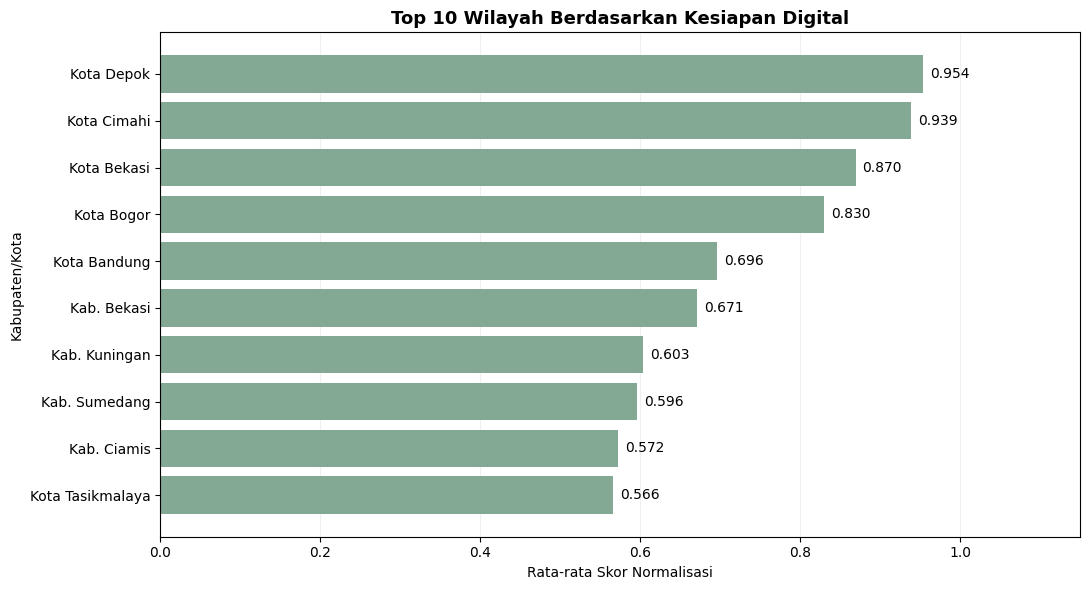

In [27]:

top_digital = df_eda.nlargest(
    10, "kesiapan_digital"
).sort_values("kesiapan_digital")

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    top_digital["nama_standar"],
    top_digital["kesiapan_digital"],
    color=SAGE
)

ax.bar_label(bars, fmt="%.3f", padding=5)

ax.set_title("Top 10 Wilayah Berdasarkan Kesiapan Digital")
ax.set_xlabel("Rata-rata Skor Normalisasi")
ax.set_ylabel("Kabupaten/Kota")
ax.set_xlim(0, 1.15)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Interpretasi Bisnis**

Grafik menunjukkan sepuluh wilayah dengan skor kesiapan digital relatif tertinggi berdasarkan gabungan empat indikator yang digunakan.

Wilayah dengan skor lebih tinggi memiliki kondisi akses dan penggunaan teknologi yang relatif lebih baik dibandingkan wilayah lain dalam dataset. Hal ini dapat menjadi pertimbangan bagi Klay karena penggunaan aplikasi kasir dan analitik membutuhkan dukungan teknologi digital.

Meskipun demikian, skor ini belum menggambarkan adopsi teknologi secara langsung oleh pelaku UMKM. Indikator penggunaan teknologi hanya mencakup kelompok pemuda, sedangkan data 4G menggambarkan kondisi infrastruktur tahun 2021.

### I.7.6 Visualisasi 5 — Heatmap Perbandingan Indikator Wilayah dan Sektor

Heatmap digunakan untuk membandingkan karakteristik 24 kabupaten/kota berdasarkan beberapa indikator sekaligus. Indikator yang ditampilkan meliputi jumlah UMKM F&B, jumlah UMKM Jasa (proksi), kepadatan UMKM sasaran, kesiapan digital, dan PDRB per kapita.

Seluruh indikator menggunakan skor normalisasi Min-Max dengan rentang 0 sampai 1. Nilai yang semakin mendekati 1 menunjukkan posisi relatif yang lebih tinggi dibandingkan wilayah lainnya pada indikator tersebut.

Visualisasi ini membantu melihat perbedaan potensi sektor dan kondisi ekonomi maupun digital antarwilayah secara bersamaan.

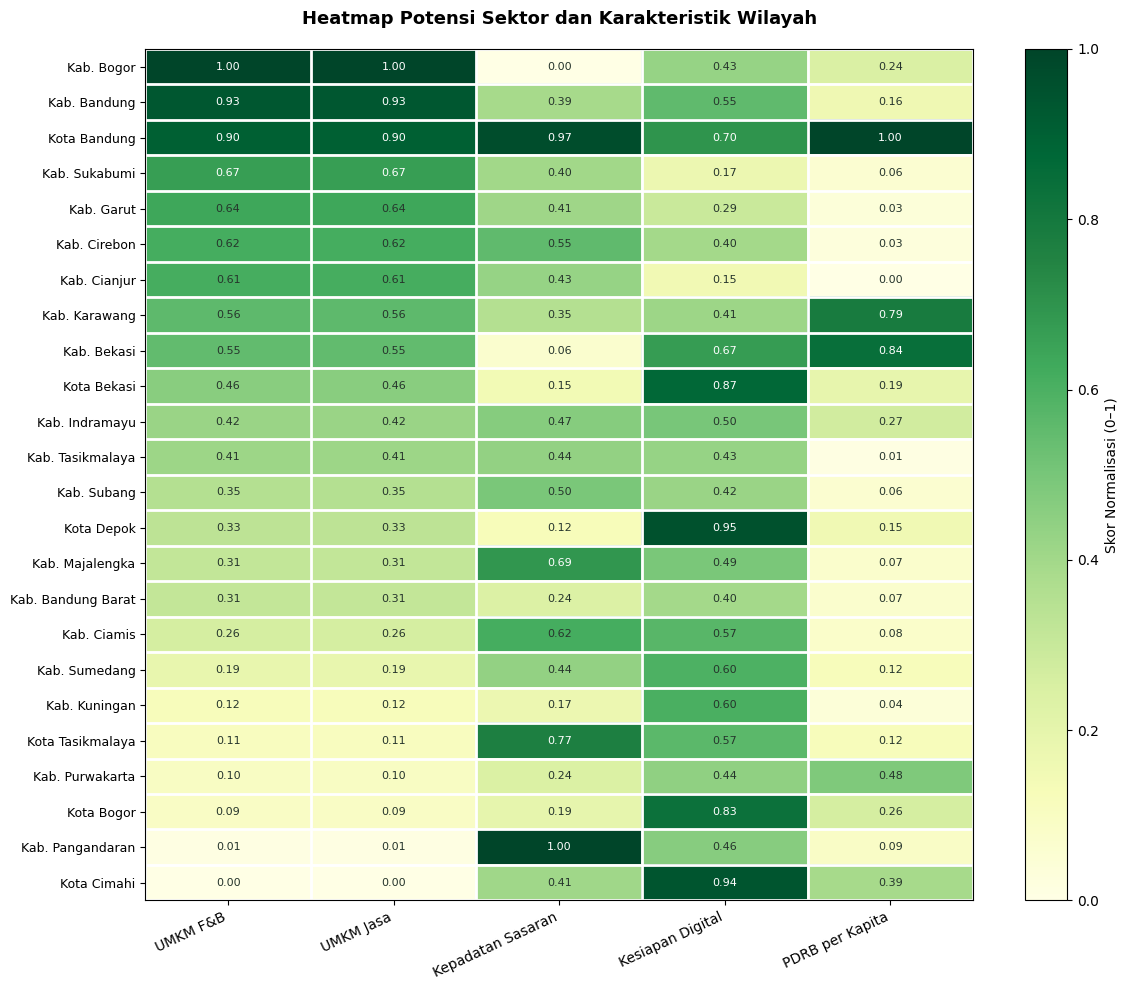

In [28]:

import matplotlib.pyplot as plt
import numpy as np

kolom_heatmap = [
    "umkm_fnb_norm",
    "umkm_jasa_norm",
    "umkm_sasaran_per_1000_norm",
    "kesiapan_digital",
    "pdrb_per_kapita_norm"
]

label_heatmap = [
    "UMKM F&B",
    "UMKM Jasa",
    "Kepadatan Sasaran",
    "Kesiapan Digital",
    "PDRB per Kapita"
]

heatmap_data = (
    df_eda.sort_values("umkm_sasaran", ascending=False)
    .set_index("nama_standar")[kolom_heatmap]
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="YlGn",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

# Label sumbu X dan Y
ax.set_xticks(np.arange(len(label_heatmap)))
ax.set_xticklabels(label_heatmap, rotation=25, ha="right")

ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index, fontsize=9)

# Garis pemisah antar-kotak
ax.set_xticks(np.arange(-0.5, len(label_heatmap), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(heatmap_data.index), 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=2)

# Hilangkan tick kecil
ax.tick_params(which="minor", bottom=False, left=False)

# Tampilkan nilai di dalam setiap kotak
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        nilai = heatmap_data.iloc[i, j]

        warna_teks = "white" if nilai >= 0.65 else "#26352C"

        ax.text(
            j, i,
            f"{nilai:.2f}",
            ha="center",
            va="center",
            color=warna_teks,
            fontsize=8
        )

ax.set_title(
    "Heatmap Potensi Sektor dan Karakteristik Wilayah",
    pad=18
)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Skor Normalisasi (0–1)")

plt.tight_layout()
plt.show()


**Interpretasi Bisnis**

Visualisasi ini membandingkan persebaran UMKM F&B dan Jasa (proksi) terhadap aktivitas ekonomi wilayah yang direpresentasikan oleh PDRB per kapita.

Perbedaan pola kedua sektor dapat memberikan gambaran apakah hubungan antara aktivitas ekonomi dan jumlah UMKM memiliki karakteristik yang berbeda pada masing-masing sektor.

Bagi Klay, analisis ini dapat membantu memahami bahwa potensi pasar tidak hanya ditentukan oleh kondisi ekonomi wilayah, tetapi juga oleh komposisi sektor UMKM yang tersedia. Hasil korelasi untuk masing-masing sektor perlu diperhatikan sebagai informasi pendukung, bukan sebagai hubungan sebab-akibat.

### I.7.7 Visualisasi 6 — Pemetaan Potensi Wilayah Berdasarkan Beberapa Indikator

Visualisasi ini menggunakan bubble chart untuk membandingkan beberapa indikator secara bersamaan.

Sumbu X menunjukkan ukuran pasar berdasarkan jumlah UMKM yang telah dinormalisasi, sedangkan sumbu Y menunjukkan kesiapan digital wilayah. Ukuran gelembung menggambarkan kepadatan UMKM sasaran dan warna menunjukkan aktivitas ekonomi berdasarkan PDRB per kapita.

Setiap titik diberi label nama kabupaten/kota agar wilayah yang memiliki karakteristik tertentu dapat diidentifikasi secara langsung.

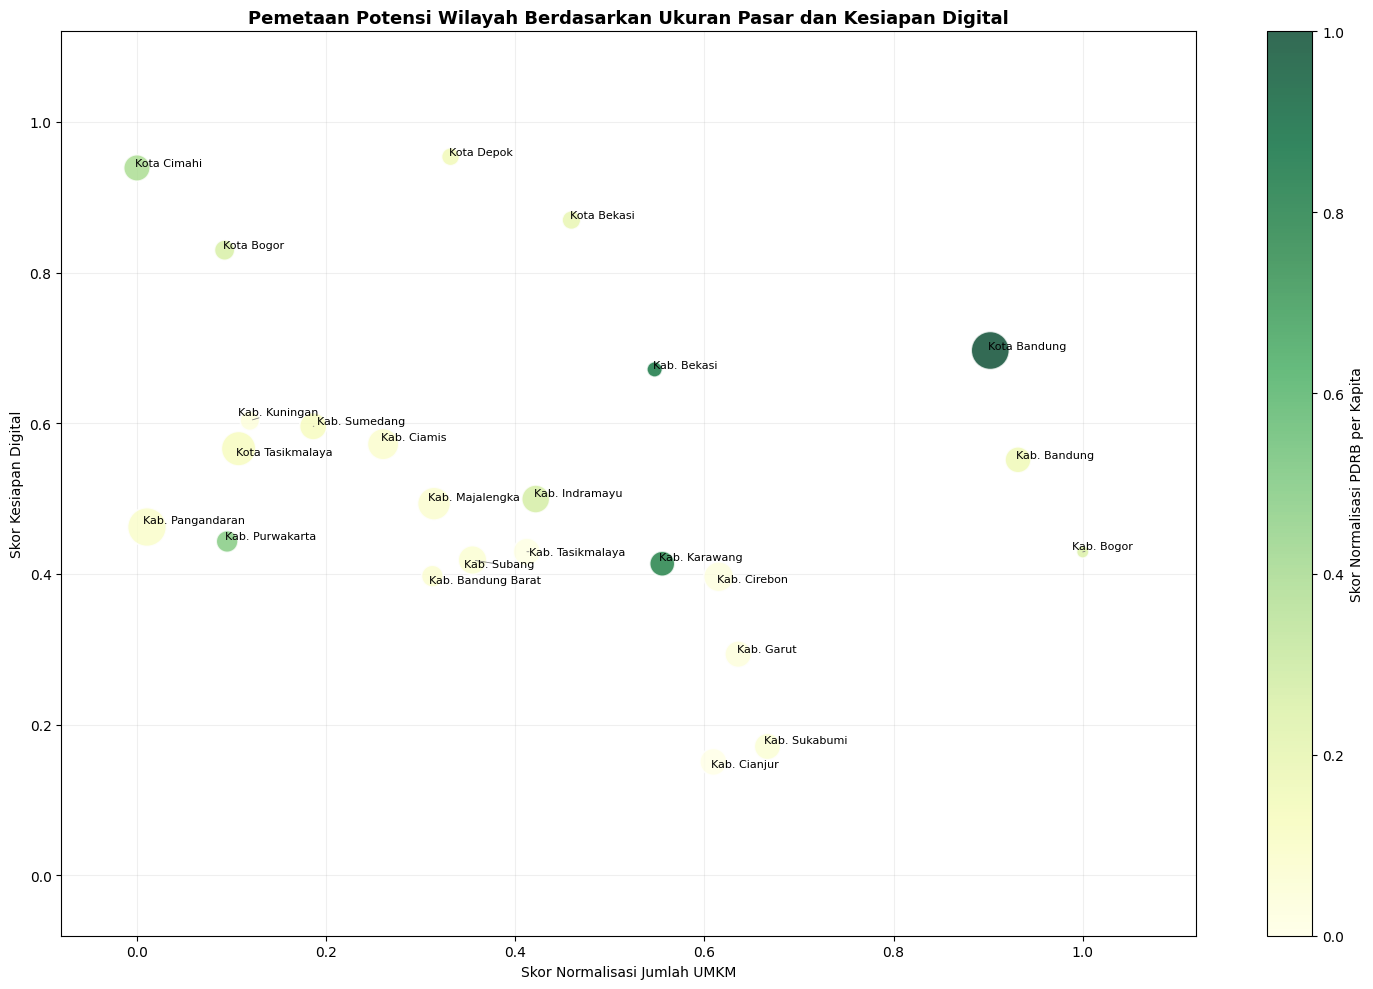

In [29]:
# df_vis: data EDA + skor Min-Max jumlah UMKM total (umkm_total_norm) dari Bagian I.7
df_vis = df_eda.merge(norm[["kode_bps", "umkm_total_norm"]], on="kode_bps", how="left")


try:
    from adjustText import adjust_text
except ImportError:
    def adjust_text(texts, **kwargs): pass

fig, ax = plt.subplots(figsize=(15, 10))

# Ukuran gelembung berdasarkan kepadatan UMKM sasaran
ukuran = (
    80 + df_vis["umkm_sasaran_per_1000_norm"] * 700
)

scatter = ax.scatter(
    df_vis["umkm_total_norm"],
    df_vis["kesiapan_digital"],
    s=ukuran,
    c=df_vis["pdrb_per_kapita_norm"],
    cmap="YlGn",
    vmin=0,
    vmax=1,
    alpha=0.8,
    edgecolor="white",
    linewidth=1.2
)

texts = []
for _, row in df_vis.iterrows():
    texts.append(
        ax.text(
            row["umkm_total_norm"],
            row["kesiapan_digital"],
            row["nama_standar"],
            fontsize=8
        )
    )

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.6)
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Skor Normalisasi PDRB per Kapita")

ax.set_title("Pemetaan Potensi Wilayah Berdasarkan Ukuran Pasar dan Kesiapan Digital")
ax.set_xlabel("Skor Normalisasi Jumlah UMKM")
ax.set_ylabel("Skor Kesiapan Digital")

ax.set_xlim(-0.08, 1.12)
ax.set_ylim(-0.08, 1.12)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Interpretasi Bisnis**

Bubble chart menunjukkan posisi relatif setiap kabupaten/kota berdasarkan ukuran pasar dan kesiapan digital, dengan kepadatan UMKM sasaran serta PDRB per kapita sebagai indikator tambahan.

Wilayah yang berada di bagian kanan atas memiliki ukuran pasar dan kesiapan digital relatif tinggi. Jika wilayah tersebut juga memiliki gelembung lebih besar dan warna yang menunjukkan PDRB relatif tinggi, wilayah tersebut dapat menjadi kandidat awal untuk dipertimbangkan dalam prioritas pemasaran Klay.

Visualisasi ini membantu melihat interaksi beberapa indikator sekaligus, sehingga tidak hanya mengandalkan satu variabel dalam menilai potensi suatu wilayah.

## I.8. Rancangan Formulasi Bobot Indeks Prioritas (ICP)

### I.8.1 Dasar Penentuan Bobot ICP

Indeks Customer Prioritization (ICP) dirancang sebagai kerangka awal untuk membantu menentukan wilayah yang berpotensi menjadi target pemasaran Klay, yaitu aplikasi kasir dan analitik penjualan untuk UMKM.

Penentuan komponen bobot mempertimbangkan kesesuaian indikator publik dengan karakteristik bisnis Klay. Empat komponen yang digunakan adalah ukuran pasar, kepadatan sektor sasaran, kesiapan digital, dan aktivitas ekonomi.

Ukuran pasar dihitung menggunakan jumlah UMKM sasaran, yaitu gabungan sektor F&B dan Jasa (proksi), bukan keseluruhan UMKM. Penggunaan indikator ini bertujuan agar pengukuran lebih sesuai dengan sektor yang menjadi target bisnis Klay.

Komponen adopsi pembayaran digital belum dimasukkan karena data QRIS pada tingkat kabupaten/kota tidak tersedia. Nilai komponen tersebut tidak diperkirakan atau diisi menggunakan asumsi.

### I.8.2 Rancangan Bobot Awal ICP

Bobot awal disusun berdasarkan pertimbangan strategis kelompok terhadap kontribusi setiap indikator dalam mengidentifikasi potensi pasar Klay. Total bobot seluruh komponen ditetapkan sebesar 100%.

Pada komponen kesiapan digital, empat indikator yang digunakan diberikan bobot internal yang sama karena belum tersedia dasar empiris yang cukup untuk menyatakan bahwa salah satu indikator lebih dominan dibandingkan indikator lainnya.

In [30]:

bobot_icp = pd.DataFrame([
    {
        "Komponen": "Ukuran Pasar",
        "Indikator Publik": "Jumlah UMKM sasaran (F&B + Jasa)",
        "Variabel": "umkm_sasaran",
        "Arah": "Positif (+)",
        "Bobot (%)": 30,
        "Justifikasi Bisnis": "Menggambarkan luasnya basis calon pelanggan yang sesuai dengan target sektor Klay."
    },
    {
        "Komponen": "Kepadatan Sektor Target",
        "Indikator Publik": "UMKM sasaran per 1.000 penduduk",
        "Variabel": "umkm_sasaran_per_1000",
        "Arah": "Positif (+)",
        "Bobot (%)": 25,
        "Justifikasi Bisnis": "Menggambarkan konsentrasi UMKM sasaran dengan mempertimbangkan ukuran populasi wilayah."
    },
    {
        "Komponen": "Kesiapan Digital",
        "Indikator Publik": "Rata-rata persentase pemuda pengguna internet, komputer, ponsel, dan sinyal 4G",
        "Variabel": "Rata-rata 4 indikator digital",
        "Arah": "Positif (+)",
        "Bobot (%)": 25,
        "Justifikasi Bisnis": "Menggambarkan dukungan akses dan penggunaan teknologi digital sebagai lingkungan pendukung penggunaan Klay."
    },
    {
        "Komponen": "Aktivitas Ekonomi",
        "Indikator Publik": "PDRB per kapita ADHB",
        "Variabel": "pdrb_per_kapita",
        "Arah": "Positif (+)",
        "Bobot (%)": 20,
        "Justifikasi Bisnis": "Memberikan gambaran kondisi aktivitas ekonomi wilayah sebagai indikator pendukung potensi pasar."
    }
])

display(bobot_icp)
print("Total bobot:", bobot_icp["Bobot (%)"].sum(), "%")


,Komponen,Indikator Publik,Variabel,Arah,Bobot (%),Justifikasi Bisnis
0,Ukuran Pasar,Jumlah UMKM sasaran (F&B + Jasa),umkm_sasaran,Positif (+),30,Menggambarkan luasnya basis calon pelanggan ya...
1,Kepadatan Sektor Target,UMKM sasaran per 1.000 penduduk,umkm_sasaran_per_1000,Positif (+),25,Menggambarkan konsentrasi UMKM sasaran dengan ...
2,Kesiapan Digital,"Rata-rata persentase pemuda pengguna internet,...",Rata-rata 4 indikator digital,Positif (+),25,Menggambarkan dukungan akses dan penggunaan te...
3,Aktivitas Ekonomi,PDRB per kapita ADHB,pdrb_per_kapita,Positif (+),20,Memberikan gambaran kondisi aktivitas ekonomi ...


Total bobot: 100 %


**Justifikasi Penentuan Bobot**

1. **Ukuran Pasar (30%)**

   Memperoleh bobot terbesar karena jumlah UMKM sasaran menggambarkan luasnya basis calon pelanggan yang relevan dengan target sektor Klay. Penggunaan jumlah UMKM sasaran lebih sesuai dibandingkan jumlah UMKM keseluruhan karena tidak memasukkan kategori usaha yang telah digugurkan.

2. **Kepadatan Sektor Target (25%)**

   Menggambarkan konsentrasi UMKM sasaran terhadap jumlah penduduk. Indikator ini digunakan untuk membedakan wilayah yang memiliki konsentrasi calon pelanggan relatif tinggi, bukan hanya jumlah usaha yang besar karena ukuran populasi.

3. **Kesiapan Digital (25%)**

   Menggunakan empat indikator dengan bobot internal yang sama, yaitu penggunaan internet, komputer, telepon seluler, dan ketersediaan sinyal 4G. Bobot komponen diturunkan menjadi 25% karena data yang tersedia masih berupa proksi kondisi digital wilayah, bukan pengukuran langsung adopsi teknologi oleh pelaku UMKM.

4. **Aktivitas Ekonomi (20%)**

   Menggunakan PDRB per kapita ADHB untuk menggambarkan aktivitas ekonomi wilayah. Indikator ini tetap dipertimbangkan sebagai faktor pendukung, tetapi tidak diberikan bobot dominan karena hasil analisis menunjukkan hubungan yang hampir tidak ada dengan kepadatan UMKM sasaran.

Pembobotan ini merupakan rancangan awal berdasarkan pertimbangan strategis kelompok dan karakteristik data yang tersedia, bukan hasil estimasi statistik.

### I.8.3 Visualisasi Komposisi Bobot ICP

Visualisasi ini menunjukkan proporsi bobot yang diberikan pada setiap komponen ICP. Grafik digunakan untuk memperjelas distribusi prioritas indikator dalam rancangan awal indeks.

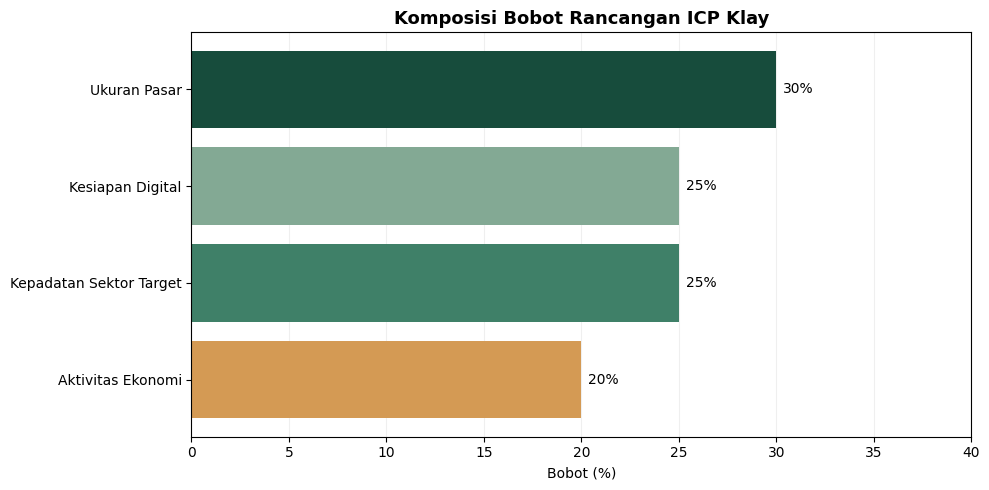

In [31]:

bobot_plot = bobot_icp.sort_values("Bobot (%)")

fig, ax = plt.subplots(figsize=(10, 5))

warna_bobot = [
    ORANYE,
    HIJAU,
    SAGE,
    HIJAU_TUA
]

bars = ax.barh(
    bobot_plot["Komponen"],
    bobot_plot["Bobot (%)"],
    color=warna_bobot
)

ax.bar_label(
    bars,
    labels=[f"{x}%" for x in bobot_plot["Bobot (%)"]],
    padding=5,
    fontsize=10
)

ax.set_title("Komposisi Bobot Rancangan ICP Klay")
ax.set_xlabel("Bobot (%)")
ax.set_xlim(0, 40)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Interpretasi**

Rancangan bobot ICP memberikan prioritas terbesar pada ukuran pasar sebesar 30%, diikuti kepadatan sektor target sebesar 25% dan kesiapan digital sebesar 25%. Aktivitas ekonomi memperoleh bobot sebesar 20%.

Komposisi ini menunjukkan bahwa rancangan indeks lebih menekankan kesesuaian dan konsentrasi calon pelanggan dengan target bisnis Klay, disertai pertimbangan kesiapan digital serta kondisi ekonomi wilayah.

Komponen adopsi pembayaran digital belum dimasukkan karena data QRIS tingkat kabupaten/kota tidak tersedia. Dengan demikian, seluruh bobot dialokasikan pada indikator yang memiliki data pembanding.

### I.8.4 Keterbatasan Analisis (ringkas; versi lengkap dan terkini di Bagian F)

Terdapat beberapa keterbatasan yang perlu diperhatikan dalam membaca hasil EDA dan rancangan ICP:

1. **Data UMKM merupakan proyeksi.** Komposisi sektor dan pertumbuhan UMKM relatif seragam antarwilayah, sehingga tidak dapat digunakan untuk membedakan potensi sektor secara langsung.
2. **Kategori ritel tidak tersedia.** Data hanya menyediakan sepuluh kategori usaha dan tidak memiliki kategori ritel tersendiri.
3. **Kategori jasa bersifat campuran.** Kategori Jasa/Lainnya digunakan sebagai proksi untuk sektor jasa, tetapi tidak seluruh usahanya dapat dipastikan memiliki transaksi kecil berulang.
4. **Data QRIS tingkat kabupaten/kota tidak tersedia.** Oleh karena itu, indikator adopsi pembayaran digital belum dimasukkan ke dalam rancangan bobot ICP.
5. **Indikator digital merupakan proksi.** Data pemuda tidak mewakili seluruh pelaku UMKM, sedangkan data sinyal 4G menggambarkan infrastruktur pada tahun 2021, bukan penggunaan aktual.
6. **PDRB per kapita bukan pendapatan UMKM.** Indikator ini digunakan untuk menggambarkan aktivitas ekonomi wilayah secara umum, bukan kemampuan finansial setiap usaha.

Dengan mempertimbangkan keterbatasan tersebut, hasil EDA dan bobot ICP digunakan sebagai dasar awal untuk menyusun prioritas wilayah, bukan sebagai gambaran mutlak mengenai potensi setiap UMKM.

# BAGIAN II. Pemodelan dan indeks prioritas (Bagian A sampai F)
Bagian ini memakai file hasil Bagian I (folder `output`). Tiap langkah dijelaskan sebelum kodenya.

## A. Persiapan data dan fitur

**Langkah A1.** Muat data bersih 27 wilayah dari Bagian I (folder `output`), buang 3 wilayah yang gugur, sisakan 24 wilayah.

**Langkah A2.** Bentuk 4 komponen ICP, semuanya dinormalisasi Min-Max (rumus: (x - min) / (maks - min)) pada 24 wilayah yang lolos:
- **Ukuran pasar**: jumlah UMKM sasaran (F&B + Jasa).
- **Kepadatan sektor**: UMKM sasaran per 1.000 penduduk.
- **Kesiapan digital**: rata-rata 4 indikator yang sudah dinormalisasi (% pemuda pengguna internet, komputer, ponsel, dan % desa/kelurahan dengan sinyal 4G). Empat indikator ini dirata-rata dulu supaya komponen digital hanya dihitung satu kali, bukan empat kali.
- **Aktivitas ekonomi**: PDRB per kapita.

Karena Min-Max tidak berubah bila semua nilai dikali konstanta, ukuran pasar dari UMKM sasaran sama dengan dari UMKM total di Tugas 2 (porsi sasaran hampir identik di semua wilayah). Sel di bawah memeriksanya.

In [32]:
import warnings
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.stats import spearmanr, kendalltau, kruskal

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 140)
SEED = 42                       # semua hasil acak memakai seed ini supaya bisa diulang

# Palet warna (urutan tetap): biru, oranye, aqua, kuning
BIRU, ORANYE, AQUA, KUNING = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TEKS, TEKS2, GRID, ABU = "#0b0b0b", "#52514e", "#e4e3df", "#9a9993"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRID, "axes.titleweight": "normal", "axes.titlesize": 10,
                     "axes.labelcolor": TEKS2, "text.color": TEKS, "xtick.color": TEKS2, "ytick.color": TEKS2})

def gaya(ax, sumbu="y"):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(GRID); ax.spines["bottom"].set_color(GRID)
    ax.grid(axis=sumbu, color=GRID, lw=0.8); ax.set_axisbelow(True)

def rb(v):                       # format angka gaya Indonesia: 1.234.567
    return f"{v:,.0f}".replace(",", ".")

# OUT = folder output yang ditulis Bagian I (data_bersih_27_wilayah.csv dst.)
assert os.path.exists(os.path.join(OUT, "data_bersih_27_wilayah.csv")), "Jalankan Bagian I sampai sel 'Menyimpan hasil' dulu."
GAMBAR = os.path.join(OUT, "gambar"); os.makedirs(GAMBAR, exist_ok=True)
print("Folder data:", OUT)

Folder data: output


In [33]:
tabel = pd.read_csv(f"{OUT}/data_bersih_27_wilayah.csv")        # 27 wilayah, hasil cleaning + merging Tugas 2
gugur = pd.read_csv(f"{OUT}/wilayah_tereliminasi.csv")          # 3 wilayah gugur (Kriteria A)
lolos = tabel[~tabel["kode_bps"].isin(gugur["kode_bps"])].reset_index(drop=True)
assert len(lolos) == 24, "seharusnya 24 wilayah lolos"
print(f"Wilayah awal {len(tabel)} | gugur {len(gugur)} ({', '.join(gugur['wilayah'])}) | lolos {len(lolos)}")

def min_max(s):
    return (s - s.min()) / (s.max() - s.min())

# Empat komponen ICP (sama dengan Bagian 4 Tugas 2), semuanya berarah positif
DIGITAL = ["pemuda_internet", "pemuda_komputer", "pemuda_ponsel", "sinyal_4g_pct"]
W = pd.DataFrame({"kode_bps": lolos["kode_bps"], "nama": lolos["nama_standar"]})
W["ukuran"]    = min_max(lolos["umkm_sasaran"])                  # ukuran pasar: UMKM sasaran (F&B + Jasa)
W["kepadatan"] = min_max(lolos["umkm_sasaran_per_1000"])         # UMKM sasaran per 1.000 penduduk
W["digital"]   = pd.concat([min_max(lolos[c]) for c in DIGITAL], axis=1).mean(axis=1)  # rata-rata 4 indikator ternormalisasi
W["pdrb"]      = min_max(lolos["pdrb_per_kapita"])               # aktivitas ekonomi

# Verifikasi terhadap file normalisasi Tugas 2 (selisih hanya karena pembulatan 4 desimal)
n2 = pd.read_csv(f"{OUT}/data_ternormalisasi_wilayah_lolos.csv")
cek = {"ukuran": ("umkm_total_norm", W["ukuran"]), "pdrb": ("pdrb_per_kapita_norm", W["pdrb"]),
       "kepadatan": ("umkm_sasaran_per_1000_norm", W["kepadatan"])}
for nama, (kol, seri) in cek.items():
    print(f"selisih maks {nama:10s} vs file Tugas 2: {np.abs(n2[kol].values - seri.values).max():.5f}")
W[["nama", "ukuran", "kepadatan", "digital", "pdrb"]].round(3)

Wilayah awal 27 | gugur 3 (Kota Sukabumi, Kota Cirebon, Kota Banjar) | lolos 24
selisih maks ukuran     vs file Tugas 2: 0.00005
selisih maks pdrb       vs file Tugas 2: 0.00005
selisih maks kepadatan  vs file Tugas 2: 0.00004


,nama,ukuran,kepadatan,digital,pdrb
0,Kab. Bogor,1.000,0.000,0.429,0.243
1,Kab. Sukabumi,0.667,0.401,0.171,0.056
2,Kab. Cianjur,0.609,0.430,0.151,0.000
3,Kab. Bandung,0.932,0.387,0.551,0.158
4,Kab. Garut,0.636,0.409,0.294,0.035
5,Kab. Tasikmalaya,0.412,0.437,0.430,0.011
6,Kab. Ciamis,0.260,0.616,0.572,0.077
7,Kab. Kuningan,0.119,0.168,0.603,0.036
8,Kab. Cirebon,0.615,0.552,0.396,0.027
9,Kab. Majalengka,0.314,0.689,0.493,0.071


## B. Pemodelan K-Means (tipe wilayah)

**Langkah B1. Menentukan jumlah klaster k.** K-Means dijalankan untuk k = 2 sampai 8 pada 4 komponen di atas. Untuk tiap k dihitung:
- **Inertia (WCSS)**: makin kecil makin rapat, tapi selalu turun bila k naik, jadi dicari "siku" tempat penurunannya melandai (Elbow).
- **Silhouette**: mengukur seberapa cocok tiap wilayah dengan klasternya dibanding klaster tetangga. Skala -1 sampai 1; di atas 0,5 dianggap struktur klaster jelas, 0,25 sampai 0,5 lemah, di bawah 0,25 tidak ada struktur berarti.
- **Davies-Bouldin** (makin kecil makin baik) dan **Calinski-Harabasz** (makin besar makin baik), sebagai pembanding.
- **Ukuran klaster terkecil** dan **stabilitas** (ARI rata-rata dari 100 kali jalan acak, 1 berarti selalu menghasilkan pengelompokan yang sama).

Pilihan k dibatasi 3 sampai 5 sesuai instruksi. Aturan keputusan ditulis di dalam kode sebelum melihat hasilnya: (1) k antara 3 dan 5, (2) tiap klaster minimal 3 wilayah supaya bisa diprofilkan, (3) dari yang tersisa ambil silhouette tertinggi.

In [34]:
FITUR_K = ["ukuran", "kepadatan", "digital", "pdrb"]
X = W[FITUR_K].values

baris = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=100, random_state=SEED).fit(X)      # 100 inisialisasi, ambil inertia terkecil
    lab = km.labels_
    # stabilitas: 100 kali jalan dengan 1 inisialisasi acak, dibandingkan dengan solusi terbaik (ARI=1 berarti identik)
    ari = [adjusted_rand_score(lab, KMeans(n_clusters=k, n_init=1, random_state=s).fit(X).labels_) for s in range(100)]
    baris.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, lab),
                  "davies_bouldin": davies_bouldin_score(X, lab), "calinski_harabasz": calinski_harabasz_score(X, lab),
                  "klaster_terkecil": int(np.bincount(lab).min()), "stabilitas_ARI": float(np.mean(ari))})
evaluasi = pd.DataFrame(baris).set_index("k")

# Aturan keputusan (ditetapkan sebelum melihat pilihan akhir):
#  1) k harus 3 sampai 5 (batas instruksi); 2) tiap klaster minimal 3 wilayah supaya bisa diprofilkan;
#  3) dari yang tersisa, ambil silhouette tertinggi.
kandidat = evaluasi.loc[3:5]
layak = kandidat[kandidat["klaster_terkecil"] >= 3]
K_FINAL = int(layak["silhouette"].idxmax())
print("k yang memenuhi syarat ukuran klaster:", layak.index.tolist(), "-> k terpilih =", K_FINAL)
evaluasi.round(3)

k yang memenuhi syarat ukuran klaster: [3, 4] -> k terpilih = 4


,inertia,silhouette,davies_bouldin,calinski_harabasz,klaster_terkecil,stabilitas_ARI
k,,,,,,
2,4.473,0.346,1.315,8.825,5,0.284
3,3.118,0.306,0.996,10.602,3,0.366
4,2.261,0.308,0.978,11.810,3,0.632
5,1.759,0.319,0.798,12.174,1,0.637
6,1.313,0.333,0.700,13.579,1,0.547
7,1.038,0.319,0.751,14.279,1,0.556
8,0.819,0.325,0.714,15.202,1,0.632


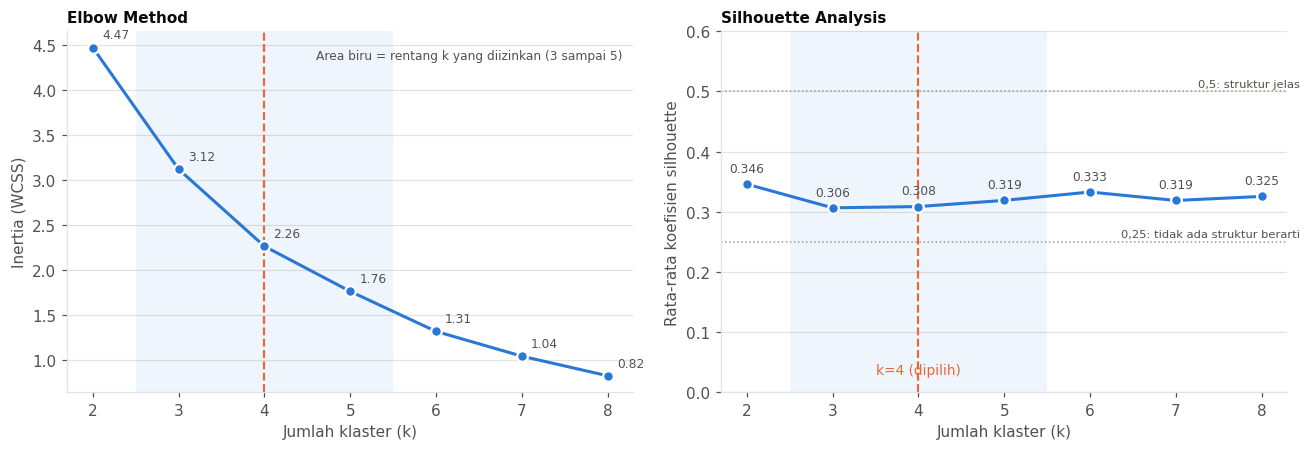

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ks = evaluasi.index.values
for a in ax:
    a.axvspan(2.5, 5.5, color=BIRU, alpha=0.07, lw=0)       # rentang k yang diizinkan (3 sampai 5)
    a.axvline(K_FINAL, color=ORANYE, lw=1.4, ls="--"); gaya(a, "y"); a.set_xlabel("Jumlah klaster (k)"); a.set_xticks(ks)

ax[0].plot(ks, evaluasi["inertia"], color=BIRU, lw=2, marker="o", ms=7, mec="white", mew=1.5)
ax[0].set_ylabel("Inertia (WCSS)"); ax[0].set_title("Elbow Method", loc="left", fontweight="bold")
for k, v in evaluasi["inertia"].items(): ax[0].annotate(f"{v:.2f}", (k, v), textcoords="offset points", xytext=(6, 6), fontsize=8, color=TEKS2)

ax[1].plot(ks, evaluasi["silhouette"], color=BIRU, lw=2, marker="o", ms=7, mec="white", mew=1.5)
ax[1].set_ylabel("Rata-rata koefisien silhouette"); ax[1].set_title("Silhouette Analysis", loc="left", fontweight="bold")
for k, v in evaluasi["silhouette"].items(): ax[1].annotate(f"{v:.3f}", (k, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, color=TEKS2)
ax[1].set_ylim(0, 0.6)      # skala penuh supaya selisih kecil antar k tidak tampak besar
for ref, nm in ((0.25, "0,25: tidak ada struktur berarti"), (0.5, "0,5: struktur jelas")):
    ax[1].axhline(ref, color=ABU, lw=1, ls=":"); ax[1].text(8.45, ref + 0.008, nm, ha="right", fontsize=7.5, color=TEKS2)
ax[1].text(K_FINAL, 0.03, f"k={K_FINAL} (dipilih)", color=ORANYE, fontsize=9, ha="center")
ax[0].text(0.98, 0.95, "Area biru = rentang k yang diizinkan (3 sampai 5)", transform=ax[0].transAxes, ha="right", va="top", fontsize=8, color=TEKS2)
plt.tight_layout(); fig.savefig(f"{GAMBAR}/k1_elbow_silhouette.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretasi grafik Elbow dan Silhouette (dibaca bersama):**
- **Elbow**: penurunan inertia berlangsung bertahap (4,47 -> 3,12 -> 2,26 -> 1,76 -> 1,31). Tidak ada siku yang tajam. Siku paling terlihat ada di k = 3 sampai 4, setelah itu kurvanya melandai.
- **Silhouette**: nilainya hampir datar untuk k = 3, 4, 5 (0,306; 0,308; 0,319), dan semuanya sekitar 0,31, artinya **struktur klaster lemah**. Wilayah Jawa Barat membentuk sebaran yang kontinu, bukan kelompok yang terpisah tegas. Klaster di sini lebih tepat dibaca sebagai **segmentasi deskriptif** untuk keperluan bisnis, bukan batas alami.
- **Kenapa k = 4 dan bukan k = 5 yang silhouette-nya sedikit lebih tinggi:** pada k = 5 ada klaster beranggota 1 wilayah (Kota Bandung) dan satu lagi beranggota 2 wilayah, sehingga tidak bisa diprofilkan. Aturan klaster minimal 3 wilayah menyisakan k = 3 dan k = 4. Di antara keduanya silhouette k = 4 sedikit lebih tinggi (0,308 vs 0,306) dan jauh lebih stabil (ARI 0,63 vs 0,37). Perbedaan 0,002 itu sendiri tidak bermakna, jadi alasan utamanya adalah **kestabilan dan keterbacaan profil**.
- **Skala grafik silhouette** dibuat 0 sampai 0,6 dengan garis acuan 0,25 dan 0,5, supaya terlihat bahwa semua k berada di zona lemah dan selisih antar k kecil.
- Jujur soal batasnya: dengan hanya 24 wilayah dan struktur yang lemah, hasil klaster sebaiknya dipakai sebagai pelengkap skor ICP, bukan sebagai penentu tunggal.

**Langkah B2. Menjalankan model akhir dan memberi nama klaster.** K-Means dijalankan dengan k terpilih. Nomor dan nama klaster diberikan setelah melihat profil rata-rata tiap klaster, dengan bantuan satu wilayah acuan per klaster. Sel di bawah juga mencetak anggota tiap klaster.

In [36]:
km = KMeans(n_clusters=K_FINAL, n_init=100, random_state=SEED).fit(X)
W["klaster_raw"] = km.labels_
W["sil"] = silhouette_samples(X, km.labels_)

# Beri nomor dan nama klaster berdasarkan profilnya (dikunci pada satu wilayah acuan per klaster)
ACUAN = {"Kota Bandung":    (1, "Pusat Ekonomi & Industri"),
         "Kab. Bogor":      (2, "Lumbung UMKM Besar, Digital Relatif Rendah"),
         "Kab. Majalengka": (3, "Sentra UMKM Padat Berkembang"),
         "Kota Depok":      (4, "Digital Tinggi, Pasar Kecil")}
assert K_FINAL == 4, "pemberian nama di bawah ditulis untuk k=4; ubah ACUAN kalau k berubah"
peta_id = {int(W.loc[W["nama"] == w, "klaster_raw"].iloc[0]): no for w, (no, _) in ACUAN.items()}
assert len(peta_id) == 4 and len(set(peta_id.values())) == 4, "wilayah acuan jatuh ke klaster yang sama"
NAMA_K = {no: nm for _, (no, nm) in ACUAN.items()}
W["klaster"] = W["klaster_raw"].map(peta_id)
W["label"] = W["klaster"].map(lambda n: f"K{n}: {NAMA_K[n]}")
WARNA_K  = {1: BIRU, 2: ORANYE, 3: AQUA, 4: KUNING}
MARKER_K = {1: "o", 2: "s", 3: "^", 4: "D"}

print("Silhouette rata-rata:", round(silhouette_score(X, km.labels_), 3))
for no in sorted(NAMA_K):
    g = W[W["klaster"] == no].sort_values("nama")
    print(f"K{no} {NAMA_K[no]} ({len(g)} wilayah): {', '.join(g['nama'])}")

Silhouette rata-rata: 0.308
K1 Pusat Ekonomi & Industri (3 wilayah): Kab. Bekasi, Kab. Karawang, Kota Bandung
K2 Lumbung UMKM Besar, Digital Relatif Rendah (6 wilayah): Kab. Bandung, Kab. Bogor, Kab. Cianjur, Kab. Cirebon, Kab. Garut, Kab. Sukabumi
K3 Sentra UMKM Padat Berkembang (9 wilayah): Kab. Bandung Barat, Kab. Ciamis, Kab. Indramayu, Kab. Majalengka, Kab. Pangandaran, Kab. Subang, Kab. Sumedang, Kab. Tasikmalaya, Kota Tasikmalaya
K4 Digital Tinggi, Pasar Kecil (6 wilayah): Kab. Kuningan, Kab. Purwakarta, Kota Bekasi, Kota Bogor, Kota Cimahi, Kota Depok


**Langkah B3. Mengecek wilayah yang "pas-pasan" di klasternya.** Plot silhouette per wilayah menunjukkan mana yang cocok dan mana yang berada di perbatasan. Wilayah dengan silhouette rendah punya karakter campuran, jadi labelnya jangan terlalu dipaksakan.

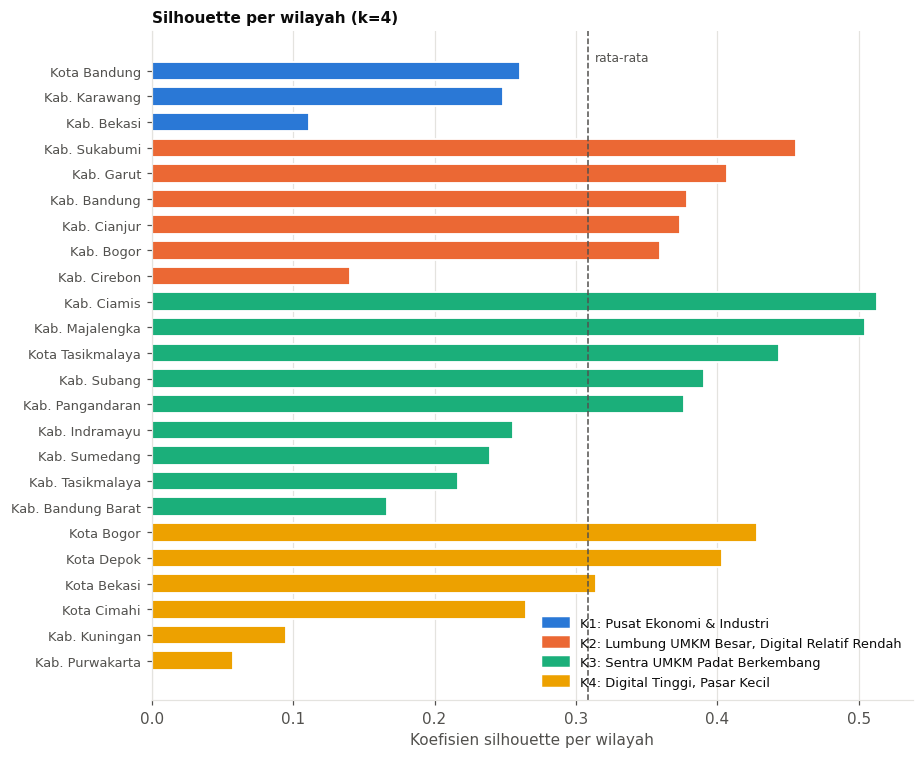

Wilayah dengan silhouette < 0.15 (letaknya di perbatasan klaster, interpretasi hati-hati):
           nama                                          label   sil
Kab. Purwakarta                K4: Digital Tinggi, Pasar Kecil 0.058
  Kab. Kuningan                K4: Digital Tinggi, Pasar Kecil 0.095
    Kab. Bekasi                   K1: Pusat Ekonomi & Industri 0.112
   Kab. Cirebon K2: Lumbung UMKM Besar, Digital Relatif Rendah 0.140


In [37]:
o = W.sort_values(["klaster", "sil"], ascending=[False, True]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.barh(range(len(o)), o["sil"], color=[WARNA_K[k] for k in o["klaster"]], height=0.72, edgecolor="white", lw=1.2)
ax.set_yticks(range(len(o))); ax.set_yticklabels(o["nama"], fontsize=8.5)
ax.axvline(silhouette_score(X, W["klaster_raw"]), color=TEKS2, ls="--", lw=1)
ax.text(silhouette_score(X, W["klaster_raw"]) + 0.005, len(o) - 0.6, "rata-rata", fontsize=8, color=TEKS2)
gaya(ax, "x"); ax.set_xlabel("Koefisien silhouette per wilayah"); ax.set_title(f"Silhouette per wilayah (k={K_FINAL})", loc="left", fontweight="bold")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=WARNA_K[n], label=f"K{n}: {NAMA_K[n]}") for n in sorted(NAMA_K)], loc="lower right", frameon=False, fontsize=8.5)
plt.tight_layout(); fig.savefig(f"{GAMBAR}/k2_silhouette_per_wilayah.png", dpi=200, bbox_inches="tight"); plt.show()
print("Wilayah dengan silhouette < 0.15 (letaknya di perbatasan klaster, interpretasi hati-hati):")
print(W[W["sil"] < 0.15][["nama", "label", "sil"]].sort_values("sil").round(3).to_string(index=False))

**Langkah B4. Profil dan label klaster.** Tabel profil memberi rata-rata tiap komponen (skala 0 sampai 1) dan nilai aslinya. Heatmap di bawahnya menunjukkan pola yang membedakan klaster, dan peta PCA menggambarkan posisi wilayah dalam 2 dimensi (PCA hanya untuk gambar; K-Means dihitung pada 4 komponen penuh).

In [38]:
data = lolos.merge(W[["kode_bps", "klaster", "label", "sil", "ukuran", "kepadatan", "digital", "pdrb"]], on="kode_bps")
data["pemuda_komputer_pct"] = data["pemuda_komputer"]
prof = data.groupby("klaster").agg(
    jumlah_wilayah=("nama_standar", "size"),
    ukuran_norm=("ukuran", "mean"), kepadatan_norm=("kepadatan", "mean"), digital_norm=("digital", "mean"), pdrb_norm=("pdrb", "mean"),
    umkm_sasaran_rata2=("umkm_sasaran", "mean"), umkm_per_1000=("umkm_sasaran_per_1000", "mean"),
    pdrb_juta_rp=("pdrb_per_kapita", lambda s: s.mean() / 1000), sinyal_4g_pct=("sinyal_4g_pct", "mean"),
    pemuda_komputer_pct=("pemuda_komputer", "mean"), total_umkm_sasaran=("umkm_sasaran", "sum"))
prof["nama_klaster"] = [NAMA_K[i] for i in prof.index]
prof["anggota"] = [", ".join(sorted(data.loc[data["klaster"] == i, "nama_standar"])) for i in prof.index]
print("Profil rata-rata tiap klaster (komponen 0-1 = hasil Min-Max; kolom lain nilai asli):")
prof[["nama_klaster", "jumlah_wilayah", "ukuran_norm", "kepadatan_norm", "digital_norm", "pdrb_norm"]].round(2)

Profil rata-rata tiap klaster (komponen 0-1 = hasil Min-Max; kolom lain nilai asli):


,nama_klaster,jumlah_wilayah,ukuran_norm,kepadatan_norm,digital_norm,pdrb_norm
klaster,,,,,,
1,Pusat Ekonomi & Industri,3,0.67,0.46,0.59,0.88
2,"Lumbung UMKM Besar, Digital Relatif Rendah",6,0.74,0.36,0.33,0.09
3,Sentra UMKM Padat Berkembang,9,0.26,0.57,0.49,0.10
4,"Digital Tinggi, Pasar Kecil",6,0.18,0.21,0.77,0.25


In [39]:
prof[["jumlah_wilayah", "umkm_sasaran_rata2", "umkm_per_1000", "pdrb_juta_rp", "sinyal_4g_pct", "pemuda_komputer_pct", "total_umkm_sasaran"]].round(1)

,jumlah_wilayah,umkm_sasaran_rata2,umkm_per_1000,pdrb_juta_rp,sinyal_4g_pct,pemuda_komputer_pct,total_umkm_sasaran
klaster,,,,,,,
1,3,320524.3,119.3,125.7,96.5,30.2,961573
2,6,348808.7,110.8,33.0,91.5,17.0,2092852
3,9,167723.8,129.0,34.4,92.2,20.8,1509514
4,6,136935.0,97.7,52.4,97.0,35.2,821610


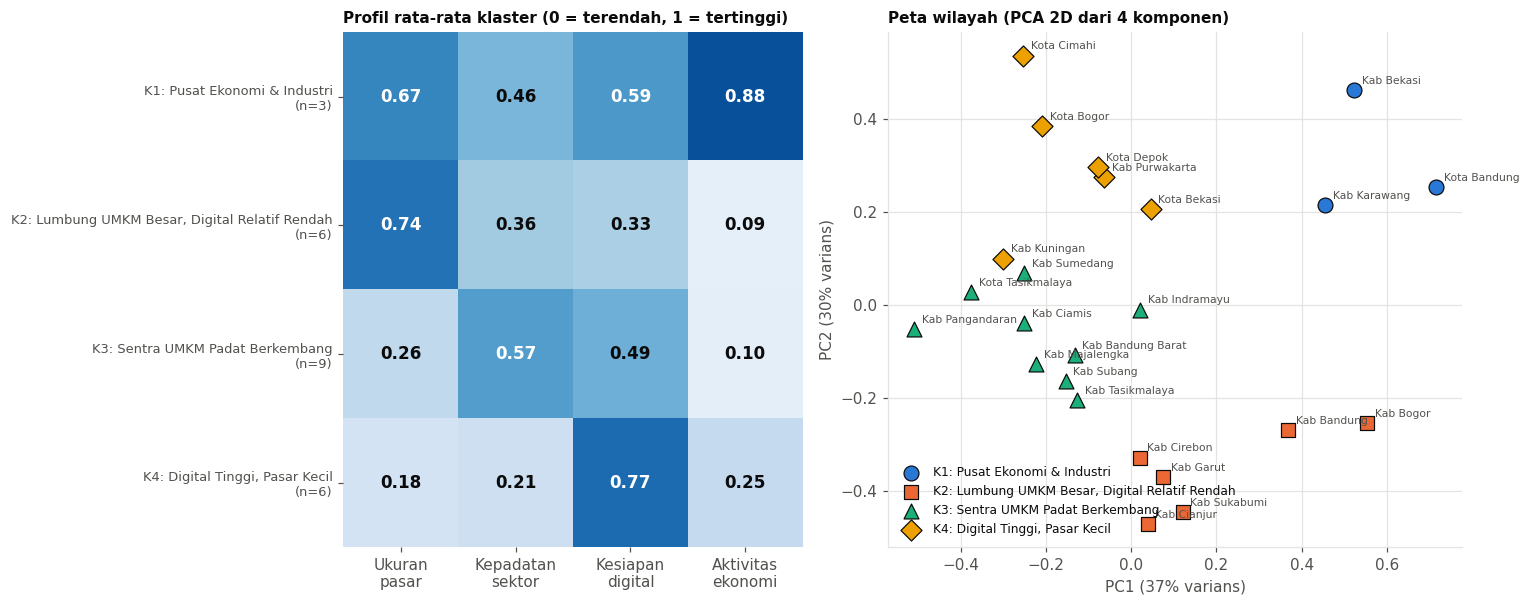

PCA 2 komponen menjelaskan 67% varians (sisanya tidak tergambar di peta)


In [40]:
# Heatmap profil klaster + proyeksi PCA 2D
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1, 1.25]})
M = prof[["ukuran_norm", "kepadatan_norm", "digital_norm", "pdrb_norm"]].values
im = ax[0].imshow(M, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["Ukuran\npasar", "Kepadatan\nsektor", "Kesiapan\ndigital", "Aktivitas\nekonomi"])
ax[0].set_yticks(range(len(prof))); ax[0].set_yticklabels([f"K{i}: {NAMA_K[i]}\n(n={int(prof.loc[i, 'jumlah_wilayah'])})" for i in prof.index], fontsize=8.5)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax[0].text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=11, fontweight="bold", color="white" if M[i, j] > 0.55 else TEKS)
ax[0].set_title("Profil rata-rata klaster (0 = terendah, 1 = tertinggi)", loc="left", fontweight="bold", fontsize=10)
for s in ax[0].spines.values(): s.set_visible(False)

pca = PCA(n_components=2, random_state=SEED).fit(X); Z = pca.transform(X)
for no in sorted(NAMA_K):
    idx = (W["klaster"] == no).values
    ax[1].scatter(Z[idx, 0], Z[idx, 1], s=95, c=WARNA_K[no], marker=MARKER_K[no], edgecolor=TEKS, lw=0.8, label=f"K{no}: {NAMA_K[no]}", zorder=3)
for i, nm in enumerate(W["nama"]):
    ax[1].annotate(nm.replace("Kab. ", "Kab ").replace("Kota ", "Kota "), (Z[i, 0], Z[i, 1]), textcoords="offset points", xytext=(5, 4), fontsize=7, color=TEKS2)
gaya(ax[1], "both"); ax[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% varians)"); ax[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% varians)")
ax[1].set_title("Peta wilayah (PCA 2D dari 4 komponen)", loc="left", fontweight="bold", fontsize=10)
ax[1].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout(); fig.savefig(f"{GAMBAR}/k3_profil_klaster.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"PCA 2 komponen menjelaskan {pca.explained_variance_ratio_.sum()*100:.0f}% varians (sisanya tidak tergambar di peta)")

**Interpretasi bisnis tiap klaster:**

| Klaster | Anggota | Ciri utama | Implikasi untuk Klay |
|---|---|---|---|
| **K1. Pusat Ekonomi & Industri** (3) | Kota Bandung, Kab. Bekasi, Kab. Karawang | PDRB per kapita sangat tinggi (rata-rata Rp125,7 juta, versus Rp33 sampai 52 juta di klaster lain), pasar besar (rata-rata 320 ribu UMKM sasaran), kesiapan digital menengah-tinggi (0,59) | Daya beli kuat dan pasar besar. Calon target gelombang pertama. |
| **K2. Lumbung UMKM Besar, Digital Relatif Rendah** (6) | Kab. Bogor, Kab. Bandung, Kab. Sukabumi, Kab. Cianjur, Kab. Garut, Kab. Cirebon | Basis UMKM terbesar (rata-rata 349 ribu), tetapi kesiapan digital (0,33) dan PDRB (0,09) rendah | Banyak calon klien, tetapi perlu edukasi dan pendekatan lebih lama. Cocok untuk gelombang berikutnya atau lewat kemitraan. |
| **K3. Sentra UMKM Padat Berkembang** (9) | Kab. Tasikmalaya, Ciamis, Majalengka, Sumedang, Indramayu, Subang, Bandung Barat, Pangandaran, Kota Tasikmalaya | UMKM paling padat per penduduk (rata-rata 129 per 1.000), pasar absolut menengah (168 ribu), digital menengah (0,49), PDRB rendah | Tiap penjualan butuh biaya jangkau lebih besar karena UMKM tersebar. Cocok untuk penjangkauan lewat komunitas. |
| **K4. Digital Tinggi, Pasar Kecil** (6) | Kota Bogor, Kota Bekasi, Kota Depok, Kota Cimahi, Kab. Purwakarta, Kab. Kuningan | Kesiapan digital tertinggi (0,77; 4G menjangkau 97% desa/kelurahan; 35% pemuda memakai komputer), tetapi pasar kecil (rata-rata 137 ribu) dan kepadatan rendah | UMKM mudah diajak memakai aplikasi. Cocok untuk penjangkauan daring berbiaya rendah. |

**Catatan kehati-hatian:** Kab. Purwakarta (silhouette 0,06), Kab. Kuningan (0,10), Kab. Bekasi (0,11), dan Kab. Cirebon (0,14) ada di perbatasan klasternya. Dua anggota K4 yang bukan kota (Purwakarta dan Kuningan) kesiapan digitalnya hanya menengah (0,44 dan 0,60), jadi label "digital tinggi" paling cocok untuk empat kota di klaster itu.

**Catatan membaca klaster:** karena klaster dibentuk dari empat komponen yang sama dengan penyusun skor ICP, klaster di Bagian C dipakai untuk **menjelaskan dari mana skor berasal dan pendekatan apa yang cocok**, bukan sebagai bukti independen bahwa skor ICP benar.

**Langkah B5. Uji ketahanan klaster.** Dua cek: (1) memakai k = 5, (2) memakai 7 indikator terpisah (digital tidak dirata-rata). Ini untuk melihat seberapa kuat pengelompokan terhadap pilihan teknis.

In [41]:
# Uji ketahanan 1: bagaimana kalau memakai k=5 (silhouette dan Davies-Bouldin sedikit lebih baik, tapi ada klaster beranggota 1)
km5 = KMeans(n_clusters=5, n_init=100, random_state=SEED).fit(X)
print("k=5, ukuran tiap klaster:", np.bincount(km5.labels_).tolist())
for c in range(5):
    print("  -", ", ".join(W.loc[km5.labels_ == c, "nama"]))
print("ARI k=4 vs k=5:", round(adjusted_rand_score(W["klaster_raw"], km5.labels_), 3))

# Uji ketahanan 2: memakai 7 indikator terpisah (digital tidak dirata-rata) alih-alih 4 komponen
fit7 = ["umkm_sasaran", "umkm_sasaran_per_1000"] + DIGITAL + ["pdrb_per_kapita"]
X7 = np.column_stack([min_max(lolos[c]) for c in fit7])
l7 = KMeans(n_clusters=K_FINAL, n_init=100, random_state=SEED).fit(X7).labels_
print(f"k={K_FINAL} dengan 7 indikator: silhouette {silhouette_score(X7, l7):.3f}, ARI terhadap klaster 4 komponen {adjusted_rand_score(W['klaster_raw'], l7):.3f}")

k=5, ukuran tiap klaster: [9, 6, 2, 1, 6]
  - Kab. Tasikmalaya, Kab. Ciamis, Kab. Majalengka, Kab. Sumedang, Kab. Indramayu, Kab. Subang, Kab. Bandung Barat, Kab. Pangandaran, Kota Tasikmalaya
  - Kab. Bogor, Kab. Sukabumi, Kab. Cianjur, Kab. Bandung, Kab. Garut, Kab. Cirebon
  - Kab. Karawang, Kab. Bekasi
  - Kota Bandung
  - Kab. Kuningan, Kab. Purwakarta, Kota Bogor, Kota Bekasi, Kota Depok, Kota Cimahi
ARI k=4 vs k=5: 0.98
k=4 dengan 7 indikator: silhouette 0.266, ARI terhadap klaster 4 komponen 0.469


**Hasil uji ketahanan:**
- **k = 5** hampir sama dengan k = 4 (ARI 0,98): satu-satunya perubahan adalah Kota Bandung terpisah sendirian dari K1. Jadi pemisahan K1 sampai K4 cukup konsisten.
- **7 indikator terpisah** menghasilkan pengelompokan yang cukup berbeda (ARI 0,47; silhouette 0,27). Artinya klaster **sensitif terhadap cara menyusun fitur**, terutama karena indikator digital yang berjumlah 4 mendominasi jarak bila tidak dirata-rata. Keputusan memakai 4 komponen mengikuti struktur ICP (tiap komponen satu suara), dan ini dicatat sebagai keterbatasan.

## C. Indeks Prioritas ICP

**Langkah C1. Menghitung skor tiap segmen.** Segmen = sektor x wilayah, jadi ada 2 x 24 = 48 segmen. Skor tiap segmen:

**Skor ICP = 0,30 x Ukuran pasar + 0,25 x Kepadatan sektor + 0,25 x Kesiapan digital + 0,20 x Aktivitas ekonomi**

- Ukuran pasar dan kepadatan sektor dihitung **per sektor** lalu dinormalisasi Min-Max di antara 48 segmen. Dengan cara ini ukuran pasar sektor yang memang lebih kecil ikut terbawa (F&B memang sekitar 5,9 kali lebih banyak dari Jasa).
- Kesiapan digital dan aktivitas ekonomi adalah data tingkat wilayah, jadi nilainya sama untuk F&B dan Jasa di wilayah yang sama.
- Semua komponen berskala 0 sampai 1, sehingga skor akhir juga 0 sampai 1.

In [42]:
BOBOT = {"ukuran": 0.30, "kepadatan": 0.25, "digital": 0.25, "pdrb": 0.20}      # dari Bagian I.8 (rancangan bobot)
assert abs(sum(BOBOT.values()) - 1) < 1e-9

# Segmen = sektor x wilayah. Tiap wilayah menghasilkan 2 segmen: F&B dan Jasa (proksi)
baris = []
for sektor, kol in (("F&B", "umkm_fnb"), ("Jasa", "umkm_jasa")):
    for _, r in data.iterrows():
        baris.append({"sektor": sektor, "wilayah": r["nama_standar"], "klaster": int(r["klaster"]),
                      "umkm": r[kol], "per1000": r[kol] / r["penduduk"] * 1000,
                      "digital": r["digital"], "pdrb": r["pdrb"], "pdrb_juta": r["pdrb_per_kapita"] / 1000,
                      "sinyal_4g": r["sinyal_4g_pct"], "pemuda_komputer": r["pemuda_komputer"]})
S = pd.DataFrame(baris)
S["ukuran"]    = min_max(S["umkm"])        # dinormalisasi antar 48 segmen, jadi ukuran pasar sektor ikut menentukan
S["kepadatan"] = min_max(S["per1000"])
# digital dan pdrb sudah 0-1 (dinormalisasi antar 24 wilayah) dan sama untuk kedua sektor di satu wilayah

def skor(df, w):
    return w["ukuran"] * df["ukuran"] + w["kepadatan"] * df["kepadatan"] + w["digital"] * df["digital"] + w["pdrb"] * df["pdrb"]

S["icp"] = skor(S, BOBOT)
for k, v in BOBOT.items(): S["kontribusi_" + k] = v * S[k]
S["peringkat_icp"] = S["icp"].rank(ascending=False, method="first").astype(int)
S["peringkat_baseline"] = S["umkm"].rank(ascending=False, method="first").astype(int)
S["segmen"] = S["sektor"] + " | " + S["wilayah"]
S = S.sort_values("peringkat_icp").reset_index(drop=True)
print(f"Jumlah segmen: {len(S)} (2 sektor x 24 wilayah). Rentang skor ICP: {S['icp'].min():.3f} sampai {S['icp'].max():.3f}")
S[["peringkat_icp", "sektor", "wilayah", "umkm", "per1000", "ukuran", "kepadatan", "digital", "pdrb", "icp"]].head(15).round(3)

Jumlah segmen: 48 (2 sektor x 24 wilayah). Rentang skor ICP: 0.075 sampai 0.894


,peringkat_icp,sektor,wilayah,umkm,per1000,ukuran,kepadatan,digital,pdrb,icp
0,1,F&B,Kota Bandung,349811,139.556,0.915,0.980,0.696,1.000,0.894
1,2,F&B,Kab. Bekasi,234987,72.585,0.606,0.468,0.671,0.842,0.635
2,3,F&B,Kab. Bandung,359309,96.560,0.940,0.651,0.551,0.158,0.614
3,4,F&B,Kab. Karawang,237595,94.060,0.613,0.632,0.414,0.787,0.603
4,5,F&B,Kab. Bogor,381452,67.789,1.000,0.431,0.429,0.243,0.564
5,6,F&B,Kota Bekasi,206524,78.610,0.529,0.514,0.870,0.191,0.543
6,7,F&B,Kota Depok,165161,76.984,0.418,0.501,0.954,0.153,0.520
7,8,F&B,Kota Cimahi,57881,97.974,0.129,0.662,0.939,0.390,0.517
8,9,F&B,Kab. Indramayu,194308,102.574,0.496,0.697,0.499,0.271,0.502
9,10,F&B,Kab. Cirebon,256917,108.843,0.665,0.745,0.396,0.027,0.490


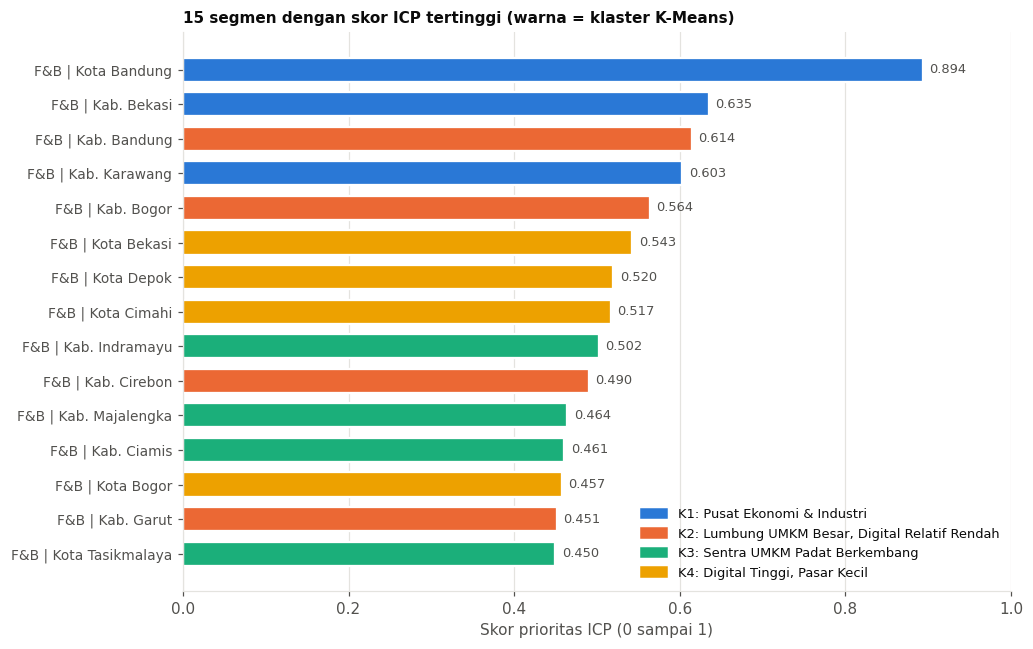

Skor ICP tertinggi untuk sektor Jasa (segmen Jasa tidak masuk 15 besar):


,peringkat_icp,wilayah,umkm,icp
15,16,Kota Bandung,59201,0.437
24,25,Kab. Bekasi,39769,0.362
26,27,Kota Cimahi,9796,0.322


In [43]:
t = S.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.barh(range(len(t)), t["icp"], color=[WARNA_K[k] for k in t["klaster"]], height=0.7, edgecolor="white", lw=1.5)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t["segmen"], fontsize=9)
for i, v in enumerate(t["icp"]): ax.text(v + 0.008, i, f"{v:.3f}", va="center", fontsize=8.5, color=TEKS2)
gaya(ax, "x"); ax.set_xlim(0, 1.0); ax.set_xlabel("Skor prioritas ICP (0 sampai 1)")
ax.set_title("15 segmen dengan skor ICP tertinggi (warna = klaster K-Means)", loc="left", fontweight="bold")
ax.legend(handles=[Patch(color=WARNA_K[n], label=f"K{n}: {NAMA_K[n]}") for n in sorted(NAMA_K)], frameon=False, fontsize=8.5, loc="lower right")
plt.tight_layout(); fig.savefig(f"{GAMBAR}/i1_top15_icp.png", dpi=200, bbox_inches="tight"); plt.show()
print("Skor ICP tertinggi untuk sektor Jasa (segmen Jasa tidak masuk 15 besar):")
S[S["sektor"] == "Jasa"].head(3)[["peringkat_icp", "wilayah", "umkm", "icp"]].round(3)

**Interpretasi:** semua 15 segmen teratas adalah F&B. Ini **bukan** temuan bahwa F&B lebih bagus di tiap wilayah. Data UMKM kami adalah proyeksi dengan komposisi sektor yang seragam di semua wilayah (F&B 85,5% dan Jasa 14,5% di semua wilayah), jadi segmen F&B otomatis lebih besar dan lebih padat daripada Jasa di wilayah yang sama. Segmen Jasa terbaik adalah Kota Bandung di peringkat 16 (skor 0,437). Yang benar-benar diinformasikan data adalah **perbedaan antar wilayah**, bukan antar sektor.

**Langkah C2. Membandingkan dengan baseline.** Baseline adalah cara paling sederhana: segmen diurutkan hanya berdasarkan jumlah UMKM, tanpa memperhitungkan kepadatan, kesiapan digital, dan PDRB. Dibandingkan: (a) berapa segmen Top 5 yang sama, (b) korelasi peringkat (Spearman), (c) segmen mana yang bergeser, dan (d) karakter 5 segmen teratas menurut dua metode.

In [44]:
# Baseline: segmen diurutkan hanya berdasarkan jumlah UMKM (tanpa bobot kesiapan digital, kepadatan, atau PDRB)
top_icp  = S.nsmallest(5, "peringkat_icp");      top_base = S.nsmallest(5, "peringkat_baseline")
irisan = set(top_icp["segmen"]) & set(top_base["segmen"])
rho, _ = spearmanr(S["icp"], S["umkm"]); tau, _ = kendalltau(S["icp"], S["umkm"])
print(f"Irisan Top 5 ICP dan Top 5 baseline : {len(irisan)} dari 5 -> {sorted(irisan)}")
print(f"Irisan Top 10                      : {len(set(S.nsmallest(10,'peringkat_icp')['segmen']) & set(S.nsmallest(10,'peringkat_baseline')['segmen']))} dari 10")
print(f"Korelasi peringkat (Spearman)      : {rho:.3f}   (Kendall tau {tau:.3f}) untuk 48 segmen")

gab = S[S["segmen"].isin(set(top_icp["segmen"]) | set(top_base["segmen"]))].copy()
gab["geser"] = gab["peringkat_baseline"] - gab["peringkat_icp"]        # positif = naik peringkat setelah ICP
gab["masuk_top5_di"] = np.where(gab["segmen"].isin(top_icp["segmen"]) & gab["segmen"].isin(top_base["segmen"]), "keduanya",
                         np.where(gab["segmen"].isin(top_icp["segmen"]), "hanya ICP", "hanya baseline"))
tbl_base = gab.sort_values("peringkat_icp")[["segmen", "umkm", "peringkat_baseline", "peringkat_icp", "geser", "digital", "sinyal_4g", "pdrb_juta", "masuk_top5_di"]]
print()
tbl_base.round(2)

Irisan Top 5 ICP dan Top 5 baseline : 3 dari 5 -> ['F&B | Kab. Bandung', 'F&B | Kab. Bogor', 'F&B | Kota Bandung']
Irisan Top 10                      : 7 dari 10
Korelasi peringkat (Spearman)      : 0.781   (Kendall tau 0.551) untuk 48 segmen



,segmen,umkm,peringkat_baseline,peringkat_icp,geser,digital,sinyal_4g,pdrb_juta,masuk_top5_di
0,F&B | Kota Bandung,349811,3,1,2,0.70,100.00,140.14,keduanya
1,F&B | Kab. Bekasi,234987,9,2,7,0.67,94.12,121.65,hanya ICP
2,F&B | Kab. Bandung,359309,2,3,-1,0.55,97.50,41.37,keduanya
3,F&B | Kab. Karawang,237595,8,4,4,0.41,95.47,115.17,hanya ICP
4,F&B | Kab. Bogor,381452,1,5,-4,0.43,93.33,51.38,keduanya
13,F&B | Kab. Garut,263565,5,14,-9,0.29,85.97,26.91,hanya baseline
16,F&B | Kab. Sukabumi,273595,4,17,-13,0.17,84.72,29.37,hanya baseline


In [45]:
# Ringkasan karakter 5 segmen teratas menurut dua metode
def ringkas(df):
    return pd.Series({"total UMKM": df["umkm"].sum(), "rata2 kesiapan digital (0-1)": df["digital"].mean(),
                      "rata2 sinyal 4G desa/kel (%)": df["sinyal_4g"].mean(), "rata2 PDRB/kapita (juta Rp)": df["pdrb_juta"].mean(),
                      "rata2 UMKM per 1.000 penduduk": df["per1000"].mean()})
bandingan = pd.DataFrame({"Top 5 baseline (jumlah UMKM saja)": ringkas(top_base), "Top 5 skor ICP": ringkas(top_icp)})
bandingan["selisih ICP - baseline"] = bandingan.iloc[:, 1] - bandingan.iloc[:, 0]
bandingan.round(2)

,Top 5 baseline (jumlah UMKM saja),Top 5 skor ICP,selisih ICP - baseline
total UMKM,1627732.00,1563154.00,-64578.00
rata2 kesiapan digital (0-1),0.43,0.55,0.12
rata2 sinyal 4G desa/kel (%),92.30,96.08,3.78
rata2 PDRB/kapita (juta Rp),57.84,93.94,36.11
rata2 UMKM per 1.000 penduduk,99.95,94.11,-5.84


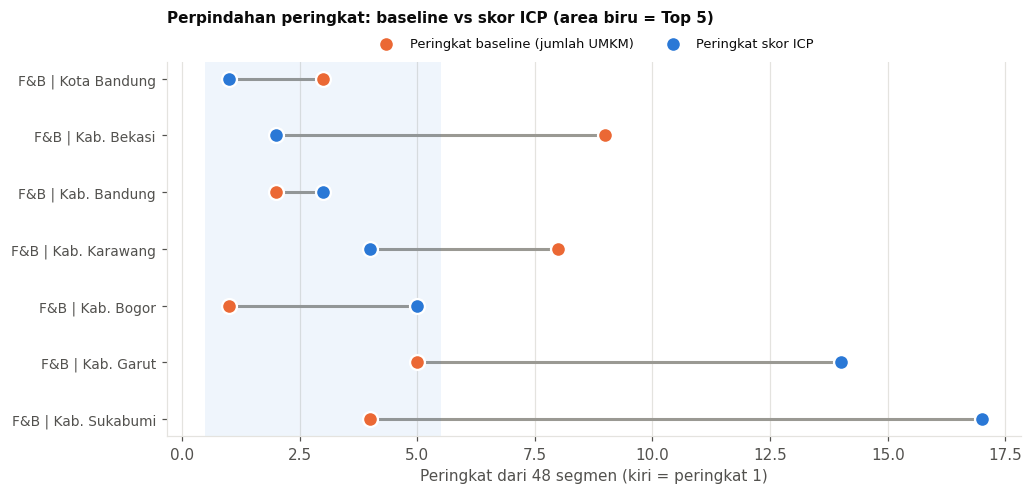

In [46]:
g = tbl_base.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for i, r in g.iterrows():
    ax.plot([r["peringkat_baseline"], r["peringkat_icp"]], [i, i], color=ABU, lw=2, zorder=1)
ax.scatter(g["peringkat_baseline"], range(len(g)), s=95, color=ORANYE, edgecolor="white", lw=1.5, zorder=3, label="Peringkat baseline (jumlah UMKM)")
ax.scatter(g["peringkat_icp"], range(len(g)), s=95, color=BIRU, edgecolor="white", lw=1.5, zorder=3, label="Peringkat skor ICP")
ax.set_yticks(range(len(g))); ax.set_yticklabels(g["segmen"], fontsize=9)
ax.set_xlabel("Peringkat dari 48 segmen (kiri = peringkat 1)"); gaya(ax, "x")
ax.axvspan(5.5, 0.5, color=BIRU, alpha=0.07, lw=0)
ax.set_title("Perpindahan peringkat: baseline vs skor ICP (area biru = Top 5)", loc="left", fontweight="bold", pad=26); ax.legend(frameon=False, fontsize=8.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.tight_layout(); fig.savefig(f"{GAMBAR}/i2_baseline_vs_icp.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretasi perbandingan baseline:**
- **3 dari 5** segmen Top 5 sama (Kota Bandung, Kab. Bandung, Kab. Bogor), dan korelasi peringkat 0,78. Jadi ukuran pasar memang pendorong utama, tetapi skor ICP **mengubah dua posisi**.
- **Masuk karena ICP:** F&B Kab. Bekasi (peringkat 9 -> 2) dan F&B Kab. Karawang (8 -> 4). Keduanya punya PDRB per kapita sangat tinggi (Rp122 juta dan Rp115 juta) dan kesiapan digital menengah.
- **Turun karena ICP:** F&B Kab. Sukabumi (4 -> 17) dan F&B Kab. Garut (5 -> 14). Keduanya pasar besar tetapi kesiapan digital rendah (0,17 dan 0,29) dan PDRB rendah.
- **Dampaknya untuk tim Sales:** Top 5 ICP punya rata-rata kesiapan digital 0,55 (baseline 0,43), cakupan 4G 96,1% (baseline 92,3%), dan PDRB per kapita Rp93,9 juta (baseline Rp57,8 juta), dengan total UMKM hanya 4% lebih sedikit (1,56 juta vs 1,63 juta). Artinya pasar yang dijangkau hampir sama besarnya, tetapi lebih siap secara digital dan lebih mampu membayar. Catatan: kepadatan UMKM per 1.000 penduduk Top 5 ICP sedikit lebih rendah (94 vs 100).
- **Catatan sirkular:** kesiapan digital dan PDRB adalah komponen skor ICP itu sendiri, jadi Top 5 ICP otomatis lebih tinggi di dua hal itu dibanding baseline. Selisih ini menunjukkan bahwa skor bekerja sesuai rancangannya, **bukan** bukti independen bahwa hasilnya lebih baik.
- Klaim ini hanya soal **kesiapan** menurut proksi data, bukan bukti bahwa konversi penjualan akan lebih tinggi. Itu perlu diuji di lapangan.

**Langkah C3. Uji sensitivitas bobot.** Kita ubah bobot supaya tahu apakah Top 5 berubah drastis. Dua uji:
1. **Skenario terarah**: tiap komponen dinaikkan atau diturunkan 5 dan 10 poin bobot (bobot lainnya diskalakan proporsional agar total tetap 100%), ditambah satu skenario bobot sama (25 x 4). Fokus utama sesuai instruksi: Kesiapan digital dan PDRB.
2. **Simulasi acak**: 10.000 kali tiap bobot digeser acak antara -10 dan +10 poin, lalu dihitung seberapa sering tiap segmen masuk Top 5.

In [47]:
def geser(w, kunci, d):
    """Naik/turunkan bobot satu komponen sebesar d (poin bobot); bobot lain diskalakan proporsional agar total tetap 100%."""
    w = dict(w); baru = w[kunci] + d; lain = [k for k in w if k != kunci]; tot = sum(w[k] for k in lain)
    for k in lain: w[k] = w[k] * (1 - baru) / tot
    w[kunci] = baru; return w

NAMA_KOMP = {"digital": "Kesiapan digital", "pdrb": "PDRB per kapita", "ukuran": "Ukuran pasar", "kepadatan": "Kepadatan sektor"}
skenario = {"Dasar (30/25/25/20)": BOBOT}
for kunci in ["digital", "pdrb", "ukuran", "kepadatan"]:
    for d in (-0.10, -0.05, 0.05, 0.10):
        skenario[f"{NAMA_KOMP[kunci]} {d*100:+.0f}"] = geser(BOBOT, kunci, d)
skenario["Bobot sama (25 x 4)"] = {k: 0.25 for k in BOBOT}

top0 = list(S.nsmallest(5, "peringkat_icp")["segmen"]); skor0 = S["icp"]
hasil = []; peringkat_skenario = {}
for nama, w in skenario.items():
    sc = skor(S, w); urut = S.assign(sk=sc).sort_values("sk", ascending=False)
    top = list(urut["segmen"].head(5)); peringkat_skenario[nama] = {s: i + 1 for i, s in enumerate(urut["segmen"])}
    hasil.append({"skenario": nama, "bobot u/k/d/p (%)": "/".join(f"{w[k]*100:.0f}" for k in ["ukuran", "kepadatan", "digital", "pdrb"]),
                  "irisan_dgn_Top5_dasar": len(set(top) & set(top0)), "spearman_48_segmen": spearmanr(sc, skor0)[0],
                  "peringkat_1": top[0].replace("F&B | ", ""), "Top5": ", ".join(t.replace("F&B | ", "") for t in top)})
uji = pd.DataFrame(hasil)
print("Irisan = berapa dari 5 segmen Top 5 dasar yang masih ada di Top 5 skenario. Spearman = kemiripan urutan 48 segmen.")
print(f"Skenario geser +-5 / +-10 poin pada Kesiapan digital dan PDRB: irisan minimum = {uji[uji['skenario'].str.contains('digital|PDRB')]['irisan_dgn_Top5_dasar'].min()} dari 5")
uji.round(3)

Irisan = berapa dari 5 segmen Top 5 dasar yang masih ada di Top 5 skenario. Spearman = kemiripan urutan 48 segmen.
Skenario geser +-5 / +-10 poin pada Kesiapan digital dan PDRB: irisan minimum = 3 dari 5


,skenario,bobot u/k/d/p (%),irisan_dgn_Top5_dasar,spearman_48_segmen,peringkat_1,Top5
0,Dasar (30/25/25/20),30/25/25/20,5,1.000,Kota Bandung,"Kota Bandung, Kab. Bekasi, Kab. Bandung, Kab. Karawang, Kab. Bogor"
1,Kesiapan digital -10,34/28/15/23,5,0.980,Kota Bandung,"Kota Bandung, Kab. Bekasi, Kab. Karawang, Kab. Bandung, Kab. Bogor"
2,Kesiapan digital -5,32/27/20/21,5,0.994,Kota Bandung,"Kota Bandung, Kab. Bekasi, Kab. Bandung, Kab. Karawang, Kab. Bogor"
3,Kesiapan digital +5,28/23/30/19,4,0.996,Kota Bandung,"Kota Bandung, Kab. Bekasi, Kab. Bandung, Kab. Karawang, Kota Bekasi"
4,Kesiapan digital +10,26/22/35/17,3,0.988,Kota Bandung,"Kota Bandung, Kab. Bekasi, Kab. Bandung, Kota Bekasi, Kota Depok"
5,PDRB per kapita -10,34/28/28/10,4,0.989,Kota Bandung,"Kota Bandung, Kab. Bandung, Kab. Bekasi, Kab. Bogor, Kota Bekasi"
6,PDRB per kapita -5,32/27/27/15,5,0.995,Kota Bandung,"Kota Bandung, Kab. Bandung, Kab. Bekasi, Kab. Karawang, Kab. Bogor"
7,PDRB per kapita +5,28/23/23/25,5,0.995,Kota Bandung,"Kota Bandung, Kab. Bekasi, Kab. Karawang, Kab. Bandung, Kab. Bogor"
8,PDRB per kapita +10,26/22/22/30,5,0.976,Kota Bandung,"Kota Bandung, Kab. Bekasi, Kab. Karawang, Kab. Bandung, Kab. Bogor"
9,Ukuran pasar -10,20/29/29/23,4,0.984,Kota Bandung,"Kota Bandung, Kab. Bekasi, Kab. Karawang, Kota Cimahi, Kab. Bandung"


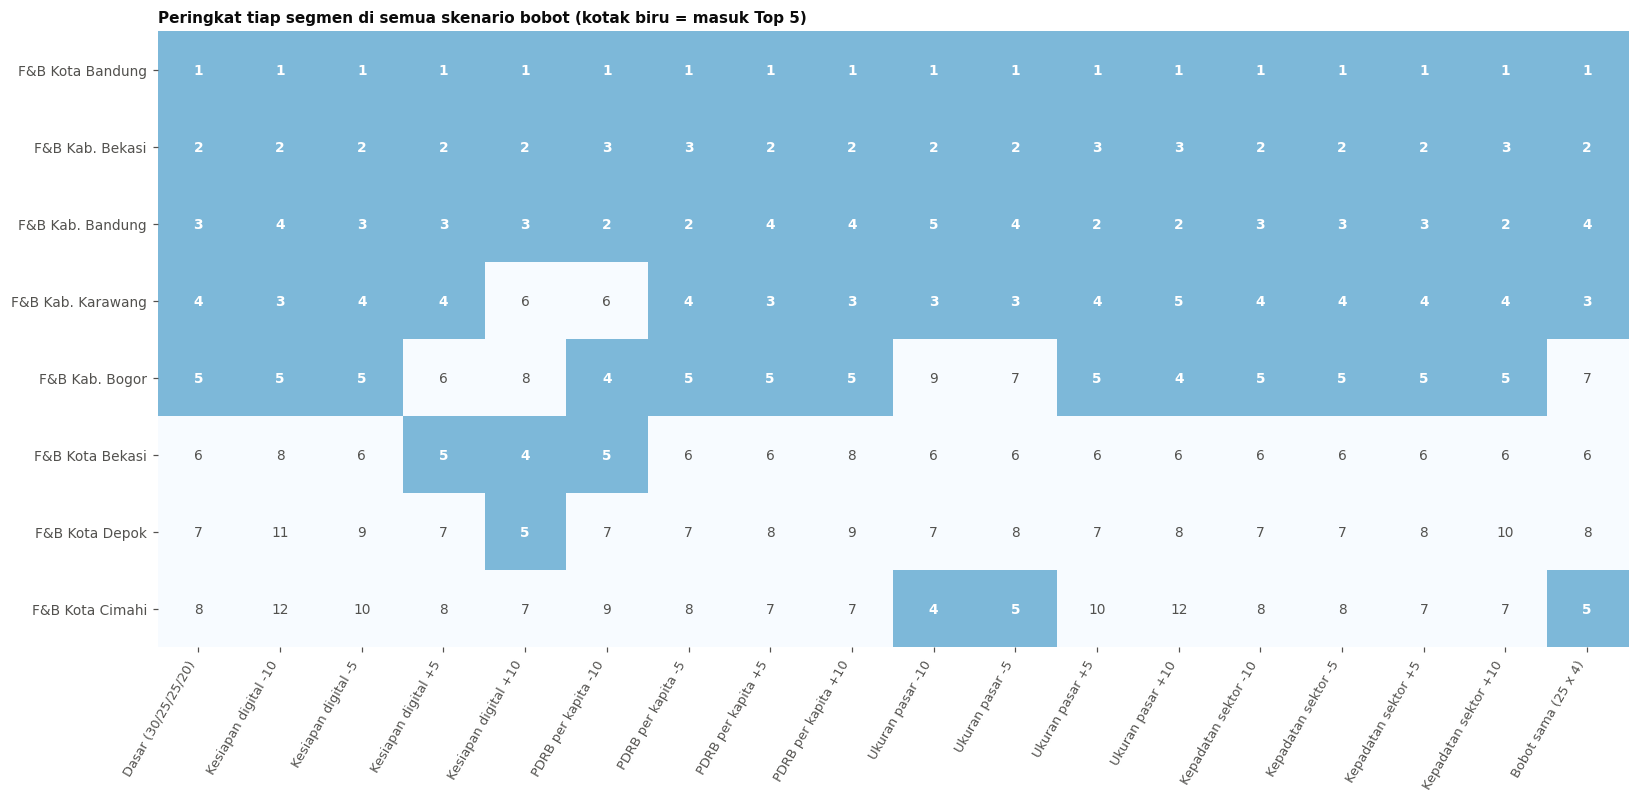

In [48]:
# Matriks peringkat: segmen yang pernah masuk Top 5 di salah satu skenario
pernah = []
for nama in skenario:
    for s, p in peringkat_skenario[nama].items():
        if p <= 5 and s not in pernah: pernah.append(s)
pernah = sorted(pernah, key=lambda s: peringkat_skenario["Dasar (30/25/25/20)"][s])
M = np.array([[peringkat_skenario[n][s] for n in skenario] for s in pernah], dtype=float)
fig, ax = plt.subplots(figsize=(15, 0.55 * len(pernah) + 3))
Mp = np.where(M <= 5, M, np.nan)
ax.imshow(np.where(M <= 5, 1, 0), cmap="Blues", vmin=0, vmax=2.2, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = int(M[i, j]); ax.text(j, i, str(v) if v <= 12 else ">12", ha="center", va="center", fontsize=9,
                                  fontweight="bold" if v <= 5 else "normal", color="white" if v <= 5 else TEKS2)
ax.set_xticks(range(len(skenario))); ax.set_xticklabels(list(skenario), rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(range(len(pernah))); ax.set_yticklabels([p.replace("F&B | ", "F&B ") for p in pernah], fontsize=9)
ax.set_title("Peringkat tiap segmen di semua skenario bobot (kotak biru = masuk Top 5)", loc="left", fontweight="bold")
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); fig.savefig(f"{GAMBAR}/i3_sensitivitas_matriks.png", dpi=200, bbox_inches="tight"); plt.show()

In [49]:
# Uji sensitivitas acak: 10.000 kali bobot digeser acak antara -10 dan +10 poin per komponen (lalu dinormalkan ke 100%)
rng = np.random.default_rng(SEED); N = 10000
dasar = np.array([BOBOT[k] for k in ["ukuran", "kepadatan", "digital", "pdrb"]])
mat = S[["ukuran", "kepadatan", "digital", "pdrb"]].values
hitung = np.zeros(len(S)); peringkat_1 = np.zeros(len(S))
for _ in range(N):
    w = np.clip(dasar + rng.uniform(-0.10, 0.10, 4), 0.05, None); w = w / w.sum()
    sc = mat @ w; top = np.argsort(-sc)[:5]
    hitung[top] += 1; peringkat_1[top[0]] += 1
mc = pd.DataFrame({"segmen": S["segmen"], "peluang_Top5_pct": hitung / N * 100, "peluang_peringkat1_pct": peringkat_1 / N * 100,
                   "peringkat_dasar": S["peringkat_icp"]}).sort_values("peluang_Top5_pct", ascending=False)
mc_tampil = mc[mc["peluang_Top5_pct"] > 0.5].reset_index(drop=True)
print(f"{N:,} simulasi bobot. Segmen yang pernah masuk Top 5 lebih dari 0,5% simulasi:")
mc_tampil.round(1)

10,000 simulasi bobot. Segmen yang pernah masuk Top 5 lebih dari 0,5% simulasi:


,segmen,peluang_Top5_pct,peluang_peringkat1_pct,peringkat_dasar
0,F&B | Kota Bandung,100.0,100.0,1
1,F&B | Kab. Bekasi,100.0,0.0,2
2,F&B | Kab. Bandung,99.5,0.0,3
3,F&B | Kab. Karawang,91.6,0.0,4
4,F&B | Kab. Bogor,68.3,0.0,5
5,F&B | Kota Bekasi,20.7,0.0,6
6,F&B | Kota Cimahi,15.7,0.0,8
7,F&B | Kota Depok,3.1,0.0,7
8,Jasa | Kota Bandung,1.1,0.0,16


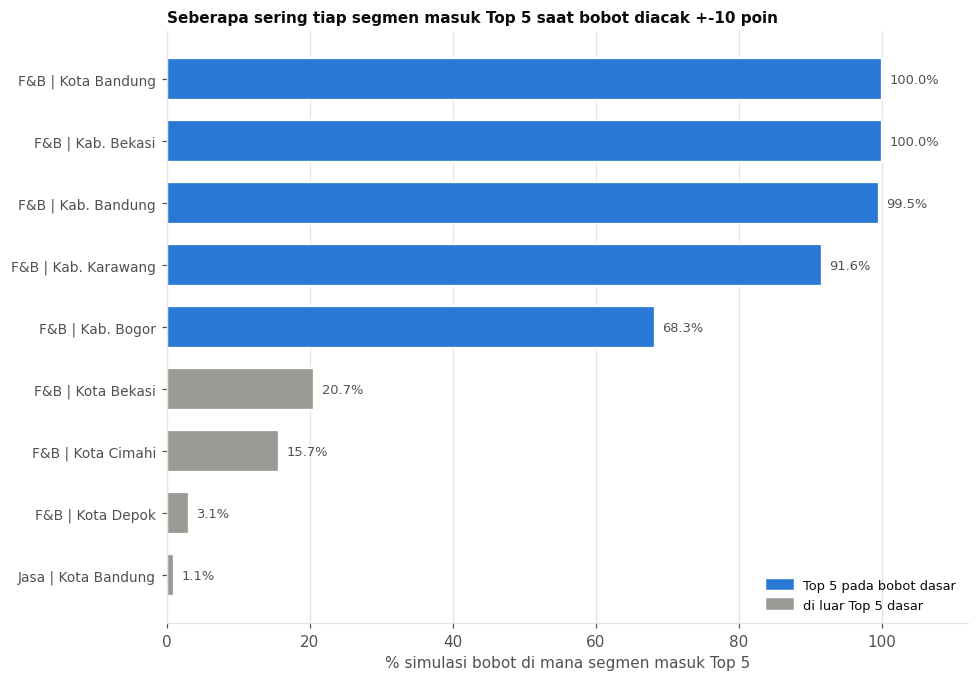

In [50]:
t = mc_tampil.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.5 * len(t) + 1.8))
ax.barh(range(len(t)), t["peluang_Top5_pct"], color=[BIRU if p <= 5 else ABU for p in t["peringkat_dasar"]], height=0.68, edgecolor="white", lw=1.5)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t["segmen"], fontsize=9)
for i, v in enumerate(t["peluang_Top5_pct"]): ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8.5, color=TEKS2)
gaya(ax, "x"); ax.set_xlim(0, 112); ax.set_xlabel("% simulasi bobot di mana segmen masuk Top 5")
ax.set_title("Seberapa sering tiap segmen masuk Top 5 saat bobot diacak +-10 poin", loc="left", fontweight="bold")
ax.legend(handles=[Patch(color=BIRU, label="Top 5 pada bobot dasar"), Patch(color=ABU, label="di luar Top 5 dasar")], frameon=False, fontsize=8.5, loc="lower right")
plt.tight_layout(); fig.savefig(f"{GAMBAR}/i4_sensitivitas_acak.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretasi uji sensitivitas:**
- **Stabil:** Kota Bandung peringkat 1 di **semua** 18 skenario (dan di 100% simulasi acak). Kab. Bekasi dan Kab. Bandung selalu masuk Top 5 (peringkat 2 sampai 5). Urutan seluruh 48 segmen sangat mirip dengan urutan dasar (Spearman 0,976 sampai 0,997).
- **Berubah sedikit:** 12 dari 18 skenario menghasilkan Top 5 yang persis sama dengan dasar, 5 skenario mengganti satu segmen, dan hanya 1 skenario (Kesiapan digital +10) mengganti dua segmen. Pada skenario geser 5 sampai 10 poin di Kesiapan digital dan PDRB, minimal 3 dari 5 segmen tetap sama.
- **Slot 4 dan 5 diperebutkan:** Kab. Karawang masuk Top 5 di 91,6% simulasi, Kab. Bogor 68,3%, lalu Kota Bekasi (20,7%) dan Kota Cimahi (15,7%) mengisi sisanya. Bila kesiapan digital diberi bobot lebih besar, Kota Bekasi dan Kota Depok naik; bila ukuran pasar dikurangi, Kota Cimahi naik.
- **Kesimpulan:** Top 5 **cukup tahan** untuk dipresentasikan. Tiga segmen inti (Kota Bandung, Kab. Bekasi, Kab. Bandung) kuat terhadap perubahan bobot; Kab. Karawang dan Kab. Bogor lebih rentan dan sebaiknya disebut sebagai kandidat yang bisa bergeser tergantung strategi bobot manajemen.

**Langkah C3b. Uji sensitivitas skala (cara normalisasi).** Uji bobot di atas hanya menggeser bobot. Min-Max sangat dipengaruhi pencilan: tiga wilayah (Kota Bandung, Kab. Bekasi, Kab. Karawang) punya PDRB per kapita jauh di atas yang lain, sehingga 21 wilayah lain terhimpit di skala yang sempit. Sel di bawah mengulang perhitungan skor dengan empat cara normalisasi lain pada PDRB, dan satu skenario di mana semua komponen dinormalisasi berdasarkan peringkat. Tujuannya melihat apakah Top 5 bergantung pada pencilan PDRB.

In [51]:
def rank_norm(s):                    # 0..1 berdasarkan peringkat (tidak terpengaruh pencilan)
    return (s.rank(method="average") - 1) / (len(s) - 1)
def log_mm(s):                       # log dulu, lalu Min-Max
    return min_max(np.log(s))

q1, q3 = lolos["pdrb_per_kapita"].quantile([0.25, 0.75]); BATAS_IQR = q3 + 1.5 * (q3 - q1)
pdrb_raw = lolos.set_index("nama_standar")["pdrb_per_kapita"]
dig_w = S.drop_duplicates("wilayah").set_index("wilayah")["digital"]

def skor_skala(ukuran_fn, kepadatan_fn, digital_fn, pdrb_fn, w=BOBOT):
    u = ukuran_fn(S["umkm"]); k = kepadatan_fn(S["per1000"])
    d = S["wilayah"].map(digital_fn(dig_w)); p = S["wilayah"].map(pdrb_fn(pdrb_raw))
    return w["ukuran"] * u + w["kepadatan"] * k + w["digital"] * d + w["pdrb"] * p

ident = lambda s: s
SKALA = {
    "Dasar (Min-Max semua komponen)":        (min_max, min_max, ident, min_max),
    "PDRB: log lalu Min-Max":                (min_max, min_max, ident, log_mm),
    "PDRB: dipotong di batas pencilan IQR":  (min_max, min_max, ident, lambda s: min_max(s.clip(upper=BATAS_IQR))),
    "PDRB: berdasarkan peringkat":           (min_max, min_max, ident, rank_norm),
    "Semua komponen: berdasarkan peringkat": (rank_norm, rank_norm, rank_norm, rank_norm),
}
nama_seg = S["wilayah"]
rows = []; peringkat_skala = {}
for nm, fns in SKALA.items():
    sc = skor_skala(*fns)
    urut = S.assign(sk=sc).sort_values("sk", ascending=False)
    top = list(urut["segmen"].head(5)); rk = {s: i + 1 for i, s in enumerate(urut["segmen"])}; peringkat_skala[nm] = rk
    rows.append({"skenario": nm, "irisan_dgn_Top5_dasar": len(set(top) & set(top0)), "spearman_48_segmen": spearmanr(sc, S["icp"])[0],
                 "peringkat_F&B_Kab_Bekasi": rk["F&B | Kab. Bekasi"], "peringkat_F&B_Kab_Karawang": rk["F&B | Kab. Karawang"],
                 "peringkat_F&B_Kab_Bogor": rk["F&B | Kab. Bogor"],
                 "Top5": ", ".join(t.replace("F&B | ", "") for t in top)})
    if nm.startswith("Dasar"): assert np.allclose(sc.values, S["icp"].values), "skenario dasar harus sama dengan skor ICP"
uji_skala = pd.DataFrame(rows)

print(f"Batas pencilan IQR PDRB per kapita: Rp{BATAS_IQR/1000:,.0f} juta. Wilayah di atas batas: {', '.join(pdrb_raw[pdrb_raw > BATAS_IQR].index)}")
print()
# Seberapa besar PDRB menyumbang ke skor Top 5 dasar
kon = S[S["segmen"].isin(top0)].set_index("segmen").loc[top0]
print("Porsi kontribusi PDRB terhadap skor ICP, Top 5 dasar:")
for s_, r in kon.iterrows(): print(f"  {s_:22s} skor {r['icp']:.3f} | kontribusi PDRB {r['kontribusi_pdrb']:.3f} ({r['kontribusi_pdrb']/r['icp']*100:.0f}% dari skor)")
print()
uji_skala.round(3)

Batas pencilan IQR PDRB per kapita: Rp89 juta. Wilayah di atas batas: Kab. Karawang, Kab. Bekasi, Kota Bandung

Porsi kontribusi PDRB terhadap skor ICP, Top 5 dasar:
  F&B | Kota Bandung     skor 0.894 | kontribusi PDRB 0.200 (22% dari skor)
  F&B | Kab. Bekasi      skor 0.635 | kontribusi PDRB 0.168 (27% dari skor)
  F&B | Kab. Bandung     skor 0.614 | kontribusi PDRB 0.032 (5% dari skor)
  F&B | Kab. Karawang    skor 0.603 | kontribusi PDRB 0.157 (26% dari skor)
  F&B | Kab. Bogor       skor 0.564 | kontribusi PDRB 0.049 (9% dari skor)



,skenario,irisan_dgn_Top5_dasar,spearman_48_segmen,peringkat_F&B_Kab_Bekasi,peringkat_F&B_Kab_Karawang,peringkat_F&B_Kab_Bogor,Top5
0,Dasar (Min-Max semua komponen),5,1.000,2,4,5,"Kota Bandung, Kab. Bekasi, Kab. Bandung, Kab. Karawang, Kab. Bogor"
1,PDRB: log lalu Min-Max,5,0.995,2,4,5,"Kota Bandung, Kab. Bekasi, Kab. Bandung, Kab. Karawang, Kab. Bogor"
2,PDRB: dipotong di batas pencilan IQR,5,0.990,2,3,5,"Kota Bandung, Kab. Bekasi, Kab. Karawang, Kab. Bandung, Kab. Bogor"
3,PDRB: berdasarkan peringkat,4,0.988,3,6,4,"Kota Bandung, Kab. Bandung, Kab. Bekasi, Kab. Bogor, Kota Bekasi"
4,Semua komponen: berdasarkan peringkat,3,0.951,2,13,14,"Kota Bandung, Kab. Bekasi, Kota Bekasi, Kab. Indramayu, Kab. Bandung"


**Interpretasi uji sensitivitas skala:**
- **Pencilan PDRB tidak mengubah Top 5 secara berarti.** Tiga wilayah di atas batas pencilan IQR (Kab. Karawang, Kab. Bekasi, Kota Bandung; batas Rp89 juta) memang menyumbang 22% sampai 27% dari skor mereka lewat PDRB. Namun bila PDRB dinormalisasi dengan log atau dipotong di batas IQR, Top 5 tetap sama (hanya urutan Kab. Karawang dan Kab. Bandung yang bertukar pada skenario IQR). Bila PDRB diganti peringkat, satu segmen berganti: Kab. Karawang keluar dan Kota Bekasi masuk (irisan 4 dari 5).
- **Cara normalisasi seluruh komponen berpengaruh lebih besar.** Bila semua komponen dinormalisasi berdasarkan peringkat, hanya 3 dari 5 segmen bertahan (Kota Bandung, Kab. Bekasi, Kab. Bandung). Kab. Karawang turun ke peringkat 13 dan Kab. Bogor ke peringkat 14, digantikan Kota Bekasi dan Kab. Indramayu. Spearman 48 segmen tetap tinggi (0,95), jadi urutan keseluruhan mirip tetapi batas Top 5 sensitif.
- **Kesimpulan:** Kota Bandung (peringkat 1), Kab. Bekasi, dan Kab. Bandung tahan terhadap perubahan bobot maupun skala. **Slot 4 dan 5 (Kab. Karawang dan Kab. Bogor) bergantung pada cara menskalakan data**, dan keduanya perlu disajikan sebagai kandidat yang bisa bergeser, bukan sebagai pilihan pasti.

**Langkah C4. Sintesis K-Means dan skor ICP.** Pertanyaannya: bagaimana tipe wilayah dari K-Means berkaitan dengan urutan skor? Wilayah diwakili oleh segmen F&B-nya. Tabel meringkas skor rata-rata tiap klaster, berapa wilayahnya yang masuk Top 5 dan Top 10, serta dari komponen mana skornya berasal.

**Batasan penting:** klaster dibentuk dari empat komponen yang sama dengan penyusun skor ICP, jadi hubungan keduanya **sirkular**. Klaster yang berisi wilayah ber-skor tinggi memang diharapkan, sehingga ini bukan validasi independen. Uji Kruskal-Wallis di bawah ditampilkan sebagai ukuran deskriptif seberapa terpisah klaster pada skor, **bukan** sebagai bukti statistik (p-value nominal, tidak bisa dibaca sebagai signifikansi karena klasternya dibentuk dari data yang sama).

In [52]:
# Sintesis K-Means vs skor ICP. Satu wilayah punya 2 segmen; yang dipakai sebagai wakil wilayah adalah segmen F&B
# (sektor terbesar, 85,5% UMKM sasaran). Urutan wilayah di F&B dan Jasa sama persis pada komponen digital dan PDRB.
fb = S[S["sektor"] == "F&B"].copy()
ringkasan = fb.groupby("klaster").agg(wilayah=("wilayah", "size"), skor_rata2=("icp", "mean"), skor_min=("icp", "min"), skor_maks=("icp", "max"),
                                      masuk_top5=("peringkat_icp", lambda s: int((s <= 5).sum())), masuk_top10=("peringkat_icp", lambda s: int((s <= 10).sum())))
ringkasan["nama_klaster"] = [NAMA_K[i] for i in ringkasan.index]
ringkasan["segmen_terbaik"] = [fb[fb["klaster"] == i].sort_values("icp", ascending=False)["wilayah"].iloc[0] for i in ringkasan.index]
H, p = kruskal(*[fb.loc[fb["klaster"] == i, "icp"] for i in sorted(NAMA_K)])
print(f"Kruskal-Wallis skor ICP antar klaster (deskriptif, sirkular): H = {H:.2f}, p nominal = {p:.4f}. Jangan dibaca sebagai bukti validasi: klaster dibentuk dari komponen yang sama dengan skor.")
# Kontribusi tiap komponen terhadap skor rata-rata klaster
kontr = fb.groupby("klaster")[[f"kontribusi_{k}" for k in BOBOT]].mean()
kontr.columns = ["Ukuran pasar", "Kepadatan sektor", "Kesiapan digital", "Aktivitas ekonomi"]
print()
pd.concat([ringkasan[["nama_klaster", "wilayah", "skor_rata2", "skor_min", "skor_maks", "masuk_top5", "masuk_top10", "segmen_terbaik"]], kontr], axis=1).round(3)

Kruskal-Wallis skor ICP antar klaster (deskriptif, sirkular): H = 8.54, p nominal = 0.0360. Jangan dibaca sebagai bukti validasi: klaster dibentuk dari komponen yang sama dengan skor.



,nama_klaster,wilayah,skor_rata2,skor_min,skor_maks,masuk_top5,masuk_top10,segmen_terbaik,Ukuran pasar,Kepadatan sektor,Kesiapan digital,Aktivitas ekonomi
klaster,,,,,,,,,,,,
1,Pusat Ekonomi & Industri,3,0.710,0.603,0.894,3,3,Kota Bandung,0.213,0.173,0.148,0.175
2,"Lumbung UMKM Besar, Digital Relatif Rendah",6,0.493,0.405,0.614,2,3,Kab. Bandung,0.233,0.159,0.083,0.017
3,Sentra UMKM Padat Berkembang,9,0.440,0.375,0.502,0,1,Kab. Indramayu,0.108,0.189,0.123,0.020
4,"Digital Tinggi, Pasar Kecil",6,0.468,0.360,0.543,0,3,Kota Bekasi,0.087,0.138,0.193,0.050


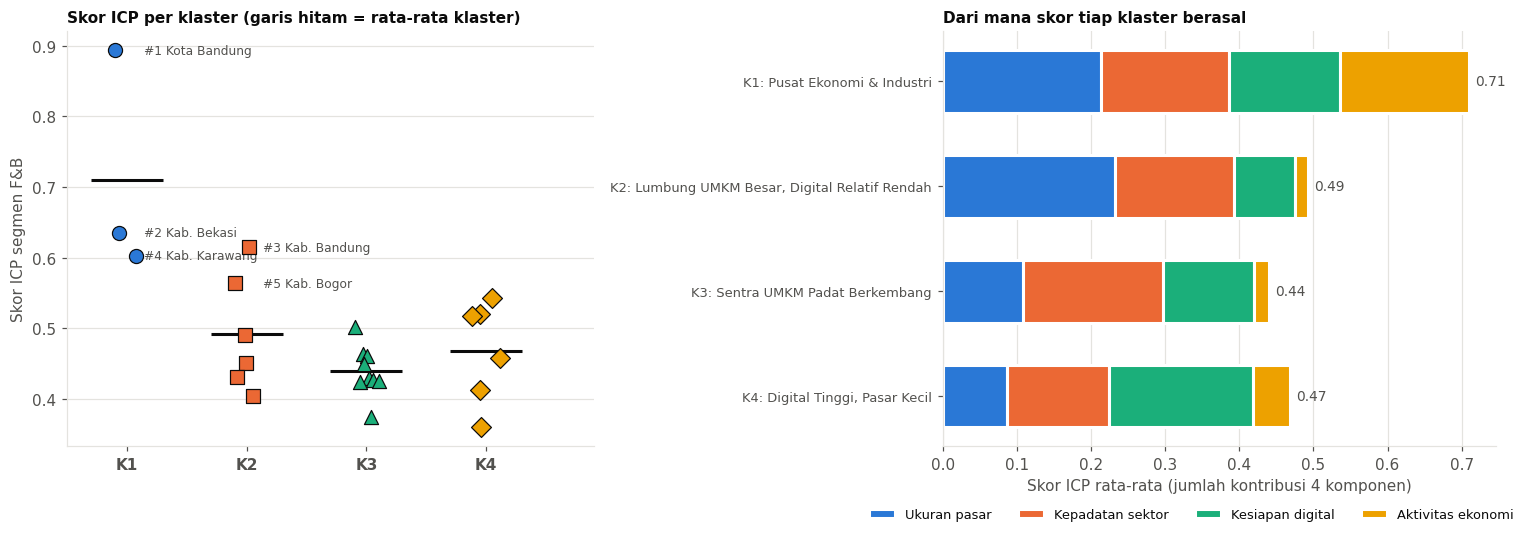

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.05]})
# kiri: sebaran skor ICP (F&B) per klaster, titik = wilayah
rng2 = np.random.default_rng(3)
for no in sorted(NAMA_K):
    g = fb[fb["klaster"] == no]; xs = no + rng2.uniform(-0.12, 0.12, len(g))
    ax[0].scatter(xs, g["icp"], s=85, c=WARNA_K[no], marker=MARKER_K[no], edgecolor=TEKS, lw=0.8, zorder=3)
    ax[0].hlines(g["icp"].mean(), no - 0.3, no + 0.3, color=TEKS, lw=2, zorder=2)
    for _, r in g[g["peringkat_icp"] <= 5].iterrows():
        ax[0].annotate(f"#{r['peringkat_icp']} {r['wilayah']}", (no + 0.14, r["icp"]), fontsize=8, color=TEKS2, va="center")
ax[0].set_xticks(sorted(NAMA_K)); ax[0].set_xticklabels([f"K{n}" for n in sorted(NAMA_K)], fontsize=10, fontweight="bold")
ax[0].set_ylabel("Skor ICP segmen F&B"); gaya(ax[0], "y"); ax[0].set_xlim(0.5, 4.9)
ax[0].set_title("Skor ICP per klaster (garis hitam = rata-rata klaster)", loc="left", fontweight="bold", fontsize=10)
# kanan: komposisi skor rata-rata
warna_komp = [BIRU, ORANYE, AQUA, KUNING]; kiri = np.zeros(len(kontr))
for j, kol in enumerate(kontr.columns):
    ax[1].barh(range(len(kontr)), kontr[kol], left=kiri, color=warna_komp[j], edgecolor="white", lw=2, height=0.6, label=kol); kiri += kontr[kol].values
for i, v in enumerate(kiri): ax[1].text(v + 0.008, i, f"{v:.2f}", va="center", fontsize=9, color=TEKS2)
ax[1].set_yticks(range(len(kontr))); ax[1].set_yticklabels([f"K{i}: {NAMA_K[i]}" for i in kontr.index], fontsize=8.5); ax[1].invert_yaxis()
gaya(ax[1], "x"); ax[1].set_xlabel("Skor ICP rata-rata (jumlah kontribusi 4 komponen)"); ax[1].legend(frameon=False, fontsize=8.5, ncol=4, loc="upper center", bbox_to_anchor=(0.45, -0.12))
ax[1].set_title("Dari mana skor tiap klaster berasal", loc="left", fontweight="bold", fontsize=10)
plt.tight_layout(); fig.savefig(f"{GAMBAR}/i5_sintesis_klaster_icp.png", dpi=200, bbox_inches="tight"); plt.show()

**Sintesis K-Means vs skor ICP:**
- **Konsistensi (bukan validasi independen):** klaster dan skor ICP searah. **K1 Pusat Ekonomi** punya skor rata-rata tertinggi (0,71) dan seluruh 3 anggotanya masuk Top 5. Ini wajar karena keduanya memakai komponen yang sama. Uji Kruskal-Wallis (p nominal 0,036) hanya menunjukkan klaster memang terpisah pada skor, dan tidak boleh dipakai sebagai bukti statistik.
- **Penjelasan (nilai tambah klaster), yaitu alasan di balik skor:**
  - **K2 Lumbung UMKM Besar** menyumbang 2 dari Top 5 (Kab. Bandung, Kab. Bogor) hampir seluruhnya dari ukuran pasar (kontribusi 0,23) dengan kontribusi digital hanya 0,08 dan PDRB 0,02. Ini wilayah "banyak klien, tetapi butuh edukasi": pendekatannya berbeda dari K1.
  - **K4 Digital Tinggi, Pasar Kecil** tidak ada di Top 5 tetapi punya 3 wilayah di peringkat 6 sampai 8 (Kota Bekasi, Kota Depok, Kota Cimahi). Skor mereka didorong kesiapan digital (kontribusi 0,19, tertinggi). Cocok untuk gelombang kedua dengan penjangkauan daring.
  - **K3 Sentra UMKM Padat** punya skor rata-rata terendah (0,44) dan tidak ada di Top 5. Kepadatannya tinggi (kontribusi 0,19 tertinggi) tetapi pasar absolut dan PDRB kecil.

**Langkah C5: kenapa Top 5 semuanya F&B?** Ada dua penyebab yang perlu dipisahkan. (1) Data proyeksi UMKM memakai komposisi sektor yang sama di semua wilayah (F&B 85,5%, Jasa 14,5%), jadi F&B pasti lebih besar dan lebih padat daripada Jasa di wilayah yang sama. (2) Ukuran pasar dan kepadatan dinormalisasi lintas 48 segmen, sedangkan kesiapan digital dan PDRB dinormalisasi lintas 24 wilayah, sehingga segmen Jasa (angka mentah kecil) otomatis tertekan di dua komponen berbobot 55%. Sel di bawah menghitung ulang skor **di dalam tiap sektor** (dinormalisasi per sektor) untuk melihat peringkat wilayah yang adil di Jasa.

In [54]:
ds = {}
for sek in ["F&B", "Jasa"]:
    T = S[S["sektor"] == sek].copy()
    T["ukuran_s"] = min_max(T["umkm"]); T["kepadatan_s"] = min_max(T["per1000"])      # dinormalisasi di dalam sektor
    T["icp_sektor"] = (BOBOT["ukuran"] * T["ukuran_s"] + BOBOT["kepadatan"] * T["kepadatan_s"] + BOBOT["digital"] * T["digital"] + BOBOT["pdrb"] * T["pdrb"])
    T["rank_sektor"] = T["icp_sektor"].rank(ascending=False, method="first").astype(int)
    ds[sek] = T.set_index("wilayah")
rho_sek = spearmanr(ds["F&B"]["icp_sektor"], ds["Jasa"].loc[ds["F&B"].index, "icp_sektor"])[0]
jb = ds["Jasa"].sort_values("rank_sektor").head(5)[["rank_sektor", "umkm", "icp_sektor", "peringkat_icp"]].rename(columns={"peringkat_icp": "peringkat_di_48_segmen"})
print(f"Korelasi peringkat wilayah antara F&B dan Jasa (dinormalisasi per sektor): Spearman = {rho_sek:.3f}")
print("-> urutan wilayah di dua sektor hampir sama, jadi yang informatif adalah wilayahnya, bukan sektornya.")
print()
print("Top 5 wilayah untuk segmen Jasa bila dinormalisasi di dalam sektor Jasa saja:")
jb.round(3)

Korelasi peringkat wilayah antara F&B dan Jasa (dinormalisasi per sektor): Spearman = 1.000
-> urutan wilayah di dua sektor hampir sama, jadi yang informatif adalah wilayahnya, bukan sektornya.

Top 5 wilayah untuk segmen Jasa bila dinormalisasi di dalam sektor Jasa saja:


,rank_sektor,umkm,icp_sektor,peringkat_di_48_segmen
wilayah,,,,
Kota Bandung,1,59201,0.886,16
Kab. Bandung,2,60809,0.546,32
Kab. Bekasi,3,39769,0.517,25
Kab. Karawang,4,40210,0.516,28
Kab. Bogor,5,64556,0.456,35


**Interpretasi Jasa per sektor:**
- Bila skor Jasa dinormalisasi di dalam sektor Jasa sendiri, urutan wilayah **hampir sama** dengan F&B (Spearman 1,00). Kota Bandung naik dari peringkat 16 ke 1 (skor 0,886), diikuti Kab. Bandung, Kab. Bekasi, Kab. Karawang, dan Kab. Bogor. Lima wilayah ini sama dengan Top 5 F&B.
- Jadi Jasa tidak muncul di Top 5 pada Tabel 1 bukan karena Jasa lebih jelek, tetapi karena angka mentahnya lebih kecil saat dibandingkan lintas 48 segmen. Data ini tidak bisa menyimpulkan sektor mana yang lebih baik di suatu wilayah, hanya wilayah mana yang lebih menarik.
- **Implikasi:** Tabel 1 tetap memakai peringkat lintas 48 segmen (sesuai ukuran pasar nyata), dan SDR dapat memperlakukan Jasa sebagai penawaran tambahan di Top 5 wilayah yang sama, dengan catatan kategori Jasa/Lainnya campuran dan perlu disaring lewat lead qualification.

## D. Tabel wajib mitra

### Tabel 1. Top 5 Segmen Target Rekomendasi Klay
Lima segmen dengan skor ICP tertinggi (bobot dasar). **Estimasi Jumlah UMKM** adalah proyeksi UMKM sektor itu di wilayah tersebut (Open Data Jabar 2023), bukan hasil cacah. Kolom alasan ditulis manual per baris (satu kalimat alasan dan satu kalimat risiko), dengan angka diambil langsung dari data supaya selalu cocok.

In [55]:
# TABEL 1. Top 5 Segmen Target Rekomendasi Klay.
# Teks alasan dan risiko ditulis manual (bukan otomatis) dan hanya menyebut komponen yang memang kuat atau lemah.
# Angka di dalam teks diambil dari data lewat f-string, jadi tidak bisa berbeda dari tabel.
fb = S[S["sektor"] == "F&B"].copy()
for kol in ["umkm", "per1000", "digital", "pdrb"]:
    fb["rk_" + kol] = fb[kol].rank(ascending=False, method="min").astype(int)      # 1 = tertinggi dari 24 wilayah
fbx = fb.set_index("wilayah")

def v(w, k): return fbx.loc[w, k]
TEKS_T1 = {
 "Kota Bandung": lambda w: (
    f"Satu-satunya wilayah yang kuat di keempat komponen: PDRB per kapita tertinggi (Rp{v(w,'pdrb_juta'):.0f} juta), UMKM F&B padat ({v(w,'per1000'):.0f} per 1.000 penduduk, peringkat {v(w,'rk_per1000')}), "
    f"pasar besar ({rb(v(w,'umkm'))} UMKM, peringkat {v(w,'rk_umkm')}), dan kesiapan digital {v(w,'digital'):.2f} (peringkat {v(w,'rk_digital')}; 4G menjangkau {v(w,'sinyal_4g'):.0f}% desa/kelurahan).",
    f"Kelemahan pada data kecil (kesiapan digital peringkat {v(w,'rk_digital')}, belum yang tertinggi). Risiko di luar data: kemungkinan sudah banyak pesaing aplikasi kasir, yang harus dicek lewat lead qualification."),
 "Kab. Bekasi": lambda w: (
    f"Daya beli wilayah tinggi (PDRB per kapita Rp{v(w,'pdrb_juta'):.0f} juta, peringkat {v(w,'rk_pdrb')}) dan kesiapan digital menengah-tinggi ({v(w,'digital'):.2f}, peringkat {v(w,'rk_digital')}; 4G menjangkau {v(w,'sinyal_4g'):.0f}% desa/kelurahan).",
    f"UMKM per penduduk termasuk terendah ({v(w,'per1000'):.0f} per 1.000, peringkat {v(w,'rk_per1000')} dari 24), dan PDRB mencerminkan industri besar, bukan pendapatan UMKM. Uji dulu lewat pilot kecil."),
 "Kab. Bandung": lambda w: (
    f"Pasar F&B terbesar kedua ({rb(v(w,'umkm'))} UMKM, peringkat {v(w,'rk_umkm')}) dengan sinyal 4G menjangkau {v(w,'sinyal_4g'):.0f}% desa/kelurahan.",
    f"PDRB per kapita (Rp{v(w,'pdrb_juta'):.0f} juta, peringkat {v(w,'rk_pdrb')}), kesiapan digital ({v(w,'digital'):.2f}, peringkat {v(w,'rk_digital')}), dan kepadatan ({v(w,'per1000'):.0f} per 1.000, peringkat {v(w,'rk_per1000')}) hanya menengah, sehingga butuh pendekatan edukasi."),
 "Kab. Karawang": lambda w: (
    f"PDRB per kapita tinggi (Rp{v(w,'pdrb_juta'):.0f} juta, peringkat {v(w,'rk_pdrb')}) dengan pasar menengah-besar ({rb(v(w,'umkm'))} UMKM, peringkat {v(w,'rk_umkm')}).",
    f"Kesiapan digital rendah-menengah ({v(w,'digital'):.2f}, peringkat {v(w,'rk_digital')}) dan kepadatan menengah ({v(w,'per1000'):.0f} per 1.000, peringkat {v(w,'rk_per1000')}). Posisi 4 sampai 5 paling mudah bergeser saat bobot diubah."),
 "Kab. Bogor": lambda w: (
    f"Pasar F&B terbesar di Jawa Barat ({rb(v(w,'umkm'))} UMKM, peringkat {v(w,'rk_umkm')}), dengan PDRB per kapita menengah (Rp{v(w,'pdrb_juta'):.0f} juta, peringkat {v(w,'rk_pdrb')}).",
    f"UMKM paling tersebar di antara 24 wilayah ({v(w,'per1000'):.0f} per 1.000, peringkat {v(w,'rk_per1000')}) dan kesiapan digital hanya {v(w,'digital'):.2f} (peringkat {v(w,'rk_digital')}), jadi biaya jangkau per lead lebih tinggi."),
}
top5 = fb.nsmallest(5, "peringkat_icp").copy()
assert list(top5["segmen"]) == top0, "Top 5 tabel harus sama dengan Top 5 skor dasar"
assert set(top5["wilayah"]) == set(TEKS_T1), "teks manual harus ada untuk tiap wilayah Top 5; tulis ulang bila Top 5 berubah"
alasan_t1 = []
for _, r in top5.iterrows():
    a, b = TEKS_T1[r["wilayah"]](r["wilayah"]); alasan_t1.append(f"{a} Risiko: {b}")
tabel1 = pd.DataFrame({"Sektor": top5["sektor"].values, "Wilayah": top5["wilayah"].values, "Skor Prioritas": top5["icp"].round(3).values,
                       "Estimasi Jumlah UMKM": top5["umkm"].round(0).astype(int).values,
                       "Klaster": [f"K{k}: {NAMA_K[k]}" for k in top5["klaster"]],
                       "Alasan / Justifikasi Bisnis Berdasarkan ICP": alasan_t1})
tabel1.index = range(1, 6)
print("Total estimasi UMKM pada 5 segmen:", rb(tabel1["Estimasi Jumlah UMKM"].sum()), "| skor = skor ICP dasar (bobot 30/25/25/20)")
tabel1

Total estimasi UMKM pada 5 segmen: 1.563.154 | skor = skor ICP dasar (bobot 30/25/25/20)


,Sektor,Wilayah,Skor Prioritas,Estimasi Jumlah UMKM,Klaster,Alasan / Justifikasi Bisnis Berdasarkan ICP
1,F&B,Kota Bandung,0.894,349811,K1: Pusat Ekonomi & Industri,"Satu-satunya wilayah yang kuat di keempat komponen: PDRB per kapita tertinggi (Rp140 juta), UMKM F&B padat (140 per 1.000 penduduk, peri..."
2,F&B,Kab. Bekasi,0.635,234987,K1: Pusat Ekonomi & Industri,"Daya beli wilayah tinggi (PDRB per kapita Rp122 juta, peringkat 2) dan kesiapan digital menengah-tinggi (0.67, peringkat 6; 4G menjangka..."
3,F&B,Kab. Bandung,0.614,359309,"K2: Lumbung UMKM Besar, Digital Relatif Rendah","Pasar F&B terbesar kedua (359.309 UMKM, peringkat 2) dengan sinyal 4G menjangkau 98% desa/kelurahan. Risiko: PDRB per kapita (Rp41 juta,..."
4,F&B,Kab. Karawang,0.603,237595,K1: Pusat Ekonomi & Industri,"PDRB per kapita tinggi (Rp115 juta, peringkat 3) dengan pasar menengah-besar (237.595 UMKM, peringkat 8). Risiko: Kesiapan digital renda..."
5,F&B,Kab. Bogor,0.564,381452,"K2: Lumbung UMKM Besar, Digital Relatif Rendah","Pasar F&B terbesar di Jawa Barat (381.452 UMKM, peringkat 1), dengan PDRB per kapita menengah (Rp51 juta, peringkat 8). Risiko: UMKM pal..."


In [56]:
for i, r in tabel1.iterrows():
    print(f"{i}. {r['Sektor']} - {r['Wilayah']} | skor {r['Skor Prioritas']:.3f} | {rb(r['Estimasi Jumlah UMKM'])} UMKM | {r['Klaster']}")
    print("   ", r["Alasan / Justifikasi Bisnis Berdasarkan ICP"])

1. F&B - Kota Bandung | skor 0.894 | 349.811 UMKM | K1: Pusat Ekonomi & Industri
    Satu-satunya wilayah yang kuat di keempat komponen: PDRB per kapita tertinggi (Rp140 juta), UMKM F&B padat (140 per 1.000 penduduk, peringkat 2), pasar besar (349.811 UMKM, peringkat 3), dan kesiapan digital 0.70 (peringkat 5; 4G menjangkau 100% desa/kelurahan). Risiko: Kelemahan pada data kecil (kesiapan digital peringkat 5, belum yang tertinggi). Risiko di luar data: kemungkinan sudah banyak pesaing aplikasi kasir, yang harus dicek lewat lead qualification.
2. F&B - Kab. Bekasi | skor 0.635 | 234.987 UMKM | K1: Pusat Ekonomi & Industri
    Daya beli wilayah tinggi (PDRB per kapita Rp122 juta, peringkat 2) dan kesiapan digital menengah-tinggi (0.67, peringkat 6; 4G menjangkau 94% desa/kelurahan). Risiko: UMKM per penduduk termasuk terendah (73 per 1.000, peringkat 23 dari 24), dan PDRB mencerminkan industri besar, bukan pendapatan UMKM. Uji dulu lewat pilot kecil.
3. F&B - Kab. Bandung | skor 0.614 | 

**Cara membacanya saat presentasi:** Kota Bandung jelas nomor satu. Kab. Bekasi dan Kab. Karawang masuk karena ekonomi kuat, tetapi UMKM per penduduknya relatif rendah, jadi perlu uji lapangan. Kab. Bandung dan Kab. Bogor masuk karena pasar sangat besar; kesiapan digital Kab. Bogor (peringkat 17 dari 24) dan kepadatannya (peringkat terakhir) adalah risikonya. Seluruh Top 5 adalah F&B karena alasan struktur data yang dijelaskan di Langkah C1.

**Catatan angka:** "per 1.000 penduduk" di kolom alasan adalah kepadatan **F&B saja**. Di bagian EDA kepadatan dihitung untuk F&B + Jasa, sehingga angkanya lebih besar (misalnya Kab. Bekasi 73 vs 85).

### Tabel 2. Rekomendasi Sumber Data untuk Scraping Leads
Dua hal yang dinilai untuk tiap calon sumber: (1) **robots.txt**, yaitu file di situs yang memberi tahu crawler bagian mana yang boleh diambil, dan (2) **Terms of Service (ToS)**, yaitu perjanjian pemakaian situs.

**Cara pengisian dan status verifikasi (dibaca sebelum memakai tabel):**
- **robots.txt** diambil langsung dari situs oleh sel di bawah saat dijalankan dengan internet (Colab). Kalau sel dijalankan tanpa internet, sel memakai **hasil eksekusi Colab sebelumnya** dan menandainya. Jika server menjawab **HTTP 403**, itu biasanya pemblokiran bot terhadap permintaan otomatis, bukan pernyataan bahwa situs membatasi crawler. Statusnya ditulis **"Tidak dapat diverifikasi"** dan harus dicek manual lewat browser (buka `alamat-situs/robots.txt`).
- **ToS** untuk Google Maps, GrabFood (ketentuan Grab Indonesia), Tokopedia, dan OpenStreetMap sudah dibaca dari **halaman resmi** pada 15 November 2026. Tiga sumber lain (Satu Data, Open Data Jabar, Dinas Koperasi) masih memakai pembacaan sebelumnya dan **belum dicek ulang ke halaman resminya**; kolom "Status verifikasi ToS" menandai ini. ToS bisa berubah, jadi buka ulang halaman resminya sebelum presentasi.
- **robots.txt bukan izin hukum.** Situs yang "Diizinkan" di robots.txt tetap bisa melarang scraping di ToS. Karena itu keputusan akhir mengikuti kolom ToS.
- **Data pribadi:** nama, nomor telepon, dan email pemilik UMKM termasuk data pribadi menurut UU No. 27 Tahun 2022 (UU PDP). Mengumpulkan kontak dari internet untuk promosi berarti memproses data pribadi, yang butuh dasar hukum yang sah (misalnya persetujuan). Ini berlaku **walau sumbernya mengizinkan scraping**. Tabel ini bukan nasihat hukum; keputusan akhir sebaiknya dikonsultasikan dengan bagian legal Skalar.

In [57]:
import urllib.request, urllib.error
from urllib.robotparser import RobotFileParser

# Sumber kandidat: (nama, host untuk robots.txt, contoh path yang ingin diambil)
SUMBER = [
    ("OpenStreetMap (unduhan data / Overpass)",          "https://www.openstreetmap.org", "/api/0.6/map"),
    ("Google Maps (scraping halaman)",                   "https://www.google.com",        "/maps/search/kafe+bandung"),
    ("GrabFood (web merchant/restoran)",                 "https://food.grab.com",         "/id/id/restaurants"),
    ("Tokopedia (halaman toko)",                         "https://www.tokopedia.com",     "/find/kafe"),
    ("Portal Satu Data Indonesia (data.go.id)",          "https://data.go.id",            "/dataset"),
    ("Open Data Jabar",                                  "https://opendata.jabarprov.go.id", "/id/dataset"),
    ("Situs Dinas Koperasi dan Usaha Kecil Jabar",       "https://diskuk.jabarprov.go.id", "/"),
]
UA = ["Mozilla/5.0 (riset akademik; cek robots.txt)",
      "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36"]

# Hasil eksekusi Colab sebelumnya (dipakai hanya bila sel ini dijalankan tanpa internet). Jalankan ulang di Colab untuk memperbarui.
SNAPSHOT = {
    "OpenStreetMap (unduhan data / Overpass)":    "Dibatasi (path contoh dilarang)",
    "Google Maps (scraping halaman)":             "Dibatasi (sebagian path dilarang)",
    "GrabFood (web merchant/restoran)":           "Dibatasi (sebagian path dilarang)",
    "Tokopedia (halaman toko)":                   "Dibatasi (sebagian path dilarang)",
    "Portal Satu Data Indonesia (data.go.id)":    "Dibatasi (sebagian path dilarang)",
    "Open Data Jabar":                            "Diizinkan (dibaca manual lewat browser, 15 Nov 2026)",
    "Situs Dinas Koperasi dan Usaha Kecil Jabar": "Diizinkan (dibaca manual lewat browser, 15 Nov 2026)",
}
# Hasil baca manual lewat browser (situs ini menjawab HTTP 403 untuk program otomatis)
MANUAL = {
    "Open Data Jabar": "Diizinkan (dibaca manual lewat browser, 15 Nov 2026; Allow: /)",
    "Situs Dinas Koperasi dan Usaha Kecil Jabar": "Diizinkan (dibaca manual lewat browser, 15 Nov 2026; Disallow kosong)",
}
def teks_403(host):
    return f"Tidak dapat diverifikasi (HTTP 403: kemungkinan pemblokiran bot, bukan pembatasan; buka {host}/robots.txt lewat browser dan isi manual)"

def ambil_robots(host):
    """Kembalikan (isi, kode). Mencoba dua User-Agent. kode: None bila berhasil, '404', '403'/'401', 'offline', atau 'HTTP xxx'."""
    kode = None
    for ua in UA:
        try:
            req = urllib.request.Request(host + "/robots.txt", headers={"User-Agent": ua})
            return urllib.request.urlopen(req, timeout=12).read().decode("utf-8", "ignore"), None
        except urllib.error.HTTPError as e:
            if e.code == 404: return None, "404"
            kode = str(e.code)
        except Exception:
            return None, "offline"
    return None, kode

def cek_robots(nama, host, path):
    isi, kode = ambil_robots(host)
    if kode == "offline":
        s = MANUAL.get(nama, SNAPSHOT[nama])
        return s + " [hasil eksekusi Colab sebelumnya; jalankan ulang bila ada internet]"
    if kode == "404": return "Tidak ada (robots.txt 404)"
    if kode in ("401", "403"): return MANUAL.get(nama, teks_403(host))
    if kode: return f"Tidak dapat diverifikasi (HTTP {kode})"
    rp = RobotFileParser(); rp.parse(isi.splitlines())
    ada_disallow = any(l.strip().lower().startswith("disallow:") and l.split(":", 1)[1].strip() for l in isi.splitlines())
    if not rp.can_fetch("*", host + path): return "Dibatasi (path contoh dilarang)"
    return "Dibatasi (sebagian path dilarang)" if ada_disallow else "Diizinkan"

robots_status = {nama: cek_robots(nama, h, p) for nama, h, p in SUMBER}
pd.DataFrame({"Sumber": list(robots_status), "Status robots.txt": list(robots_status.values())})

,Sumber,Status robots.txt
0,OpenStreetMap (unduhan data / Overpass),Dibatasi (path contoh dilarang)
1,Google Maps (scraping halaman),Dibatasi (sebagian path dilarang)
2,GrabFood (web merchant/restoran),Dibatasi (sebagian path dilarang)
3,Tokopedia (halaman toko),Dibatasi (sebagian path dilarang)
4,Portal Satu Data Indonesia (data.go.id),Dibatasi (sebagian path dilarang)
5,Open Data Jabar,"Diizinkan (dibaca manual lewat browser, 15 Nov 2026; Allow: /)"
6,Situs Dinas Koperasi dan Usaha Kecil Jabar,"Diizinkan (dibaca manual lewat browser, 15 Nov 2026; Disallow kosong)"


In [58]:
# TABEL 2. Rekomendasi Sumber Data untuk Scraping Leads (kelaikan etika dan hukum).
# Kolom robots.txt diisi dari sel di atas. Kolom ToS: (jawaban, catatan, halaman sumber, status verifikasi).
RESMI = "Halaman resmi, dibaca 15 Nov 2026"
BELUM = "Belum dicek ulang ke halaman resmi (pembacaan sebelumnya)"
TOS = {
 "OpenStreetMap (unduhan data / Overpass)": ("Ya, untuk data (bukan untuk menge-crawl situs atau tile)",
    "Data OSM berlisensi ODbL: boleh dipakai komersial asal mencantumkan atribusi dan mematuhi share-alike untuk basis data turunan. Ambil lewat ekstrak data resmi, bukan crawling situs; server API publik punya batas pemakaian. Cakupan kafe/warung di Jabar tidak lengkap, dan jarang memuat kontak.",
    "osmfoundation.org/wiki/Licence_and_Legal_FAQ", RESMI),
 "Google Maps (scraping halaman)": ("Tidak",
    "Google Maps Platform Terms of Service bagian 3.2.3(a) 'No Scraping' melarang mengekspor, mengekstrak, atau men-scrape konten Google Maps untuk dipakai di luar layanan, termasuk menyalin dan menyimpan nama bisnis dan alamat serta mengunduh data tempat secara massal. Bagian 3.2.3(d) juga melarang memakainya untuk layanan listing atau direktori. Jalur sah: Places API resmi untuk fitur aplikasi, bukan untuk membangun daftar prospek.",
    "cloud.google.com/maps-platform/terms (versi terakhir diubah 26 Agu 2026)", RESMI),
 "GrabFood (web merchant/restoran)": ("Tidak",
    "Ketentuan Layanan dan Kebijakan Grab Indonesia (berlaku efektif 8 Juli 2026) klausul 6.2.5 melarang program atau skrip otomatis seperti web spider, crawler, dan robot untuk penggalian atau pengikisan data, serta cara yang menghindari struktur navigasi platform. Klausul 4.2.12 juga melarang penggalian data informasi Grab. Yang dibaca adalah ketentuan umum platform; Syarat dan Ketentuan Umum Penjual GrabFood (grab.com/id/merchant/food/merchant-terms/) belum dibaca.",
    "grab.com/id/terms-policies/transport-delivery-logistics/", RESMI + ", versi Indonesia"),
 "Tokopedia (halaman toko)": ("Tidak",
    "Syarat dan Ketentuan Tokopedia melarang pengguna memakai robot, macro, crawler, atau perangkat otomatis untuk mengakses layanan, termasuk kegiatan perambanan (crawling/scraping). Klausul larangan ini tercantum sebagai butir 12 pada tokopedia.com/terms. Selain itu, mayoritas toko berjualan online, bukan UMKM kasir fisik yang menjadi target Klay.",
    "tokopedia.com/terms", RESMI),
 "Portal Satu Data Indonesia (data.go.id)": ("Ya (data terbuka), tetapi bukan sumber leads",
    "Prinsip data terbuka: boleh dipakai dan didistribusikan ulang dengan menyebut sumber. Datanya agregat (jumlah per wilayah), tanpa nama dan kontak pelaku usaha, jadi cocok untuk validasi pasar, tidak untuk daftar prospek.",
    "indonesiabaik.id/motion_grafis/pemanfaatan-data-bersama-satu-data-indonesia", BELUM),
 "Open Data Jabar": ("Ya (data terbuka), tetapi bukan sumber leads",
    "Sama seperti Satu Data: dataset UMKM yang dipakai proyek ini berasal dari sini, bersifat agregat per kabupaten/kota. Tidak memuat identitas usaha.",
    "opendata.jabarprov.go.id", BELUM),
 "Situs Dinas Koperasi dan Usaha Kecil Jabar": ("Tidak jelas",
    "Dinas memiliki program database dan katalog UMKM binaan. Ketentuan pemanfaatan datanya belum kami temukan. Jalur yang disarankan: surat kerja sama atau permohonan data resmi (bukan scraping), terutama karena data berisi kontak pemilik usaha.",
    "diskuk.jabarprov.go.id", BELUM),
}
rekom = {
 "OpenStreetMap (unduhan data / Overpass)": "Layak untuk pemetaan awal lokasi kafe/warung (hanya koordinat dan nama), lalu diperkaya lewat kontak resmi.",
 "Google Maps (scraping halaman)": "Jangan di-scrape. Pakai Places API resmi bila perlu verifikasi lokasi.",
 "GrabFood (web merchant/restoran)": "Hindari scraping. Bisa dijadikan sinyal pasar manual, bukan sumber daftar.",
 "Tokopedia (halaman toko)": "Hindari scraping. Bukan segmen utama.",
 "Portal Satu Data Indonesia (data.go.id)": "Pakai untuk validasi ukuran pasar dan pembaruan data wilayah.",
 "Open Data Jabar": "Pakai untuk validasi ukuran pasar dan pembaruan data wilayah.",
 "Situs Dinas Koperasi dan Usaha Kecil Jabar": "Ajukan kemitraan resmi. Prioritas tinggi karena langsung menjangkau UMKM binaan.",
}
tabel2 = pd.DataFrame({"Nama Sumber Data / Direktori": [s[0] for s in SUMBER],
                       "Status robots.txt (Diizinkan / Dibatasi / Tidak ada)": [robots_status[s[0]] for s in SUMBER],
                       "ToS Membolehkan Scraping? (Ya / Tidak / Tidak Jelas)": [TOS[s[0]][0] for s in SUMBER],
                       "Catatan Ringkas": [TOS[s[0]][1] for s in SUMBER],
                       "Halaman ToS": [TOS[s[0]][2] for s in SUMBER],
                       "Status verifikasi ToS": [TOS[s[0]][3] for s in SUMBER],
                       "Rekomendasi": [rekom[s[0]] for s in SUMBER]})
tabel2.index = range(1, len(tabel2) + 1)
tabel2[["Nama Sumber Data / Direktori", "Status robots.txt (Diizinkan / Dibatasi / Tidak ada)", "ToS Membolehkan Scraping? (Ya / Tidak / Tidak Jelas)", "Status verifikasi ToS", "Rekomendasi"]]

,Nama Sumber Data / Direktori,Status robots.txt (Diizinkan / Dibatasi / Tidak ada),ToS Membolehkan Scraping? (Ya / Tidak / Tidak Jelas),Status verifikasi ToS,Rekomendasi
1,OpenStreetMap (unduhan data / Overpass),Dibatasi (path contoh dilarang),"Ya, untuk data (bukan untuk menge-crawl situs atau tile)","Halaman resmi, dibaca 15 Nov 2026","Layak untuk pemetaan awal lokasi kafe/warung (hanya koordinat dan nama), lalu diperkaya lewat kontak resmi."
2,Google Maps (scraping halaman),Dibatasi (sebagian path dilarang),Tidak,"Halaman resmi, dibaca 15 Nov 2026",Jangan di-scrape. Pakai Places API resmi bila perlu verifikasi lokasi.
3,GrabFood (web merchant/restoran),Dibatasi (sebagian path dilarang),Tidak,"Halaman resmi, dibaca 15 Nov 2026, versi Indonesia","Hindari scraping. Bisa dijadikan sinyal pasar manual, bukan sumber daftar."
4,Tokopedia (halaman toko),Dibatasi (sebagian path dilarang),Tidak,"Halaman resmi, dibaca 15 Nov 2026",Hindari scraping. Bukan segmen utama.
5,Portal Satu Data Indonesia (data.go.id),Dibatasi (sebagian path dilarang),"Ya (data terbuka), tetapi bukan sumber leads",Belum dicek ulang ke halaman resmi (pembacaan sebelumnya),Pakai untuk validasi ukuran pasar dan pembaruan data wilayah.
6,Open Data Jabar,"Diizinkan (dibaca manual lewat browser, 15 Nov 2026; Allow: /)","Ya (data terbuka), tetapi bukan sumber leads",Belum dicek ulang ke halaman resmi (pembacaan sebelumnya),Pakai untuk validasi ukuran pasar dan pembaruan data wilayah.
7,Situs Dinas Koperasi dan Usaha Kecil Jabar,"Diizinkan (dibaca manual lewat browser, 15 Nov 2026; Disallow kosong)",Tidak jelas,Belum dicek ulang ke halaman resmi (pembacaan sebelumnya),Ajukan kemitraan resmi. Prioritas tinggi karena langsung menjangkau UMKM binaan.


**Kesimpulan Tabel 2:**
- **Tidak ada satu pun direktori komersial yang aman untuk di-scrape.** Ketentuan resmi Google Maps Platform (3.2.3), ketentuan Grab Indonesia (6.2.5), dan Syarat dan Ketentuan Tokopedia sama-sama melarang scraping.
- **Jalur yang layak secara hukum:** (1) **OpenStreetMap** untuk pemetaan lokasi awal kafe/warung (hanya nama dan koordinat, lisensi ODbL dengan atribusi), (2) **kemitraan resmi dengan Dinas Koperasi dan Usaha Kecil Jabar** untuk mendapatkan akses ke UMKM binaan, dan (3) **Satu Data / Open Data Jabar** hanya untuk validasi pasar, karena datanya agregat dan tidak memuat identitas usaha.
- **Konsekuensi untuk SDR:** daftar prospek sebaiknya dibangun dari sumber yang sah dan **opt-in** (kemitraan dinas, event, referral, formulir minat), bukan hasil scraping massal.

## E. Strategi SDR (Bagian 5 instruksi): rekomendasi operasional dan lead qualification
Bagian ini menerjemahkan hasil analisis jadi panduan kerja untuk tim SDR Skalar. Yang berasal dari **data** adalah urutan gelombang wilayah dan pendekatan per klaster. Yang berupa **usulan kelompok** (kriteria lead, poin, ambang) belum divalidasi dengan data penjualan Skalar dan harus dikalibrasi lewat pilot. Setiap usulan ditandai.

**E1. Urutan wilayah per klaster (dari data).** Gelombang ditentukan dari peringkat skor ICP segmen F&B di 24 wilayah: gelombang 1 = peringkat 1 sampai 5 (Top 5), gelombang 2 = peringkat 6 sampai 12, gelombang 3 = sisanya. Pendekatan per klaster adalah usulan berdasarkan profil klaster di Bagian B.

In [59]:
PENDEKATAN = {   # usulan kelompok berdasarkan profil klaster (Bagian B); belum diuji lapangan
    1: "Kunjungan langsung dan demo di tempat. Tawarkan paket analitik penjualan karena daya beli tinggi.",
    2: "Edukasi bertahap lewat kemitraan (Dinas Koperasi, paguyuban pelaku usaha). Siapkan onboarding sederhana dan pendampingan.",
    3: "Lewat komunitas dan referral antar-pelaku usaha. Sesi kumpul bersama, bukan kunjungan satu per satu karena UMKM tersebar.",
    4: "Penjangkauan daring (WhatsApp, Instagram, demo video). Biaya per lead rendah karena kesiapan digital tinggi.",
}
fbw = S[S["sektor"] == "F&B"].sort_values("peringkat_icp").copy()
fbw["gelombang"] = np.where(fbw["peringkat_icp"] <= 5, 1, np.where(fbw["peringkat_icp"] <= 12, 2, 3))
plan = fbw[["gelombang", "peringkat_icp", "wilayah", "klaster", "icp", "umkm"]].copy()
plan["klaster"] = plan["klaster"].map(lambda k: f"K{k}: {NAMA_K[k]}")
plan["pendekatan (usulan)"] = fbw["klaster"].map(PENDEKATAN).values
plan = plan.rename(columns={"peringkat_icp": "peringkat ICP", "icp": "skor ICP", "umkm": "UMKM F&B"}).reset_index(drop=True)
plan.index = plan.index + 1
ringkas_g = plan.groupby("gelombang").agg(wilayah=("wilayah", "size"), umkm_fnb=("UMKM F&B", "sum"))
ringkas_g["porsi_umkm_fnb_%"] = ringkas_g["umkm_fnb"] / ringkas_g["umkm_fnb"].sum() * 100
print("Ringkasan per gelombang (F&B):"); print(ringkas_g.round(1).to_string()); print()
plan.round(3)

Ringkasan per gelombang (F&B):
           wilayah  umkm_fnb  porsi_umkm_fnb_%
gelombang                                     
1                5   1563154              33.9
2                7   1182416              25.7
3               12   1860462              40.4



,gelombang,peringkat ICP,wilayah,klaster,skor ICP,UMKM F&B,pendekatan (usulan)
1,1,1,Kota Bandung,K1: Pusat Ekonomi & Industri,0.894,349811,Kunjungan langsung dan demo di tempat. Tawarkan paket analitik penjualan karena daya beli tinggi.
2,1,2,Kab. Bekasi,K1: Pusat Ekonomi & Industri,0.635,234987,Kunjungan langsung dan demo di tempat. Tawarkan paket analitik penjualan karena daya beli tinggi.
3,1,3,Kab. Bandung,"K2: Lumbung UMKM Besar, Digital Relatif Rendah",0.614,359309,"Edukasi bertahap lewat kemitraan (Dinas Koperasi, paguyuban pelaku usaha). Siapkan onboarding sederhana dan pendampingan."
4,1,4,Kab. Karawang,K1: Pusat Ekonomi & Industri,0.603,237595,Kunjungan langsung dan demo di tempat. Tawarkan paket analitik penjualan karena daya beli tinggi.
5,1,5,Kab. Bogor,"K2: Lumbung UMKM Besar, Digital Relatif Rendah",0.564,381452,"Edukasi bertahap lewat kemitraan (Dinas Koperasi, paguyuban pelaku usaha). Siapkan onboarding sederhana dan pendampingan."
6,2,6,Kota Bekasi,"K4: Digital Tinggi, Pasar Kecil",0.543,206524,"Penjangkauan daring (WhatsApp, Instagram, demo video). Biaya per lead rendah karena kesiapan digital tinggi."
7,2,7,Kota Depok,"K4: Digital Tinggi, Pasar Kecil",0.520,165161,"Penjangkauan daring (WhatsApp, Instagram, demo video). Biaya per lead rendah karena kesiapan digital tinggi."
8,2,8,Kota Cimahi,"K4: Digital Tinggi, Pasar Kecil",0.517,57881,"Penjangkauan daring (WhatsApp, Instagram, demo video). Biaya per lead rendah karena kesiapan digital tinggi."
9,2,9,Kab. Indramayu,K3: Sentra UMKM Padat Berkembang,0.502,194308,"Lewat komunitas dan referral antar-pelaku usaha. Sesi kumpul bersama, bukan kunjungan satu per satu karena UMKM tersebar."
10,2,10,Kab. Cirebon,"K2: Lumbung UMKM Besar, Digital Relatif Rendah",0.490,256917,"Edukasi bertahap lewat kemitraan (Dinas Koperasi, paguyuban pelaku usaha). Siapkan onboarding sederhana dan pendampingan."


**E2. Kriteria lead qualification (usulan kelompok, belum divalidasi).** Dua tahap: **gerbang** (semua harus terpenuhi, kalau tidak lead tidak dikejar) lalu **skor 0 sampai 100** untuk menentukan prioritas tindak lanjut. Poin wilayah diambil dari gelombang di E1, sisanya ditanyakan SDR saat kontak pertama.

In [60]:
gerbang = pd.DataFrame([
    ("G1", "Sektor sasaran: F&B (kuliner, makanan, minuman) atau jasa transaksi kecil berulang", "Cek jenis usaha"),
    ("G2", "Ada transaksi penjualan hampir tiap hari", "Tanya pemilik"),
    ("G3", "Punya HP, tablet, atau komputer dan akses internet di tempat usaha", "Lihat langsung atau tanya"),
    ("G4", "Pemilik atau pengambil keputusan bisa dihubungi, dan kontaknya diperoleh secara sah (referral, kemitraan, event, formulir minat, atau izin langsung)", "Catat asal kontak; tanpa dasar sah tidak dihubungi"),
    ("G5", "Belum berlangganan aplikasi kasir/POS sejenis (jika sudah, masuk daftar pantau, bukan prioritas)", "Tanya pemilik"),
], columns=["Kode", "Gerbang (semua harus Ya)", "Cara cek"])

skor_lead_tabel = pd.DataFrame([
    ("Wilayah", "Gelombang 1 = 30, gelombang 2 = 20, gelombang 3 = 10", 30, "Data: skor ICP (E1)"),
    ("Kesiapan digital usaha", "Terima QRIS/e-wallet = 10; aktif di ojol/marketplace/media sosial = 10; pakai WhatsApp Business atau catatan digital = 5", 25, "Usulan"),
    ("Skala transaksi", "50 transaksi/hari atau lebih = 25; 20 sampai 49 = 15; kurang dari 20 = 5", 25, "Usulan; ambang perlu dikalibrasi dengan data pelanggan Skalar"),
    ("Masalah yang diselesaikan Klay", "Pencatatan masih buku/manual = 10; kesulitan stok atau hitung laba-rugi = 10", 20, "Usulan"),
], columns=["Komponen skor", "Aturan poin", "Poin maks", "Asal aturan"])

def skor_lead(gelombang, qris=False, kanal_digital=False, catat_digital=False, trx_per_hari=0, catat_manual=False, masalah_stok_laba=False):
    """Skor 0-100 untuk satu lead yang sudah lolos semua gerbang G1-G5. Ambang: >=70 hot, 50-69 warm, <50 cold (usulan)."""
    s = {1: 30, 2: 20, 3: 10}[gelombang]
    s += 10 * qris + 10 * kanal_digital + 5 * catat_digital
    s += 25 if trx_per_hari >= 50 else 15 if trx_per_hari >= 20 else 5
    s += 10 * catat_manual + 10 * masalah_stok_laba
    label = "hot (tindak lanjut maks. 2 hari kerja)" if s >= 70 else "warm (nurture)" if s >= 50 else "cold (daftar pantau)"
    return s, label

assert sum(skor_lead_tabel["Poin maks"]) == 100
print("GERBANG:"); print(gerbang.to_string(index=False)); print()
print("SKOR LEAD (maks 100):"); print(skor_lead_tabel.to_string(index=False)); print()
print("Contoh cara pakai fungsi skor_lead (data rekaan untuk ilustrasi, bukan lead nyata):")
for nm, kw in {"Warung makan di wilayah gelombang 1, terima QRIS, 60 transaksi/hari, catat di buku": dict(gelombang=1, qris=True, trx_per_hari=60, catat_manual=True),
               "Kedai di wilayah gelombang 3, belum digital, 15 transaksi/hari": dict(gelombang=3, trx_per_hari=15)}.items():
    s, lb = skor_lead(**kw); print(f"  {s:3d} -> {lb} | {nm}")

GERBANG:
Kode                                                                                                                             Gerbang (semua harus Ya)                                           Cara cek
  G1                                                                   Sektor sasaran: F&B (kuliner, makanan, minuman) atau jasa transaksi kecil berulang                                    Cek jenis usaha
  G2                                                                                                             Ada transaksi penjualan hampir tiap hari                                      Tanya pemilik
  G3                                                                                   Punya HP, tablet, atau komputer dan akses internet di tempat usaha                          Lihat langsung atau tanya
  G4 Pemilik atau pengambil keputusan bisa dihubungi, dan kontaknya diperoleh secara sah (referral, kemitraan, event, formulir minat, atau izin langsung) Catat asal kontak

**E3. Jalur sourcing yang sah (dari Tabel 2).** Daftar prospek dibangun dari sumber **opt-in atau kemitraan**, bukan scraping massal: (1) kemitraan resmi dengan Dinas Koperasi dan Usaha Kecil Jabar dan paguyuban pelaku usaha untuk UMKM binaan; (2) event, referral pelanggan, dan formulir minat; (3) OpenStreetMap hanya untuk pemetaan awal lokasi (nama dan koordinat); (4) Satu Data dan Open Data Jabar hanya untuk memperbarui ukuran pasar. Google Maps, GrabFood, dan Tokopedia tidak di-scrape karena ketentuan resminya melarang. Kontak pemilik usaha adalah data pribadi (UU PDP), jadi tiap lead harus punya catatan asal kontak (gerbang G4).

**E4. Ilustrasi dampak efisiensi untuk tim Sales.** Ini **ilustrasi dengan asumsi**, bukan hasil pengukuran. Satu-satunya angka dari data adalah ukuran pasar dan kesiapan digital. Angka waktu bergantung pada asumsi `HARI_PER_WILAYAH` (hari kerja satu SDR untuk memetakan dan mulai prospek di satu wilayah baru) yang **harus diganti dengan data operasional Skalar**.

In [61]:
# ILUSTRASI, bukan pengukuran. Perbandingan 'tanpa prioritas' di bawah adalah pembanding ACAK, bukan baseline. HARI_PER_WILAYAH adalah ASUMSI (ganti dengan data operasional Skalar).
fbs = S[S["sektor"] == "F&B"]
total_fnb = fbs["umkm"].sum(); rata_wilayah = fbs["umkm"].mean()
pool_icp = top_icp["umkm"].sum(); pool_base = top_base["umkm"].sum()
setara_acak = pool_icp / rata_wilayah          # berapa wilayah "rata-rata" yang harus dijangkau untuk mencakup pool UMKM yang sama
dig_rata = fbs["digital"].mean()
print(f"Top 5 ICP: 5 dari 24 wilayah ({5/24*100:.0f}%) mencakup {rb(pool_icp)} UMKM F&B = {pool_icp/total_fnb*100:.0f}% dari {rb(total_fnb)} UMKM F&B di 24 wilayah.")
print(f"Rata-rata satu wilayah memuat {rb(rata_wilayah)} UMKM F&B, jadi memilih wilayah tanpa prioritas butuh sekitar {setara_acak:.1f} wilayah untuk mencakup pool yang sama.")
print(f"Pembanding: Top 5 baseline (jumlah UMKM saja) mencakup {rb(pool_base)} UMKM F&B = {pool_base/total_fnb*100:.0f}% dari total, jadi dari sisi jumlah UMKM yang dijangkau baseline tidak lebih boros wilayah dibanding ICP.")
print(f"Kesiapan digital rata-rata: Top 5 ICP {top_icp['digital'].mean():.2f}, Top 5 baseline (jumlah UMKM saja) {top_base['digital'].mean():.2f}, rata-rata 24 wilayah {dig_rata:.2f}.")
print()
baris = []
for hari in (5, 10, 20):
    baris.append({"asumsi HARI_PER_WILAYAH": hari, "wilayah tanpa prioritas (setara)": round(setara_acak, 1), "wilayah dengan Top 5 ICP": 5,
                  "hari kerja SDR dihemat": round((setara_acak - 5) * hari, 0)})
efisiensi = pd.DataFrame(baris)
efisiensi

Top 5 ICP: 5 dari 24 wilayah (21%) mencakup 1.563.154 UMKM F&B = 34% dari 4.606.032 UMKM F&B di 24 wilayah.
Rata-rata satu wilayah memuat 191.918 UMKM F&B, jadi memilih wilayah tanpa prioritas butuh sekitar 8.1 wilayah untuk mencakup pool yang sama.
Pembanding: Top 5 baseline (jumlah UMKM saja) mencakup 1.627.732 UMKM F&B = 35% dari total, jadi dari sisi jumlah UMKM yang dijangkau baseline tidak lebih boros wilayah dibanding ICP.
Kesiapan digital rata-rata: Top 5 ICP 0.55, Top 5 baseline (jumlah UMKM saja) 0.43, rata-rata 24 wilayah 0.54.



,asumsi HARI_PER_WILAYAH,wilayah tanpa prioritas (setara),wilayah dengan Top 5 ICP,hari kerja SDR dihemat
0,5,8.1,5,16.0
1,10,8.1,5,31.0
2,20,8.1,5,63.0


**Interpretasi efisiensi (baca sebagai ilustrasi, bukan hasil pengukuran):**
- Lima wilayah Top 5 ICP (21% dari 24 wilayah) memuat 1,56 juta UMKM F&B, atau 34% dari seluruh UMKM F&B di 24 wilayah. Memilih wilayah tanpa prioritas (acak) butuh sekitar 8 wilayah untuk mencakup jumlah UMKM yang sama.
- Kolom "hari kerja SDR dihemat" **sepenuhnya bergantung pada asumsi** `HARI_PER_WILAYAH` (5, 10, atau 20 hari per wilayah) yang belum didasarkan pada data operasional Skalar. Angka 16 sampai 63 hari tidak boleh disajikan sebagai hasil temuan, melainkan sebagai contoh hitungan yang harus diganti dengan data waktu kerja SDR yang sebenarnya.
- **Pembanding yang adil adalah baseline, bukan acak.** Baseline (jumlah UMKM saja) juga memilih 5 wilayah dan bahkan mencakup sedikit lebih banyak UMKM (1,63 juta). Jadi nilai tambah ICP **bukan** menghemat wilayah, melainkan memilih wilayah yang lebih siap secara digital (rata-rata 0,55 vs 0,43) dan lebih tinggi PDRB-nya, yang secara proksi berarti peluang penutupan penjualan lebih besar. Itu hipotesis yang perlu diuji lewat pilot.

In [62]:
S.drop(columns=["segmen"]).round(4).to_csv(f"{OUT}/skor_icp_segmen.csv", index=False)
data[["kode_bps", "nama_standar", "klaster", "label", "sil"]].round(4).to_csv(f"{OUT}/klaster_wilayah.csv", index=False)
prof.round(4).to_csv(f"{OUT}/profil_klaster.csv")
uji.round(4).to_csv(f"{OUT}/uji_sensitivitas_bobot.csv", index=False)
uji_skala.round(4).to_csv(f"{OUT}/uji_sensitivitas_skala.csv", index=False)
tabel1.to_csv(f"{OUT}/tabel1_top5_segmen.csv", index_label="no")
tabel2.to_csv(f"{OUT}/tabel2_legalitas_scraping.csv", index_label="no")
plan.round(4).to_csv(f"{OUT}/strategi_sdr_gelombang_wilayah.csv", index_label="no")
gerbang.to_csv(f"{OUT}/strategi_sdr_gerbang_lead.csv", index=False); skor_lead_tabel.to_csv(f"{OUT}/strategi_sdr_skor_lead.csv", index=False)
print(sorted(os.listdir(OUT))); print("Gambar:", sorted(os.listdir(GAMBAR)))

['data_bersih_27_wilayah.csv', 'data_ternormalisasi_wilayah_lolos.csv', 'gambar', 'klaster_wilayah.csv', 'profil_klaster.csv', 'sektor_tereliminasi.csv', 'skor_icp_segmen.csv', 'strategi_sdr_gelombang_wilayah.csv', 'strategi_sdr_gerbang_lead.csv', 'strategi_sdr_skor_lead.csv', 'tabel1_top5_segmen.csv', 'tabel2_legalitas_scraping.csv', 'uji_sensitivitas_bobot.csv', 'uji_sensitivitas_skala.csv', 'wilayah_tereliminasi.csv']
Gambar: ['i1_top15_icp.png', 'i2_baseline_vs_icp.png', 'i3_sensitivitas_matriks.png', 'i4_sensitivitas_acak.png', 'i5_sintesis_klaster_icp.png', 'k1_elbow_silhouette.png', 'k2_silhouette_per_wilayah.png', 'k3_profil_klaster.png']


## F. Keterbatasan data dan asumsi (Bagian 5 instruksi)

**Data**
1. **Data UMKM berupa proyeksi, bukan hasil pencacahan.** Pertumbuhan (6,19% per tahun) dan komposisi sektor (F&B 85,5%, Jasa 14,5% dari UMKM sasaran) sama di semua wilayah. Akibatnya data tidak bisa membedakan potensi **sektor** antarwilayah, dan seluruh Top 5 berisi F&B karena alasan struktur data, bukan temuan bisnis.
2. **Ritel tidak terukur** karena tidak ada kategori ritel/perdagangan. Jasa hanya diwakili kategori Jasa/Lainnya yang campuran.
3. **Data QRIS per kabupaten/kota tidak tersedia**, jadi komponen adopsi pembayaran digital tidak masuk skor dan tidak diisi dengan data provinsi atau perkiraan.
4. **Indikator digital hanyalah proksi:** persentase pemuda (bukan seluruh pelaku UMKM) dan sinyal 4G tahun 2021 (infrastruktur, bukan pemakaian).
5. **Tahun data berbeda-beda:** UMKM, pemuda, PDRB, dan penduduk 2023; sinyal 4G 2021; data desa 2020 sampai 2024 dan hanya untuk 19 wilayah (angka 2023 kemungkinan salinan 2022), sehingga hanya menjadi pelengkap. PDRB 2023 masih angka sementara, dan penduduk 2023 adalah proyeksi BPS.
6. **PDRB per kapita adalah rata-rata ekonomi wilayah**, bukan pendapatan UMKM. Kab. Bekasi dan Kab. Karawang tinggi karena industri besar.
7. **Hierarki data:** tidak ada angka provinsi yang dipakai untuk mengisi nilai kabupaten/kota. Data level provinsi hanya dipakai sebagai pembanding relatif (pangsa dan rasio).

**Metode**
8. **Bobot ICP (30/25/25/20) adalah keputusan kelompok**, bukan hasil estimasi statistik. Uji sensitivitas menunjukkan tiga segmen inti stabil, sedangkan peringkat 4 dan 5 bergeser pada sebagian skenario bobot dan skala.
9. **Struktur klaster lemah** (silhouette sekitar 0,31) dan sensitif terhadap cara menyusun fitur (ARI 0,47 bila memakai 7 indikator terpisah). Klaster dipakai sebagai segmentasi deskriptif.
10. **Klaster dan skor ICP bersifat sirkular** karena dibentuk dari komponen yang sama, sehingga kesesuaian keduanya bukan validasi independen. Perbandingan dengan baseline juga sebagian sirkular karena PDRB dan digital adalah komponen skor.
11. **Ambang 1% pada filter UMKM kecil** dan pemetaan kategori usaha ke sektor sasaran adalah penilaian kelompok. Ambang diuji kepekaannya (Bagian I.5), pemetaan belum.
12. **Estimasi efisiensi waktu SDR** hanya ilustrasi berasumsi, bukan pengukuran.

**Operasional dan hukum**
13. **Kriteria lead qualification dan poin skor lead** adalah usulan yang belum dikalibrasi dengan data penjualan Skalar. Perlu pilot kecil.
14. **Tabel 2 bukan nasihat hukum.** Robots.txt dan ToS dapat berubah, sebagian sumber belum diverifikasi ulang (lihat checklist), dan pengumpulan kontak pemilik usaha termasuk pemrosesan data pribadi menurut UU No. 27 Tahun 2022 (UU PDP) sehingga perlu dasar hukum yang sah dan konsultasi dengan bagian legal Skalar.